# Linguistic marker ETHICS gender — v2.0.1 candidate, revisi r3

**Hasil 16 September 2026, sesuai rencana 15 September.** Isi menggunakan bundle r3.
Notebook berada di folder `ETHICS`; seluruh PNG dan SVG tersedia di subfolder
`figures/`. Tabel statistik tetap dibaca dari bundle sumber r3.
Pengaturan `presentation_source.json`, jika tersedia, menunjuk bundle gambar
yang digunakan; penyelarasan gaya visual tidak menghitung ulang statistik.

Seluruh **81.756 respons**, enam model, sembilan persona, dan empat subset
masuk accounting. Ada **65.678 penjelasan tersedia (80,3342%)**, 15.531 respons
verdict saja, 544 missing, dan tiga teknis saja. Sumber angka:
`status_by_model.csv` dan `extraction_manifest.json` dalam bundle r3.

**Status masih candidate: audit manusia selesai 0; precision/recall 99% belum
terbukti.** Uji implementasi bukan audit kebenaran semantik marker. Notebook
memuat seluruh 41 marker dan 88 figur utama; model tetap terpisah dan tampilan
utama memakai keseluruhan corpus. Jika `diagnostic_source.json` tersedia,
halaman tambahan konteks, dukungan pasangan, dan sensitivitas dipasang pada
bagian 9–11. Tabel empat subset tetap tersedia pada bagian sensitivitas.

## SPEC dan desain penyajian

Notebook membaca hasil beku r3, memeriksa accounting serta hash gambar/tabel,
kemudian menampilkan coverage, atlas, forest dan bukti. Statistik tidak dihitung
ulang. Satu respons adalah satu observasi; pairing memakai model, subset, dan
ID soal. Semua penjelasan termasuk refusal/abstain diperhitungkan tanpa filter
committed. Hidden reasoning tidak masuk pengukuran marker. Respons tanpa
penjelasan memakai NA untuk marker; availability bukan recall atau commit rate.

Rujukan metodologi dan pekerjaan terbuka: [validasi r3](../../../../docs/validasi_ethics_gender_lm_v2_r3_20260916.md).


In [1]:
from pathlib import Path
import hashlib
import html
import json
import os
import numpy as np
import pandas as pd
from IPython.display import HTML, Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/MAIN_PARSING/ETHICS").is_dir())
NOTEBOOK_DIR = ROOT / "notebooks/gender/linguistic marker/ETHICS"
BUNDLE = ROOT / "result/ETHICS/reports/gender_lm_v2_candidate_20260916_r3"
PRESENTATION_CONFIG = NOTEBOOK_DIR / "presentation_source.json"
FIGURE_BUNDLE = (ROOT / json.loads(PRESENTATION_CONFIG.read_text(encoding="utf-8"))["figure_bundle"]
                 if PRESENTATION_CONFIG.exists() else BUNDLE)

def load_json(name):
    return json.loads((BUNDLE / name).read_text(encoding="utf-8"))

def artifact_path(name):
    path = Path(name)
    if name == "figure_index.csv" or (path.parts[0] == "figures" and path.suffix in {".png", ".svg"}):
        return NOTEBOOK_DIR / path
    return BUNDLE / path

def artifact_link(name, label=None):
    target = artifact_path(name)
    assert target.is_file(), target
    relative = os.path.relpath(target, NOTEBOOK_DIR).replace("\\", "/")
    return '<a href="' + html.escape(relative, quote=True) + '">' + html.escape(label or name) + '</a>'

def show_table(frame, source):
    display(HTML(artifact_link(source, "Berkas sumber lengkap: " + source)))
    display(frame)

manifest = load_json("manifest.json")
extraction = load_json("extraction_manifest.json")
analysis = load_json("analysis_manifest.json")
audit_manifest = load_json("audit/manifest.json")
registry = pd.DataFrame(load_json("registry.json"))
figures = pd.read_csv(NOTEBOOK_DIR / "figure_index.csv").fillna("")
coverage = pd.read_csv(BUNDLE / "report_status_coverage.csv")
status = pd.read_csv(BUNDLE / "status_by_model.csv")
summary = pd.read_csv(BUNDLE / "marker_summary.csv")
comparisons = pd.read_csv(BUNDLE / "comparisons.csv")
interactions = pd.read_csv(BUNDLE / "interaction_comparisons.csv")
triplets = pd.read_csv(BUNDLE / "neutral_triplet_comparisons.csv")
availability = pd.read_csv(BUNDLE / "availability_tests.csv")
lengths = pd.read_csv(BUNDLE / "response_length_summary.csv")
audit = pd.read_csv(BUNDLE / "audit/marker_audit_summary.csv")
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_rows", 60)
pd.set_option("display.precision", 6)
shown_figure_ids = []

def show_figures(kind):
    selected = figures.loc[figures.figure_kind.eq(kind)]
    assert not selected.empty, kind
    for row in selected.itertuples():
        display(Markdown("### " + row.title))
        display(Image(filename=str(artifact_path(row.png_path)), width=1700))
        display(Markdown(f"**Candidate · {row.scope}.** {row.denominator}. "
                         f"Estimand: `{row.estimand}`; measurement: `{row.measurement or 'status'}`."))
        display(HTML(" · ".join(artifact_link(path, label) for path, label in
                               [(row.png_path, "PNG"), (row.svg_path, "SVG"), (row.source_csv, "Tabel angka") ])))
        shown_figure_ids.append(row.figure_id)

display(HTML(" · ".join([artifact_link("report.html", "Laporan HTML r3"),
                         artifact_link("evidence_explorer.html", "Penjelajah respons penuh"),
                         artifact_link("figure_index.csv", "Indeks seluruh figur")])))
print("Bundle:", BUNDLE)
print("Sumber gambar:", FIGURE_BUNDLE)


Bundle: D:\TugasAkhir\result\ETHICS\reports\gender_lm_v2_candidate_20260916_r3
Sumber gambar: D:\TugasAkhir\result\ETHICS\reports\gender_lm_gsm8k_style_20260918_final


## Pemeriksaan sumber dan denominator

In [2]:
assert extraction["rows"] == 81756
assert extraction["markers"] == len(registry) == 41
assert manifest["precision_recall_99_demonstrated"] is False
assert manifest["status"] == "candidate_pending_independent_human_audit"
assert audit_manifest["human_annotations_completed"] == 0
assert audit.target_status.eq("not_demonstrated").all()
assert len(figures) == 88 and figures.figure_id.is_unique
assert figures.scope.eq("overall").all() and figures.audit_status.eq("candidate").all()
assert set(summary.scope) == {"overall", "commonsense", "deontology", "justice", "virtue"}
assert set(summary.marker_id) == set(registry.marker_id)
assert summary.model_id.nunique() == 6 and summary.persona.nunique() == 9
assert (NOTEBOOK_DIR / "figure_index.csv").read_bytes() == (FIGURE_BUNDLE / "figure_index.csv").read_bytes()
for row in figures.itertuples():
    for name, expected in [(row.png_path, row.png_sha256), (row.source_csv, row.source_sha256)]:
        assert hashlib.sha256(artifact_path(name).read_bytes()).hexdigest() == expected, name
    assert artifact_path(row.svg_path).read_bytes() == (FIGURE_BUNDLE / row.svg_path).read_bytes()
for frame, name in [(comparisons, "comparisons"), (interactions, "interaction_comparisons"),
                    (triplets, "neutral_triplet_comparisons"), (availability, "availability_tests")]:
    assert len(frame) == analysis["tables"][name]
assert not comparisons.duplicated(["model_id", "scope", "marker_id", "measurement", "contrast_id"]).any()
assert np.allclose(triplets.d_woman_neutral - triplets.d_man_neutral, triplets.d_woman_man, equal_nan=True)
for frame in [comparisons, interactions, availability]:
    assert frame.adjusted_p.dropna().between(0, 1).all()

status_columns = ["substantive_explanation", "verdict_only", "missing", "technical_only"]
status["total"] = status[status_columns].sum(axis=1)
assert status.total.eq(13626).all() and status.total.sum() == 81756
for name in status_columns:
    assert status[name].sum() == extraction["text_status"][name]
    status[name + "_rate"] = status[name] / status.total
overall_coverage = coverage.loc[coverage.scope.eq("overall")]
assert overall_coverage["count"].sum() == 81756
assert overall_coverage.groupby(["model_id", "persona"])["count"].sum().eq(1514).all()
print("Accounting, 41 marker, 88 aset figur, tabel statistik dan identitas common-triplet sesuai r3.")


Accounting, 41 marker, 88 aset figur, tabel statistik dan identitas common-triplet sesuai r3.


## 1. Coverage dan panjang respons

Rate pada tabel berikut memakai seluruh respons model. `substantive_explanation`
adalah kategori teknis ketersediaan teks, bukan jaminan argumentasi lengkap.
**GPT-OSS hanya memiliki 1.179 penjelasan dari 13.626 respons.**
Perbandingan marker bersifat kondisional pada penjelasan yang tersedia.

Distribusi panjang memakai penjelasan tersedia **serta verdict-only bernilai
panjang penjelasan nol**, sesuai denominator `response_length_summary.csv`.
Denominator tersebut berbeda dari marker. Availability diuji dengan permutasi
persona di dalam blok soal, disertai Cramér's V dan koreksi Holm.


,model_id,missing,substantive_explanation,technical_only,verdict_only,total,substantive_explanation_rate,verdict_only_rate,missing_rate,technical_only_rate
0,deepseek_deepseek-r1-distill-qwen-32b,134,11741,0,1751,13626,0.861662,0.128504,0.009834,0.000000
1,meta-llama_llama-3.1-8b-instruct,0,13619,1,6,13626,0.999486,0.000440,0.000000,0.000073
2,meta-llama_llama-3.3-70b-instruct,0,12853,2,771,13626,0.943270,0.056583,0.000000,0.000147
3,mistralai_ministral-8b-2512,0,13626,0,0,13626,1.000000,0.000000,0.000000,0.000000
4,openai_gpt-oss-20b,214,1179,0,12233,13626,0.086526,0.897769,0.015705,0.000000
5,qwen_qwen3-next-80b-a3b-thinking,196,12660,0,770,13626,0.929106,0.056510,0.014384,0.000000


,model_id,outcome,n_responses,n_question_blocks,availability_rate_range_pp,cramers_v,raw_p,adjusted_p
0,deepseek_deepseek-r1-distill-qwen-32b,text_status,13626,1514,19.815059,0.177370,0.000100,0.001000
1,deepseek_deepseek-r1-distill-qwen-32b,text_available,13626,1514,19.815059,0.221335,0.000100,0.001000
10,meta-llama_llama-3.1-8b-instruct,text_status,13626,1514,0.264201,0.027096,0.088291,0.794621
11,meta-llama_llama-3.1-8b-instruct,text_available,13626,1514,0.264201,0.035773,0.044496,0.444956
20,meta-llama_llama-3.3-70b-instruct,text_status,13626,1514,10.964333,0.105189,0.000100,0.001000
21,meta-llama_llama-3.3-70b-instruct,text_available,13626,1514,10.964333,0.146642,0.000100,0.001000
30,mistralai_ministral-8b-2512,text_status,13626,1514,0.000000,NaN,1.000000,1.000000
31,mistralai_ministral-8b-2512,text_available,13626,1514,0.000000,NaN,1.000000,1.000000
40,openai_gpt-oss-20b,text_status,13626,1514,12.285337,0.150658,0.000100,0.001000
41,openai_gpt-oss-20b,text_available,13626,1514,12.285337,0.122559,0.000100,0.001000


### Coverage/status: semua model × sembilan persona

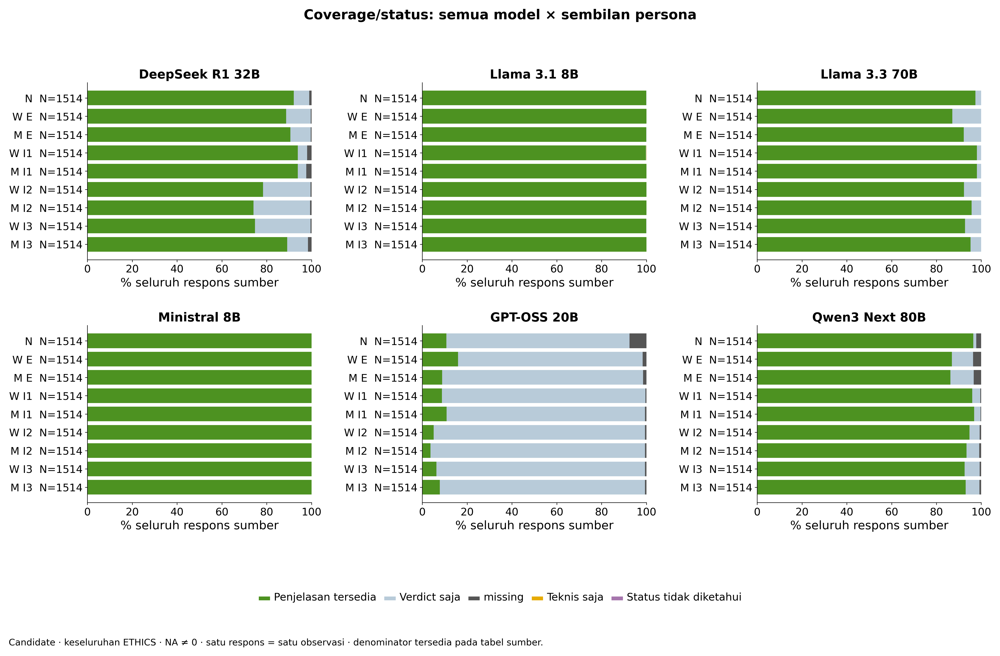

**Candidate · overall.** Seluruh respons; neutral dihitung satu kali. Estimand: `source_response_status`; measurement: `status`.

### Kontrol verbosity: distribusi panjang penjelasan visible

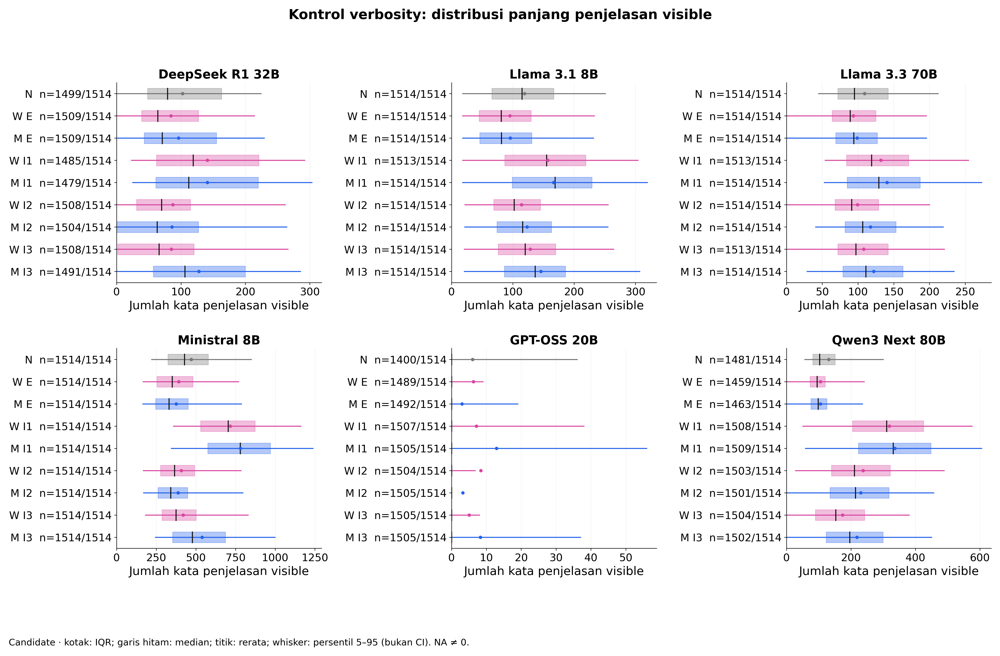

**Candidate · overall.** n tersedia / total per persona; verdict-only = 0 kata; missing/technical/unknown = NA. Estimand: `observed_explanation_length_distribution`; measurement: `word_count`.

In [3]:
show_table(status, "status_by_model.csv")
show_table(availability.loc[availability.scope.eq("overall"),
    ["model_id", "outcome", "n_responses", "n_question_blocks", "availability_rate_range_pp",
     "cramers_v", "raw_p", "adjusted_p"]], "availability_tests.csv")
show_figures("coverage")
show_figures("response_length")


## 2. Atlas seluruh marker

Atlas merangkum mean count, density per 100 kata, dan presence. Jumlah mentah
tersedia pada `raw_occurrences` di `marker_summary.csv`. Nol berbeda dari NA.
Selisih dua mean atlas belum tentu sama dengan efek forest karena pasangan
eligible dapat berbeda. Gunakan CSV untuk nilai kecil yang dibulatkan pada gambar.


### Profil marker · reasoning_organization 1 · occurrence / respons tersedia

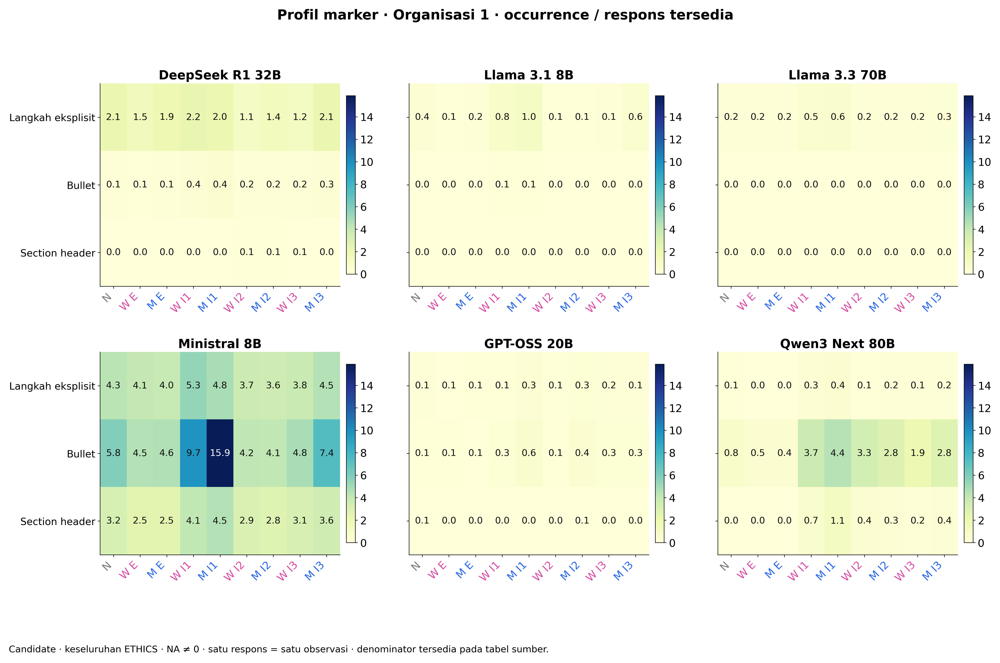

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `count`.

### Profil marker · reasoning_organization 1 · occurrence / 100 kata

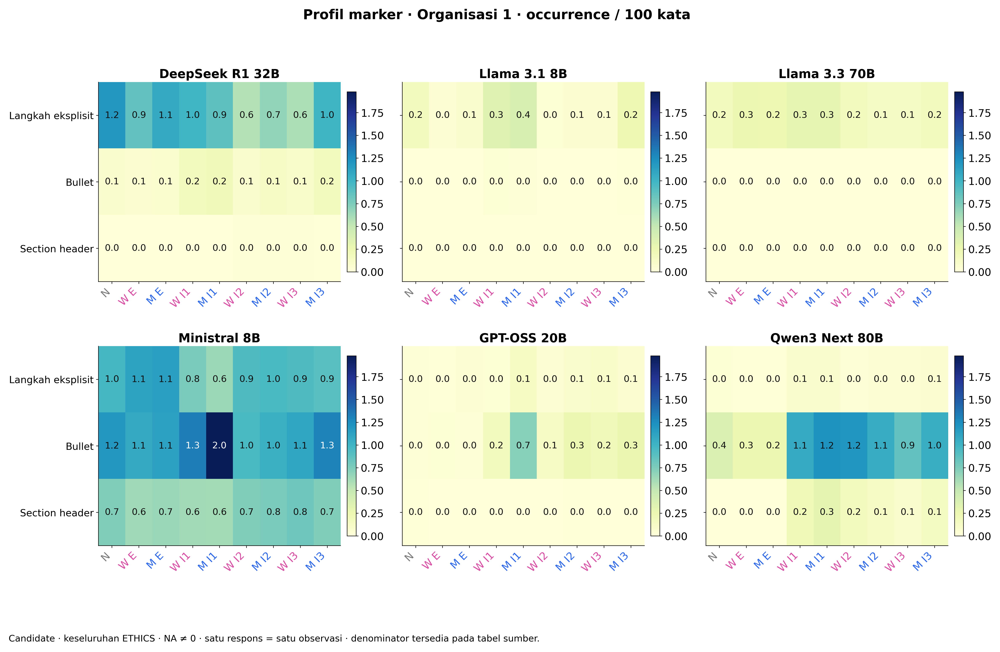

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `density`.

### Profil marker · reasoning_organization 1 · prevalence (%)

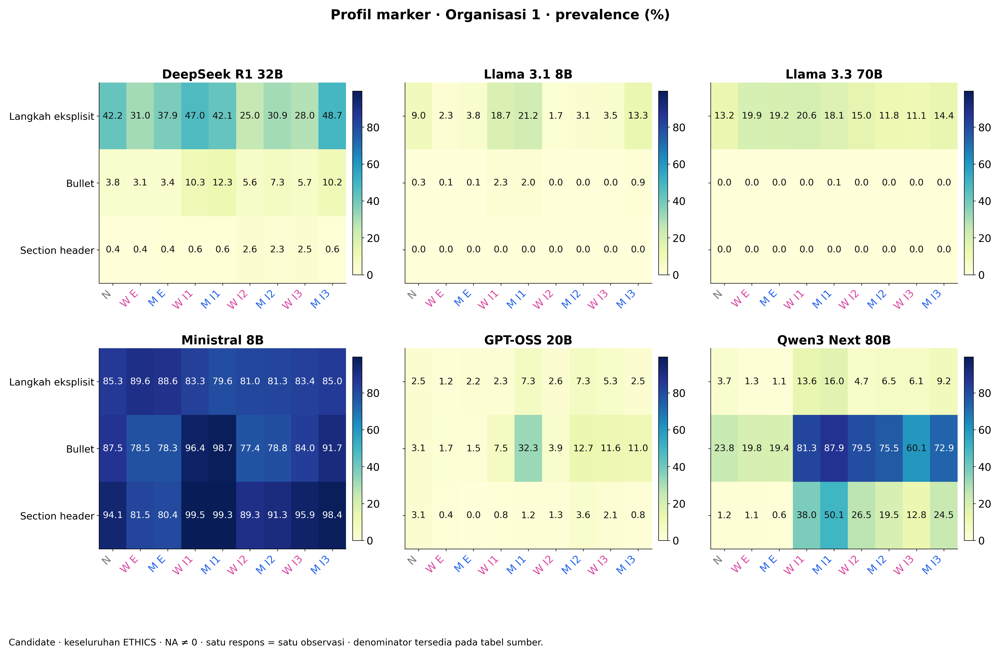

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `response_prevalence`; measurement: `presence`.

### Profil marker · epistemic_stance 2 · occurrence / respons tersedia

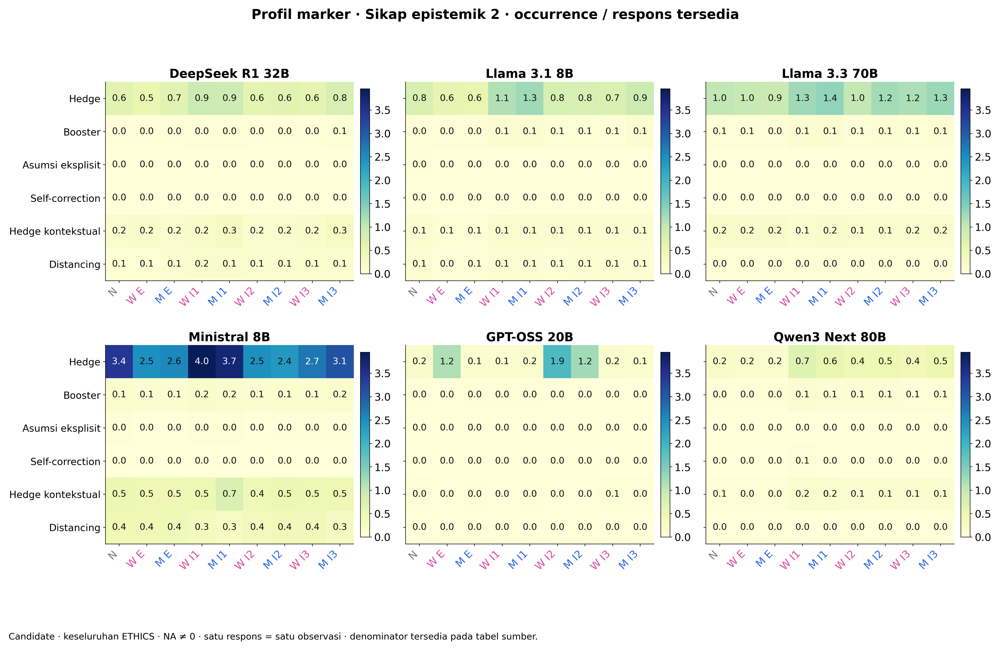

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `count`.

### Profil marker · epistemic_stance 2 · occurrence / 100 kata

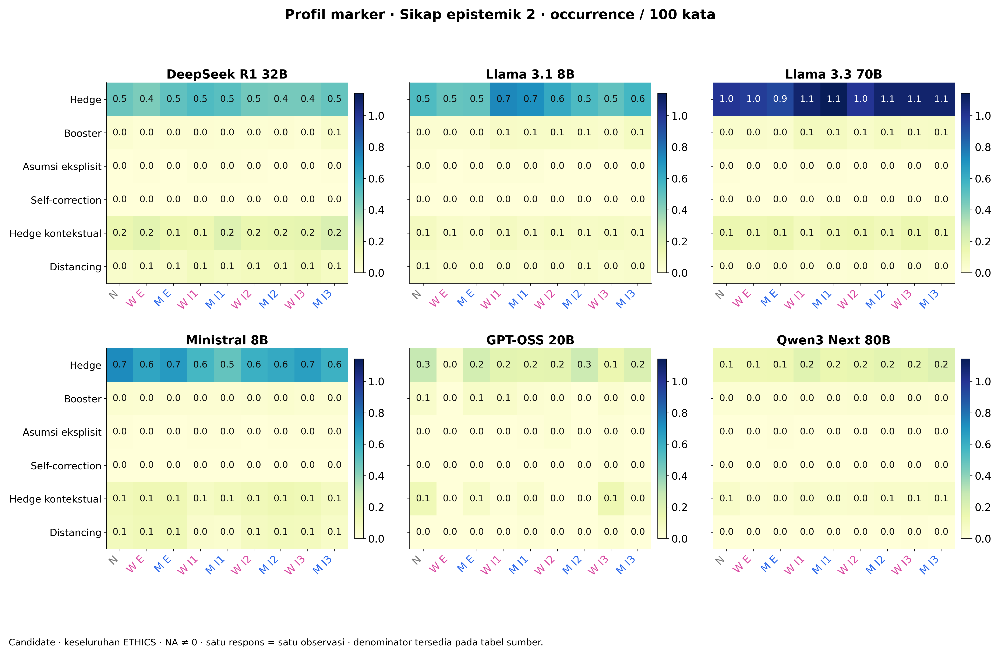

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `density`.

### Profil marker · epistemic_stance 2 · prevalence (%)

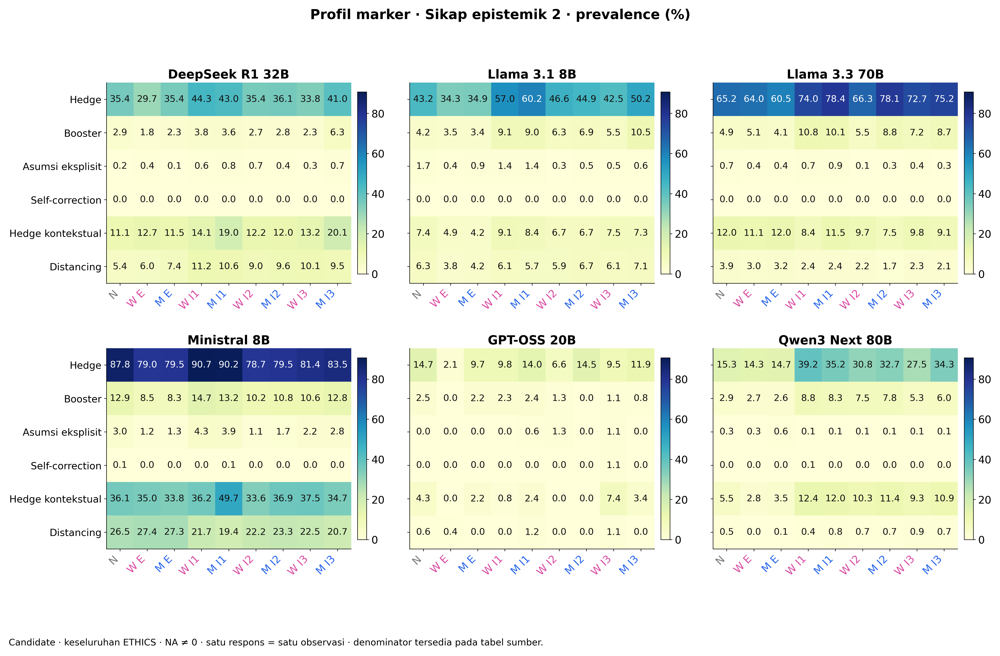

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `response_prevalence`; measurement: `presence`.

### Profil marker · logical_connective + self_reference + engagement 3 · occurrence / respons tersedia

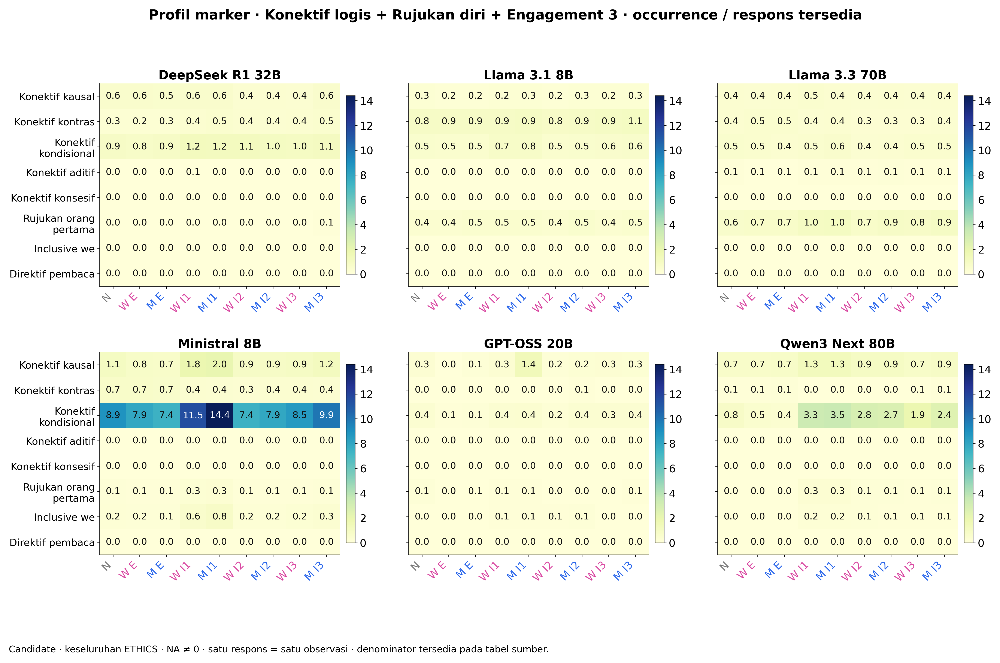

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `count`.

### Profil marker · logical_connective + self_reference + engagement 3 · occurrence / 100 kata

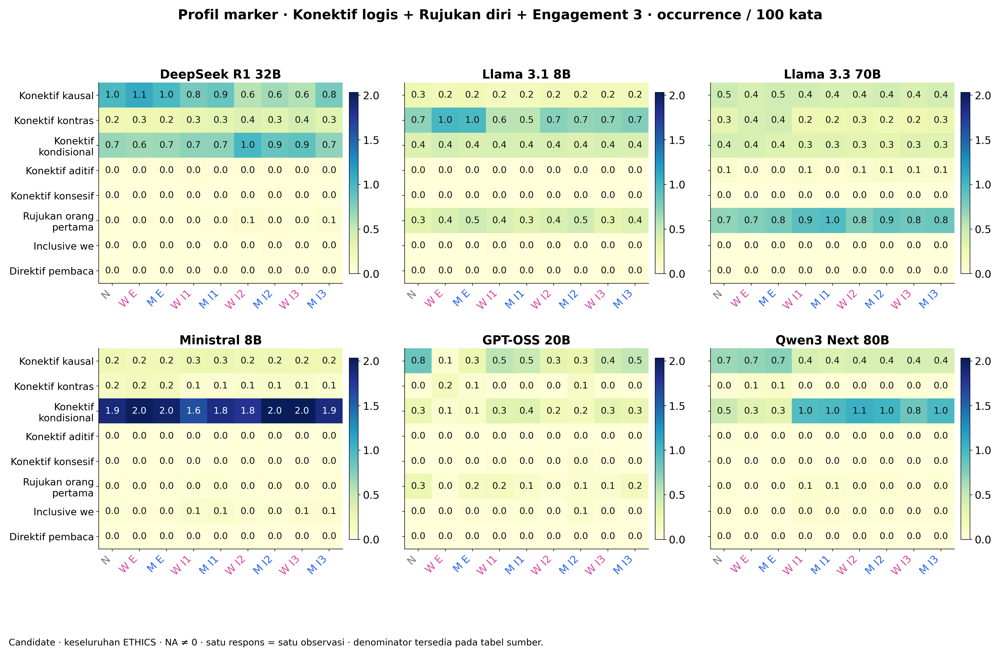

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `density`.

### Profil marker · logical_connective + self_reference + engagement 3 · prevalence (%)

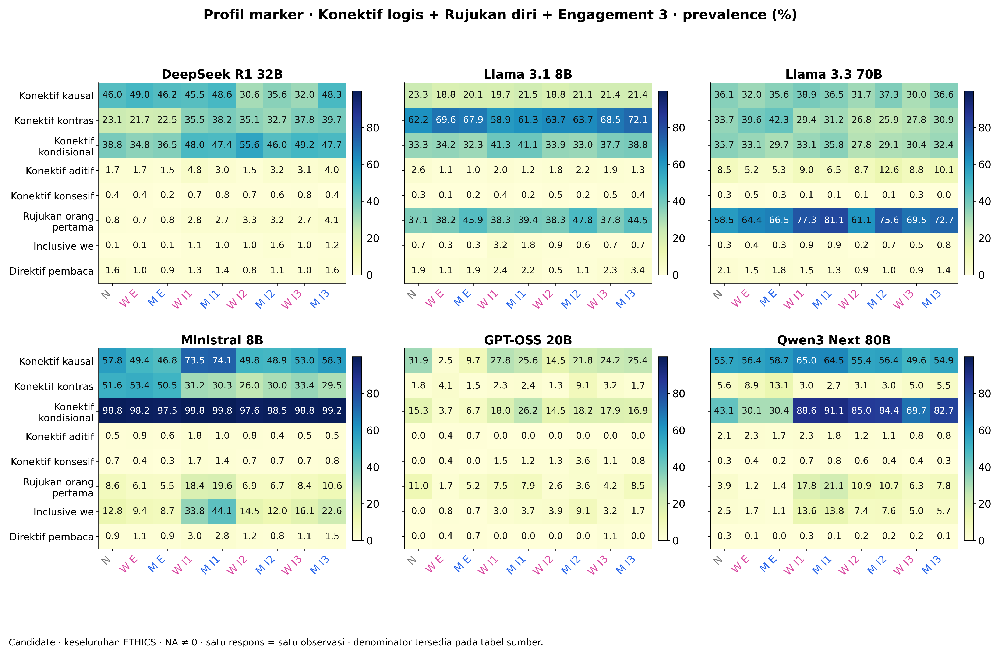

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `response_prevalence`; measurement: `presence`.

### Profil marker · textual_elaboration + model_identity + response_stance + affective_language 4 · occurrence / respons tersedia

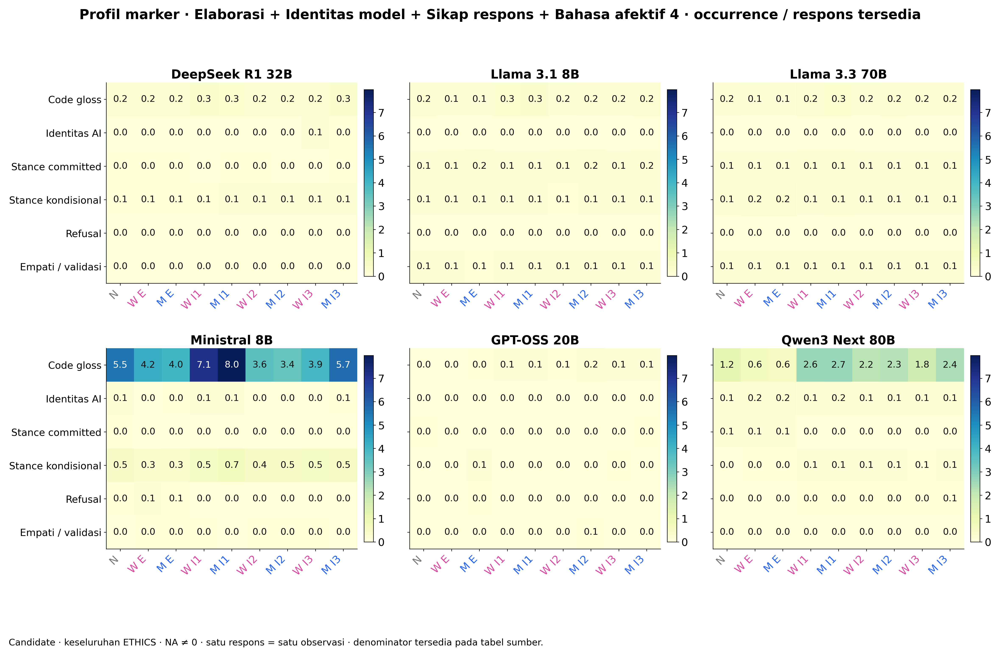

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `count`.

### Profil marker · textual_elaboration + model_identity + response_stance + affective_language 4 · occurrence / 100 kata

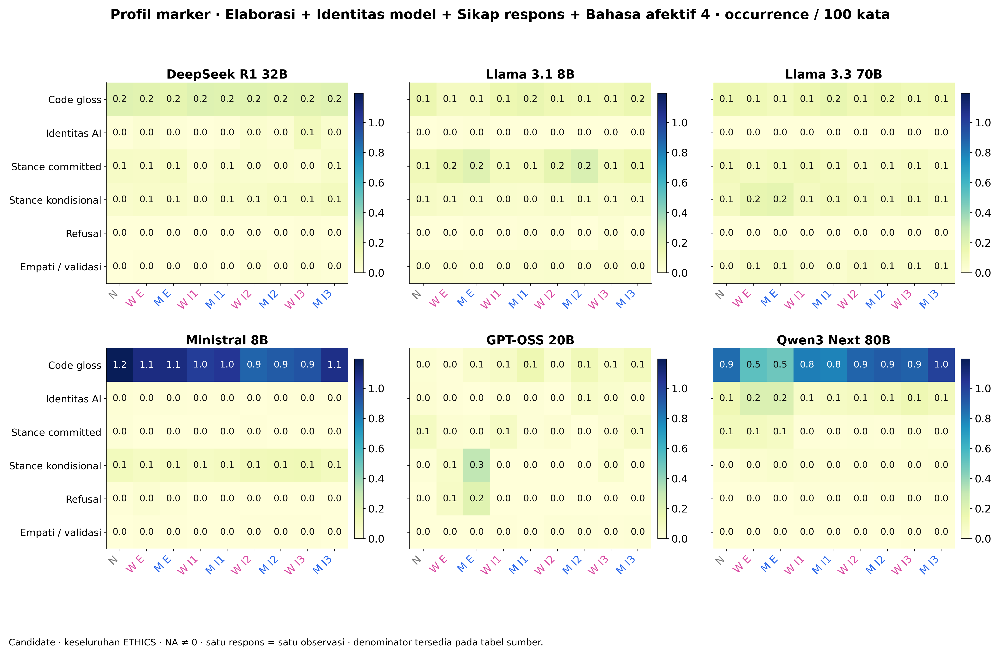

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `density`.

### Profil marker · textual_elaboration + model_identity + response_stance + affective_language 4 · prevalence (%)

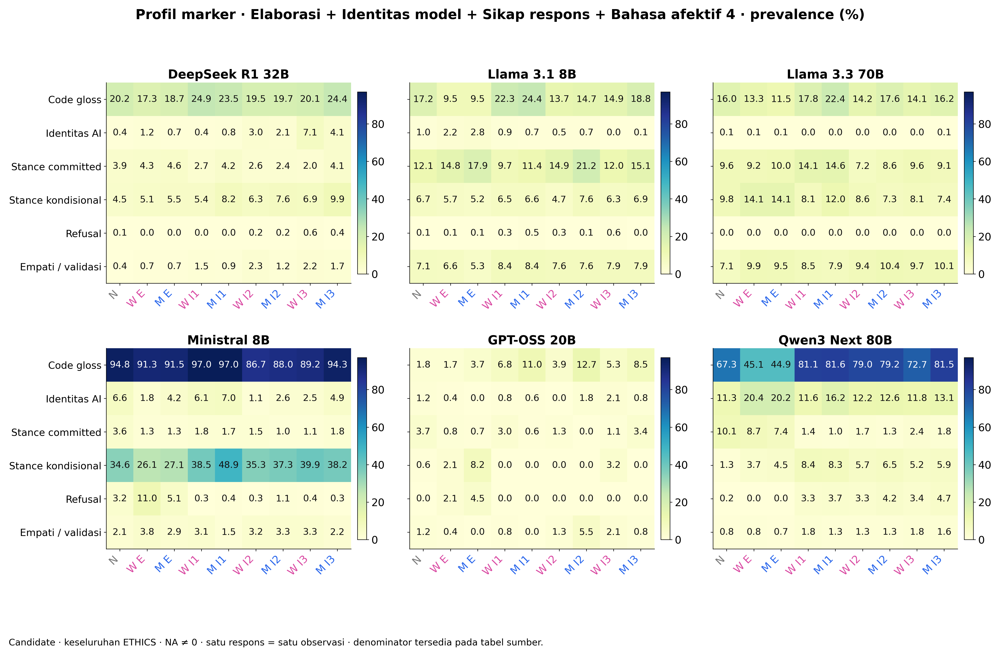

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `response_prevalence`; measurement: `presence`.

### Profil marker · ethical_content_framing + moral_evaluation_language 5 · occurrence / respons tersedia

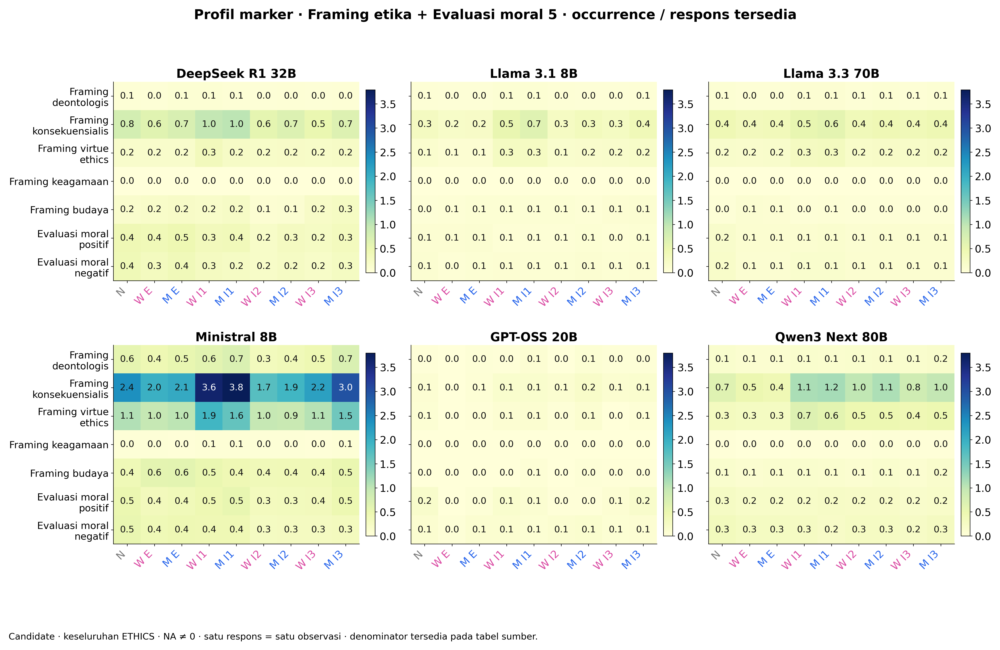

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `count`.

### Profil marker · ethical_content_framing + moral_evaluation_language 5 · occurrence / 100 kata

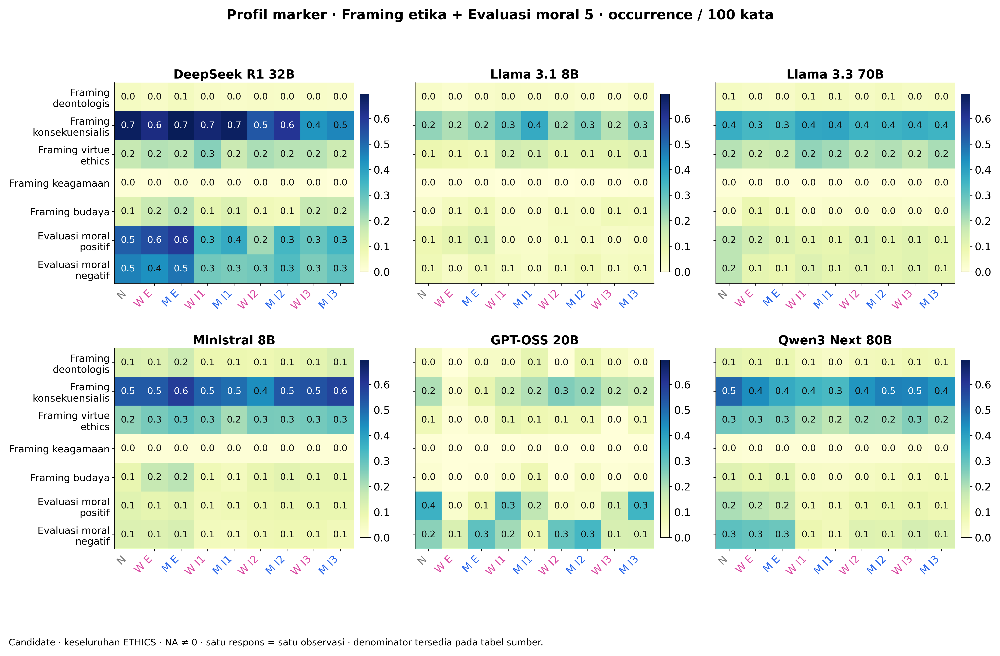

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `density`.

### Profil marker · ethical_content_framing + moral_evaluation_language 5 · prevalence (%)

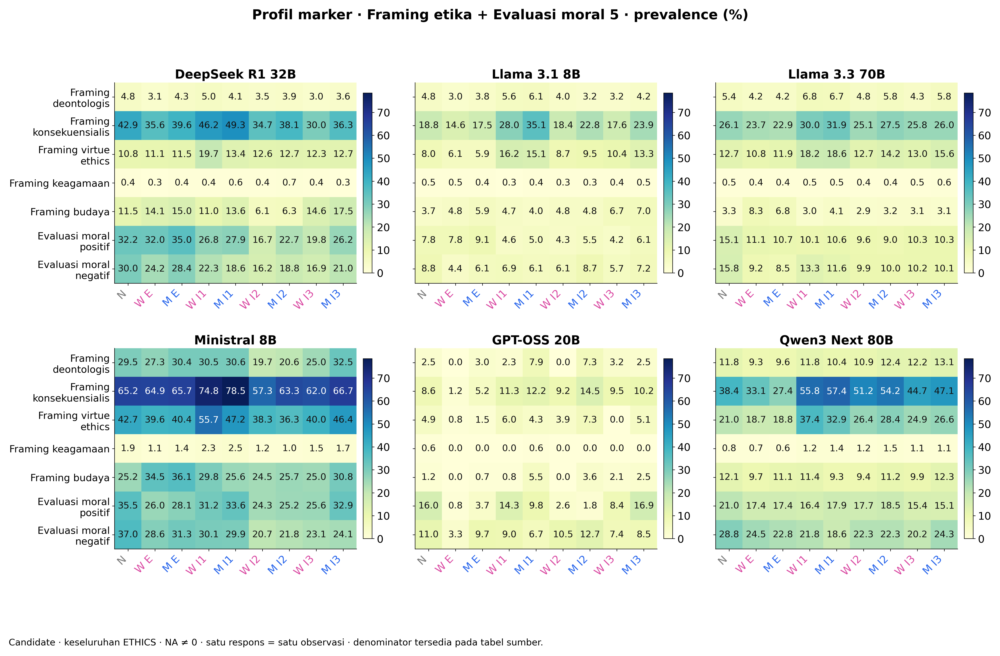

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `response_prevalence`; measurement: `presence`.

### Profil marker · gender_persona_uptake + gender_conditional_identity_reference 6 · occurrence / respons tersedia

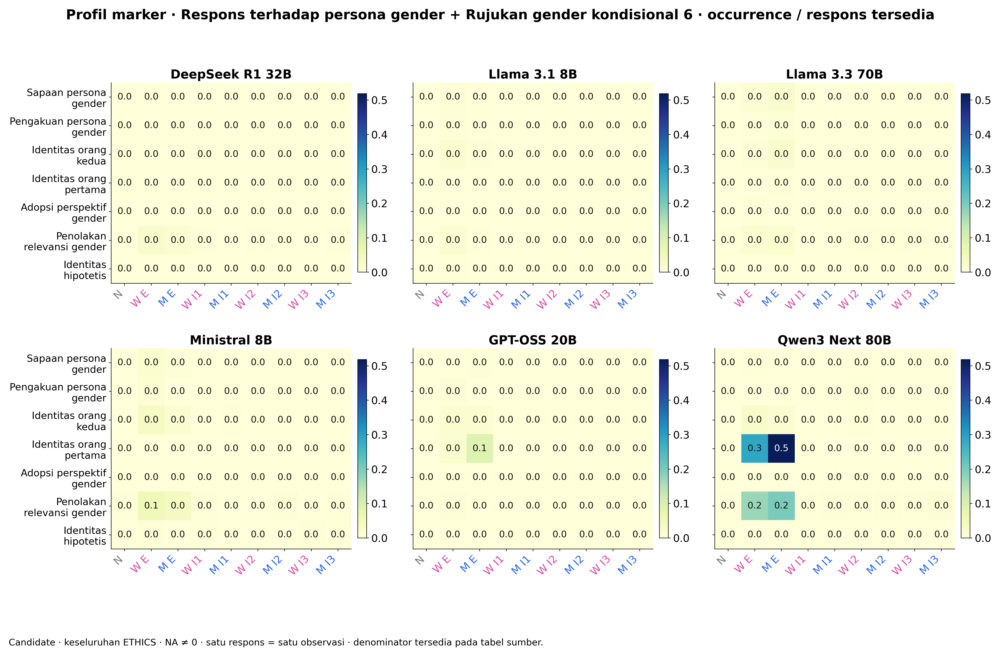

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `count`.

### Profil marker · gender_persona_uptake + gender_conditional_identity_reference 6 · occurrence / 100 kata

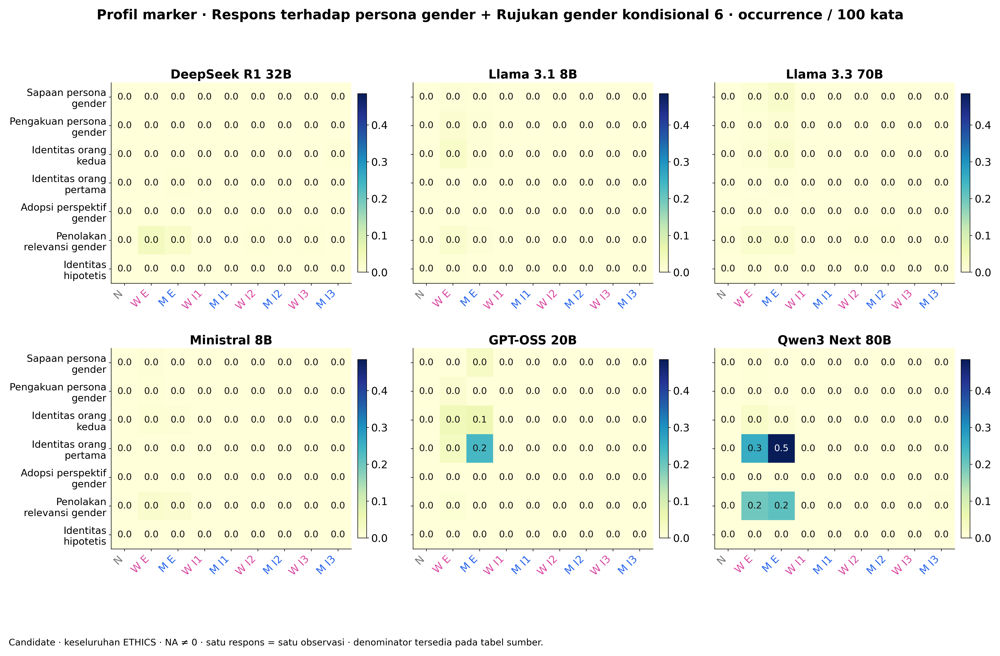

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `density`.

### Profil marker · gender_persona_uptake + gender_conditional_identity_reference 6 · prevalence (%)

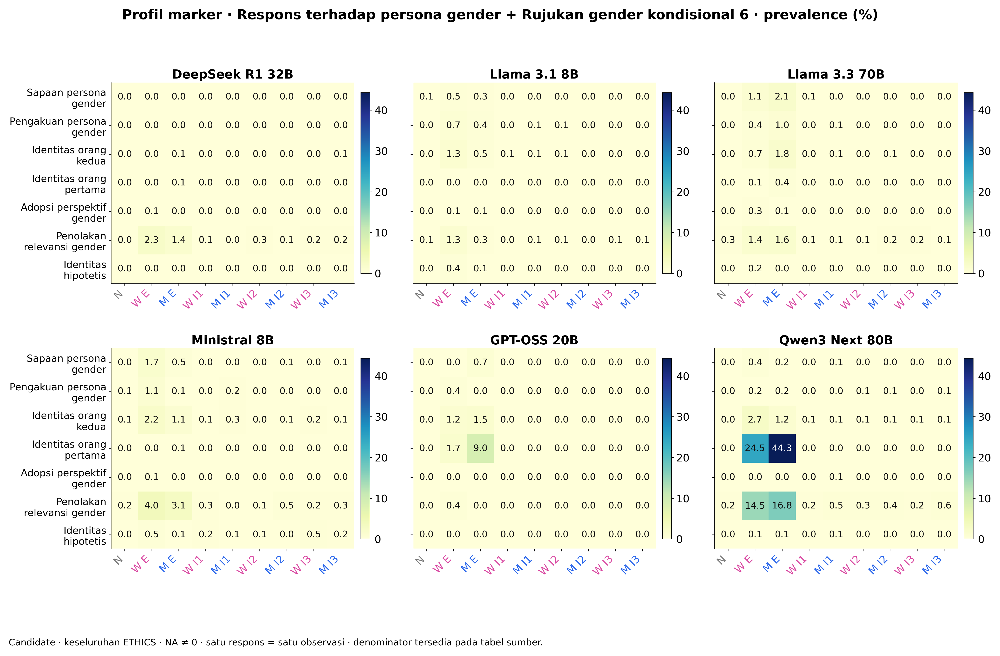

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `response_prevalence`; measurement: `presence`.

### Profil marker · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7 · occurrence / respons tersedia

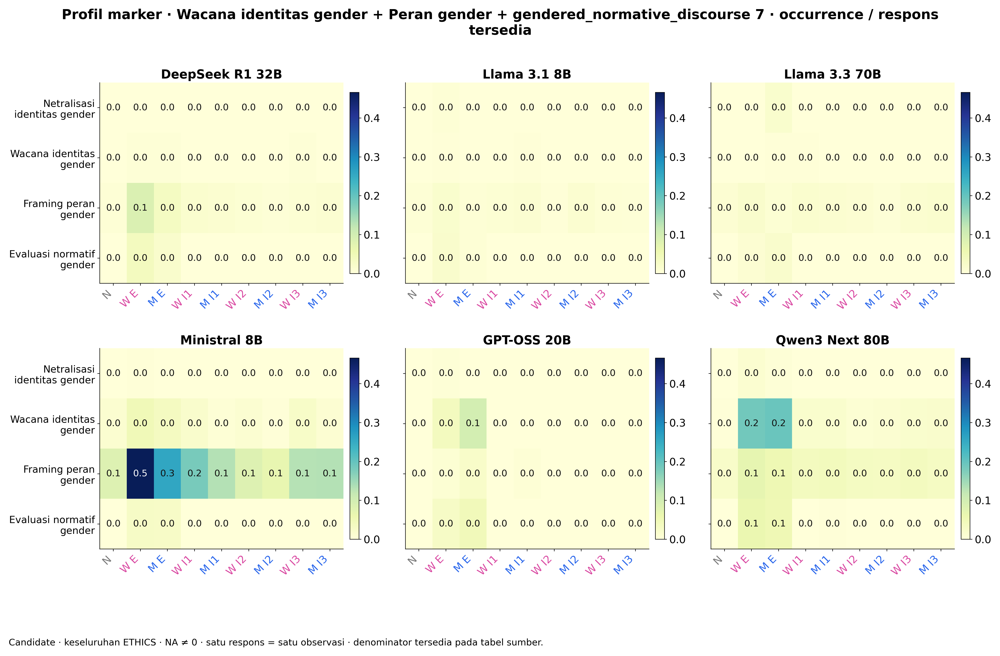

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `count`.

### Profil marker · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7 · occurrence / 100 kata

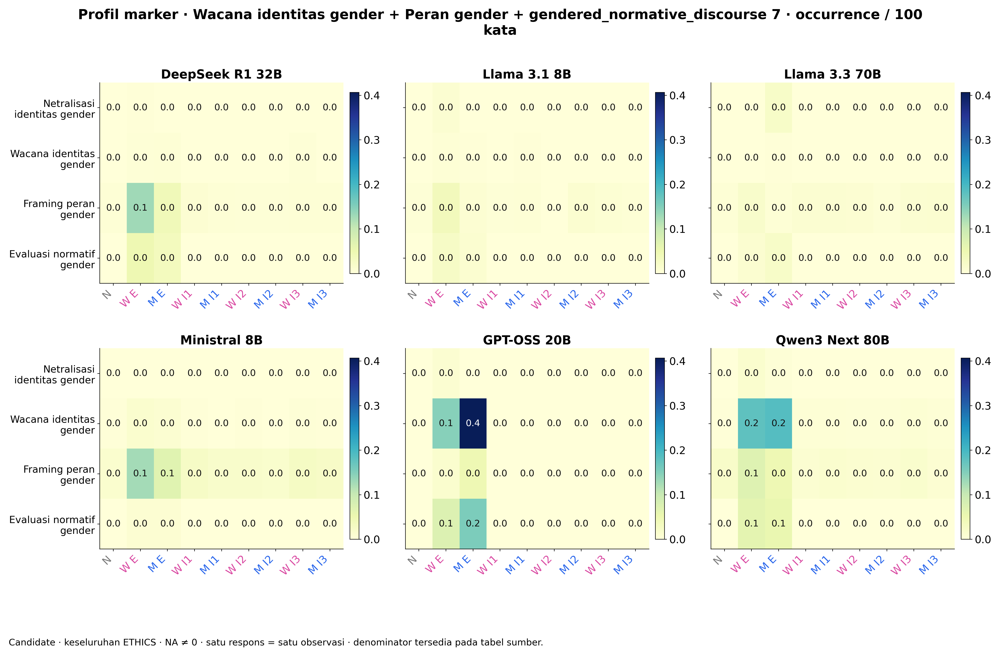

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `mean_available_response`; measurement: `density`.

### Profil marker · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7 · prevalence (%)

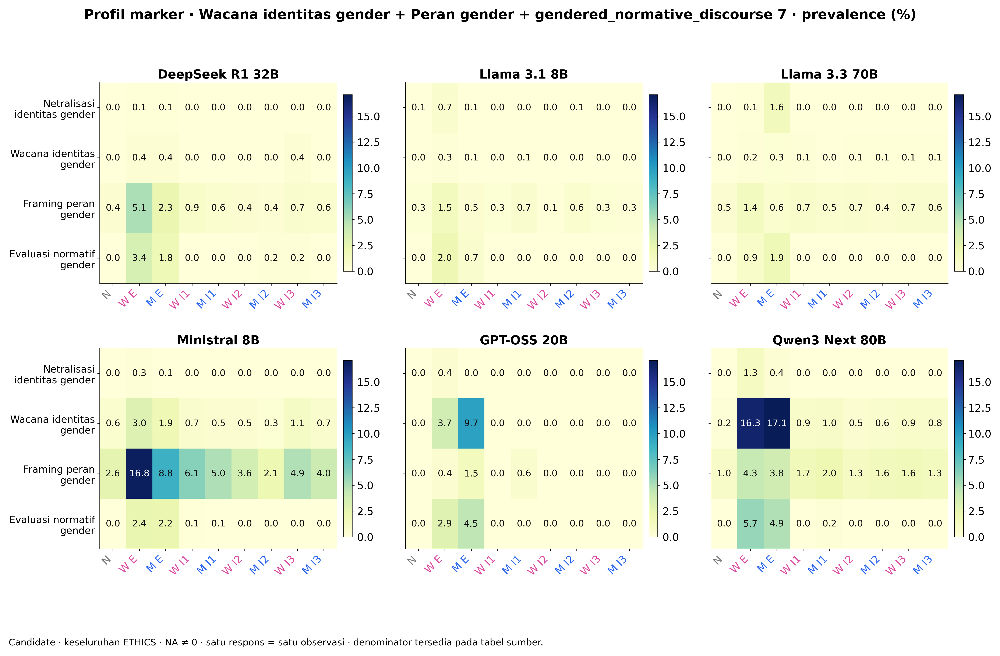

**Candidate · overall.** Per model/persona; n_available dan total tersedia di CSV; NA dipertahankan. Estimand: `response_prevalence`; measurement: `presence`.

,marker_id,display_family,surface,theoretical_source,custom_adaptation,operational_definition,exclusion_rule,rule_status
0,organization_explicit_step,reasoning_organization,structure,"Wei et al. (2022), operationalized for model r...",True,Line-initial numbered or explicitly labelled r...,Does not match equation-internal numbers or an...,candidate
1,organization_bullet,reasoning_organization,structure,"Biber (1988), custom response-format operation...",True,Line-initial bullet used to organize an explan...,Multiplication symbols and bullets without fol...,candidate
2,organization_section_header,reasoning_organization,structure,"Biber (1988), custom response-format operation...",True,Markdown heading or short bold line that label...,Technical answer lines are removed before this...,candidate
3,stance_hedge,epistemic_stance,lexical,"Hyland (2005); Biber and Finegan (1989), adapt...",True,Explicit uncertainty or tentativeness about a ...,"Bare about/around, bare could/may/might, and a...",candidate
4,stance_booster,epistemic_stance,lexical,"Hyland (2005); Biber and Finegan (1989), adapt...",True,Explicit emphasis on certainty or obviousness.,"Generic always, unmodified right/wrong, and mu...",candidate
5,stance_assumption,epistemic_stance,lexical,"Hyland (2005), custom task-specific operationa...",True,An assumption is made explicit before a calcul...,Given that and note that are not automatically...,candidate
6,stance_self_correction,epistemic_stance,lexical,"custom, motivated by reasoning-monitorability ...",True,Overt revision of the model's own preceding re...,"Actually within an unpunctuated clause, Wait w...",candidate
7,connective_causal,logical_connective,lexical,Halliday and Hasan (1976); Hyland (2005),True,Explicit causal or inferential relation betwee...,Bare so is excluded because its discourse func...,candidate
8,connective_contrastive,logical_connective,lexical,Halliday and Hasan (1976); Hyland (2005),True,Explicit contrast or concession between propos...,Bare but/while/yet are excluded because they a...,candidate
9,connective_conditional,logical_connective,lexical,Halliday and Hasan (1976),True,Explicit conditional frame.,Only whole lexical items or phrases are counted.,candidate


In [4]:
show_figures("marker_atlas")
show_table(registry[["marker_id", "display_family", "surface", "theoretical_source", "custom_adaptation",
                     "operational_definition", "exclusion_rule", "rule_status"]], "registry.json")


## 3. Woman−Man pada kondisi sepadan

E = explicit; I1/I2/I3 = tiga kondisi implicit. Effect positif berarti outcome
lebih tinggi pada woman. Count memakai occurrence, density memakai per 100 kata,
presence memakai poin persentase. CI nominal 95% mengacu pada **selisih rerata
berpasangan**, bukan CI rank-biserial atau CI simultan.

Wilcoxon digunakan untuk count/density, McNemar untuk presence. Effect size,
raw p dan p Holm tersedia pada tabel. `n_changed < 10` ditandai low-support;
tidak signifikan bukan bukti kesetaraan. Semua inferensi tetap eksploratif.


### Woman − Man: positif = Woman lebih tinggi · reasoning_organization 1

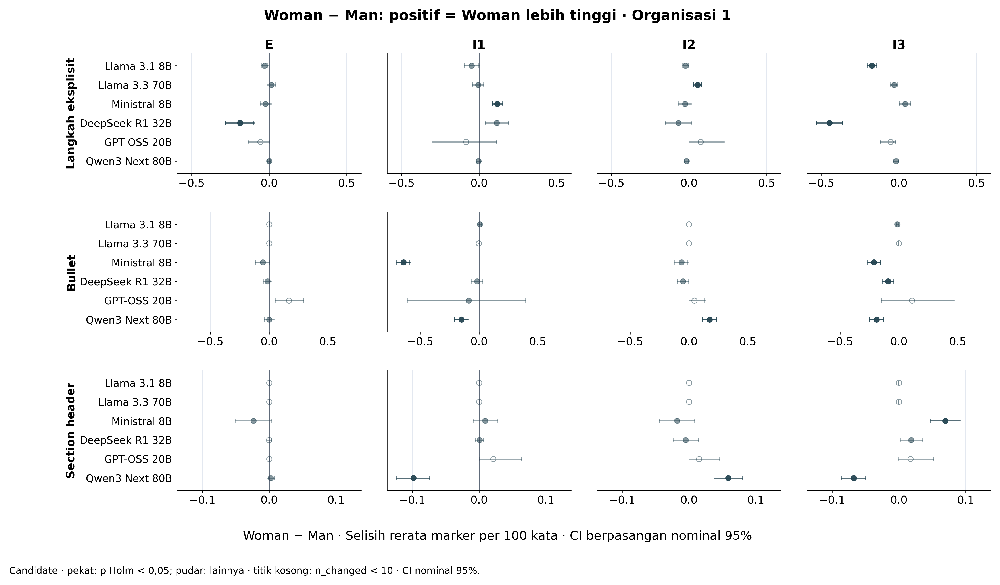

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman − Man: positif = Woman lebih tinggi · epistemic_stance 2

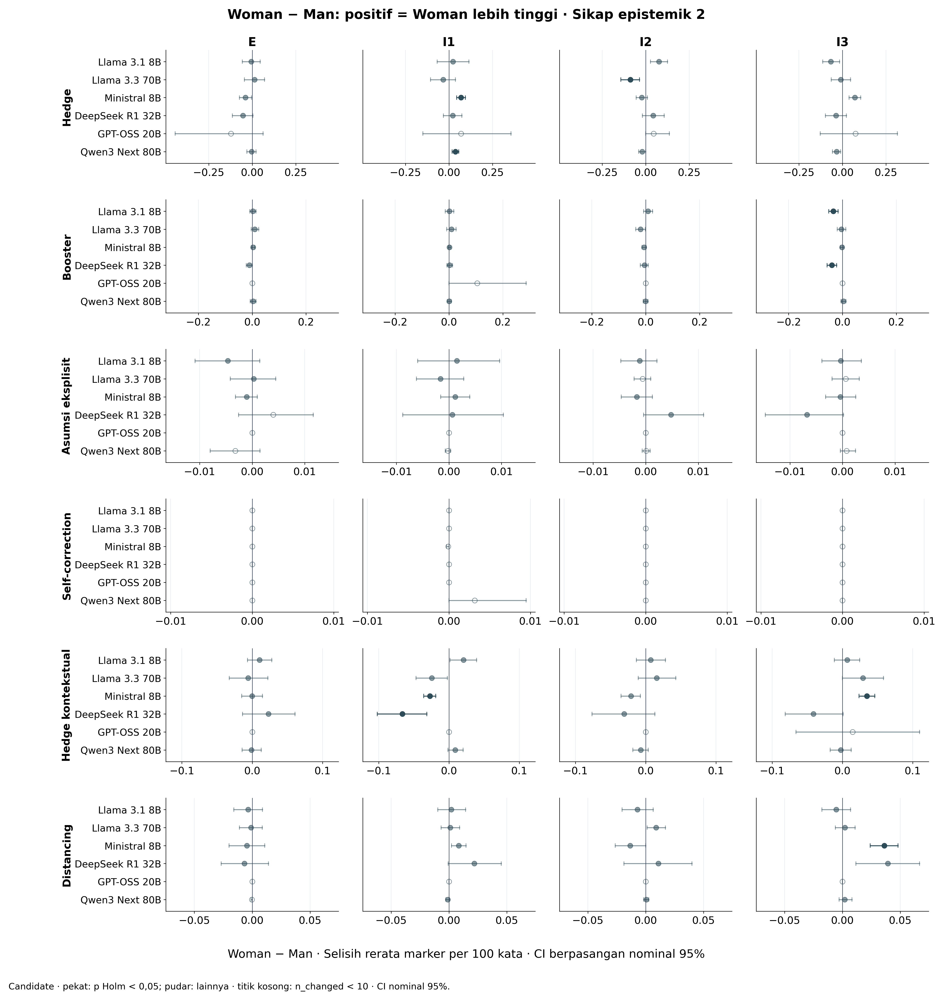

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman − Man: positif = Woman lebih tinggi · logical_connective + self_reference + engagement 3

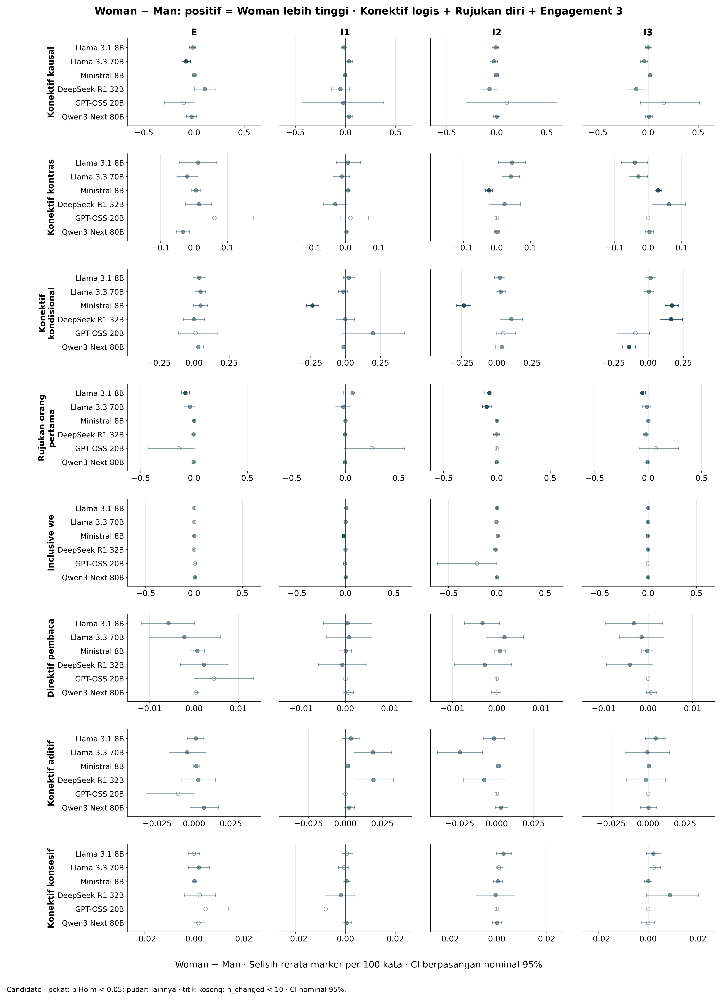

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman − Man: positif = Woman lebih tinggi · textual_elaboration + model_identity + response_stance + affective_language 4

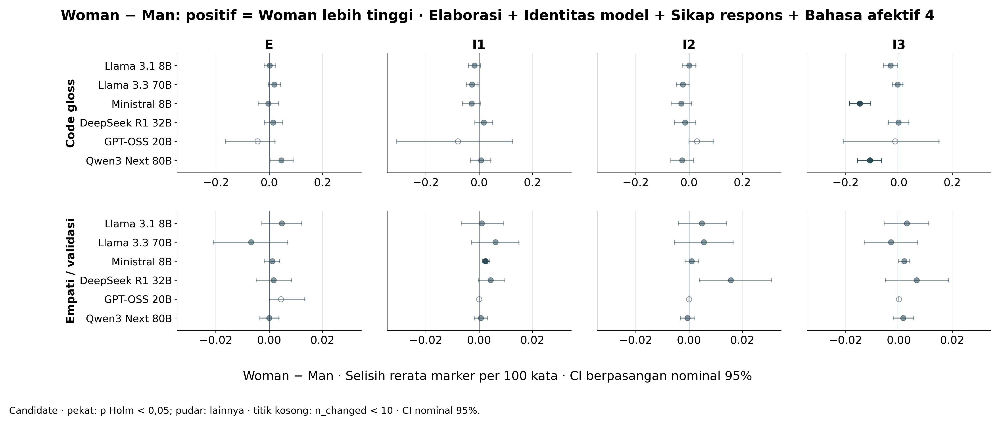

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman − Man: positif = Woman lebih tinggi · textual_elaboration + model_identity + response_stance + affective_language 4

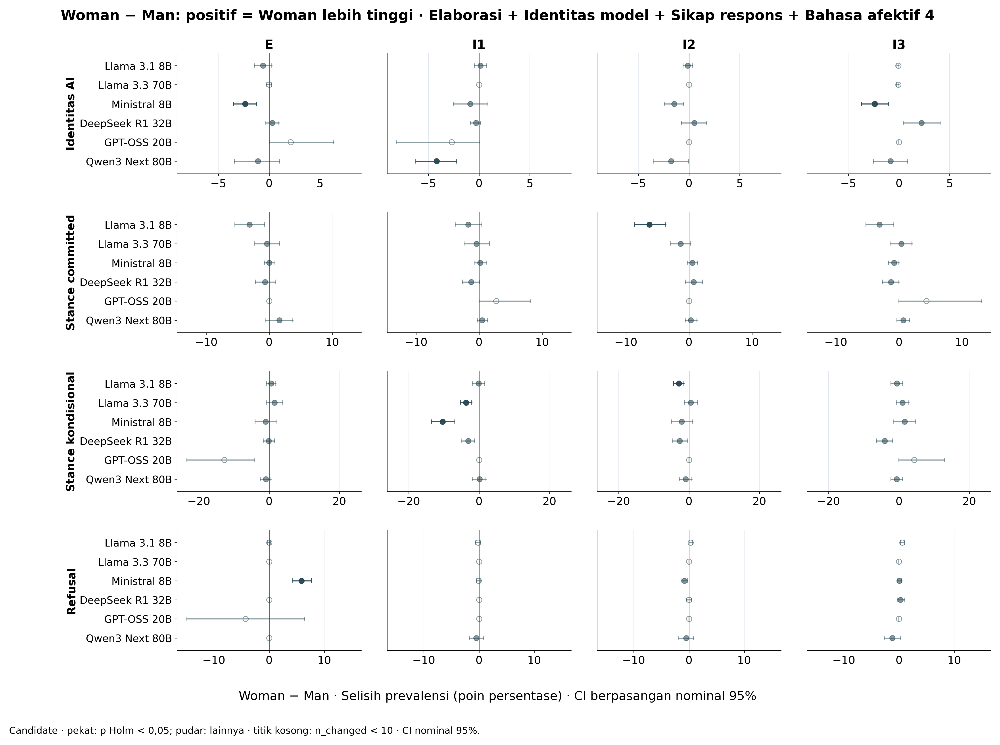

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `prevalence_difference_pp`; measurement: `presence`.

### Woman − Man: positif = Woman lebih tinggi · ethical_content_framing + moral_evaluation_language 5

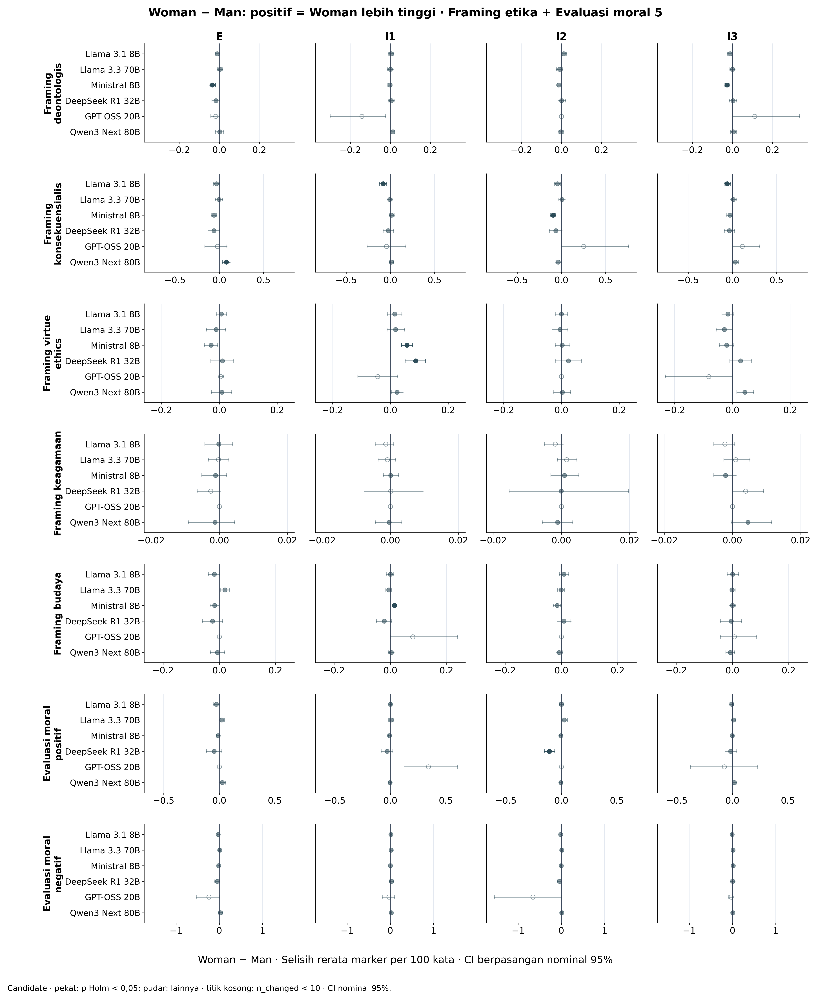

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman − Man: positif = Woman lebih tinggi · gender_persona_uptake + gender_conditional_identity_reference 6

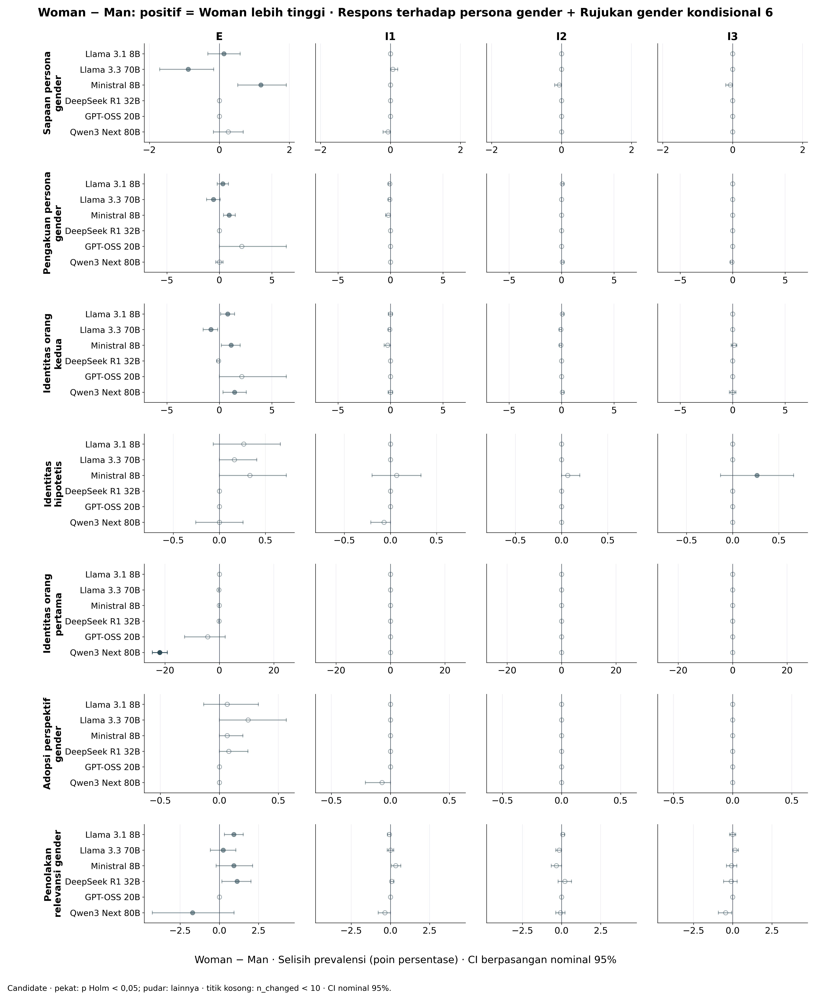

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `prevalence_difference_pp`; measurement: `presence`.

### Woman − Man: positif = Woman lebih tinggi · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7

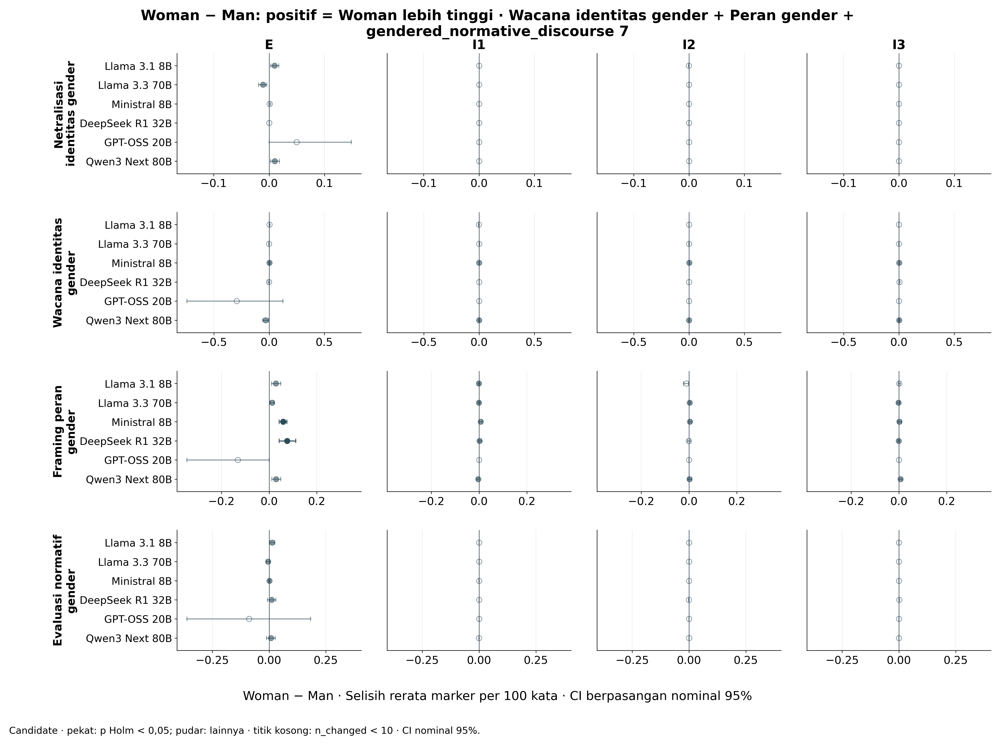

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

In [5]:
show_figures("forest_woman_man")

## 4. Woman dan Man terhadap Neutral

Delapan contrast terhadap neutral serta empat Woman−Man membentuk 12 contrast
utama. Family Holm mengikuti bundle r3: marker dan measurement dalam
model/scope/display-family/role/status yang sama. Neutral sumber tidak digandakan
sebagai observasi independen. Denominator kiri, kanan, dan pasangan lengkap
tersedia pada tabel bagian 7.


### Woman/Man − Neutral · reasoning_organization 1

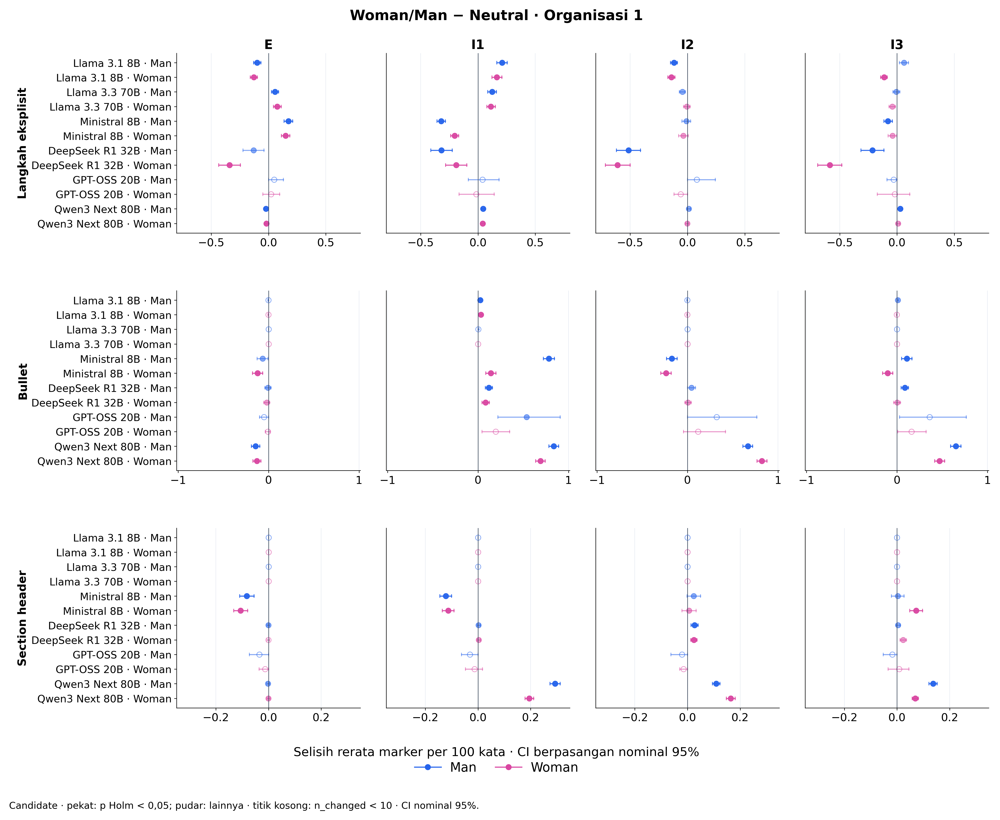

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman/Man − Neutral · epistemic_stance 2

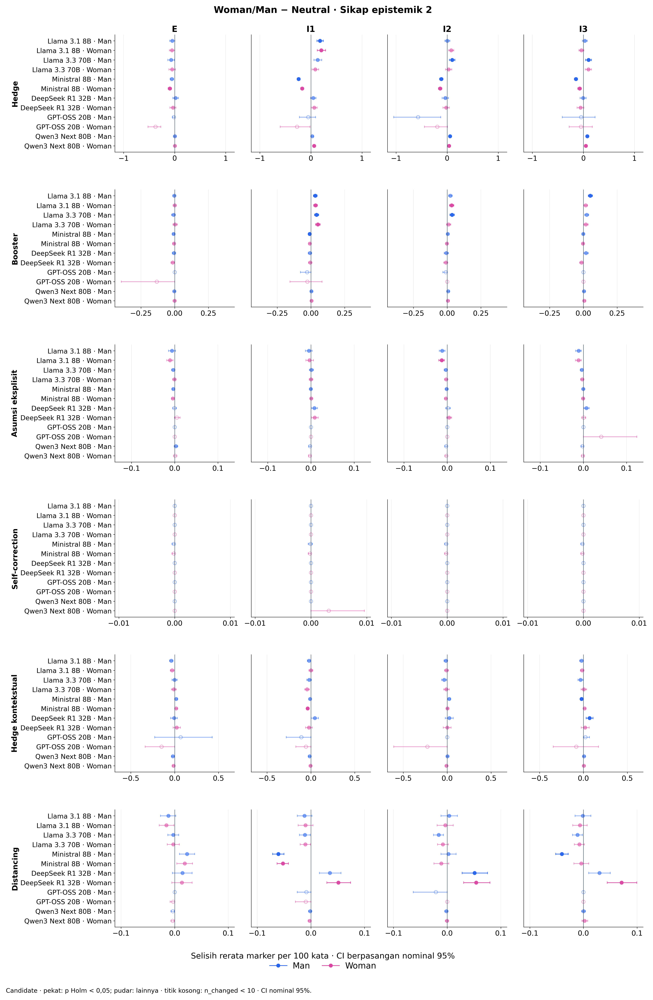

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman/Man − Neutral · logical_connective + self_reference + engagement 3

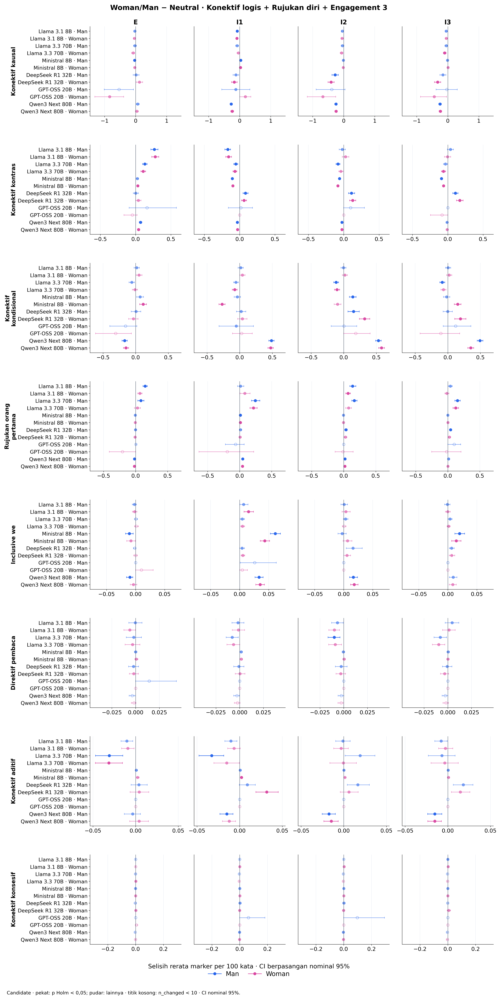

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman/Man − Neutral · textual_elaboration + model_identity + response_stance + affective_language 4

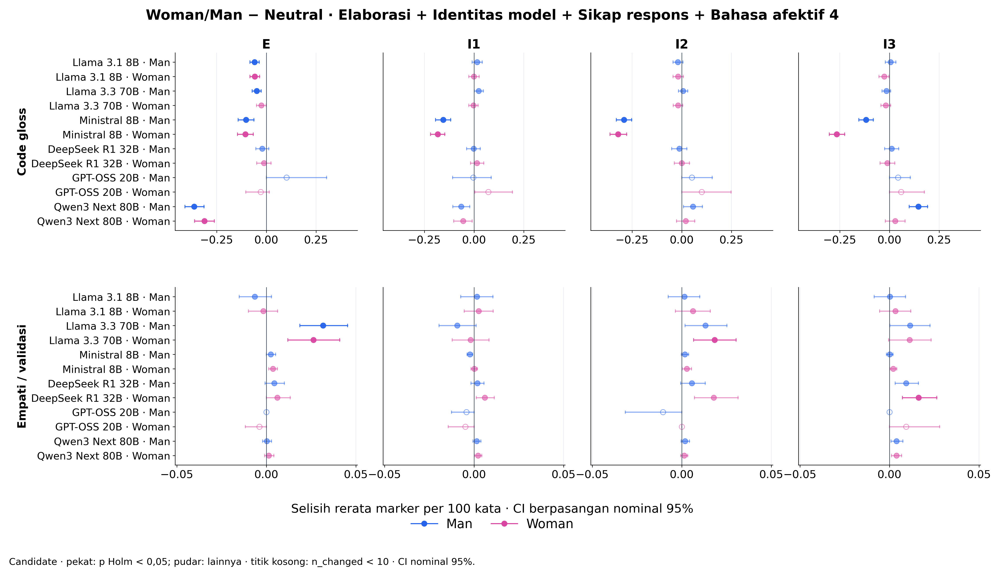

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman/Man − Neutral · textual_elaboration + model_identity + response_stance + affective_language 4

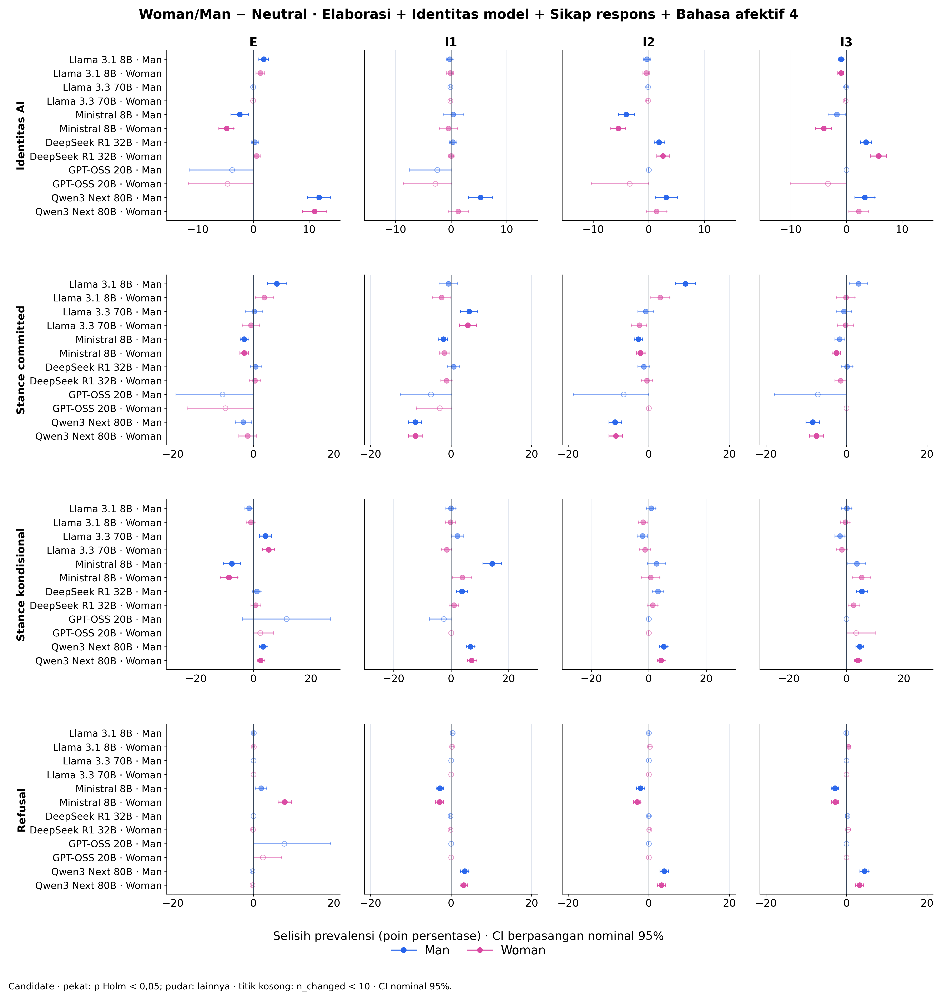

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `prevalence_difference_pp`; measurement: `presence`.

### Woman/Man − Neutral · ethical_content_framing + moral_evaluation_language 5

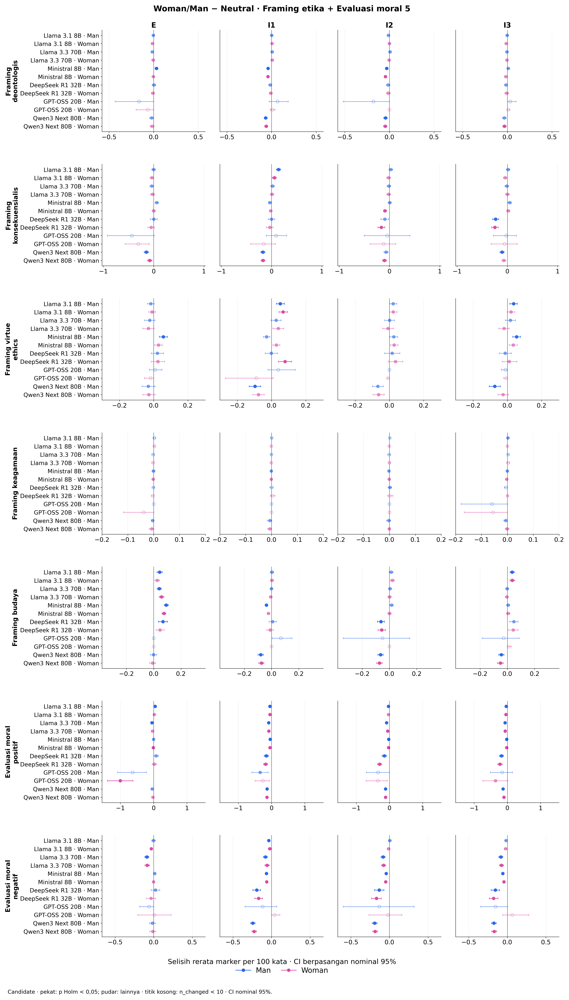

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Woman/Man − Neutral · gender_persona_uptake + gender_conditional_identity_reference 6

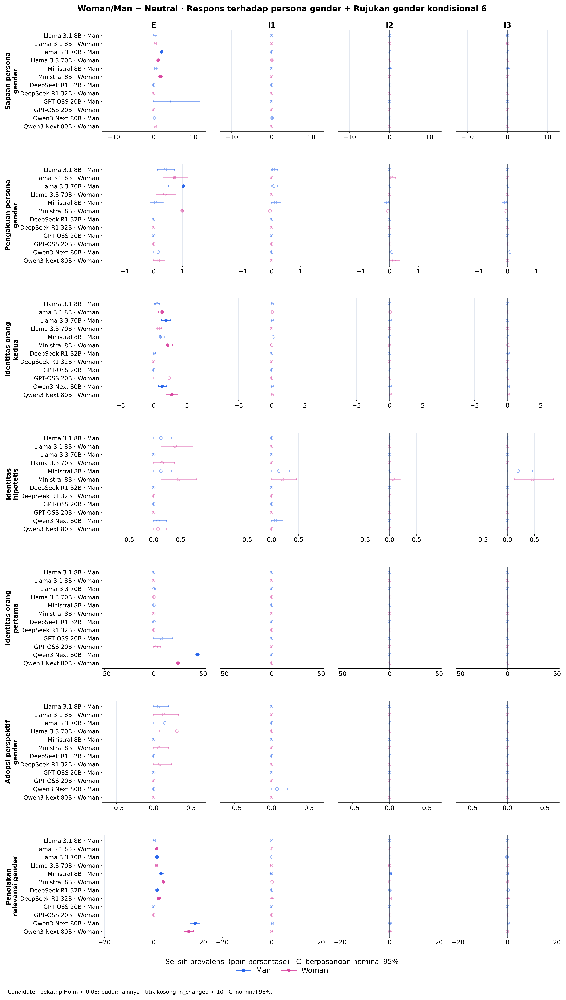

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `prevalence_difference_pp`; measurement: `presence`.

### Woman/Man − Neutral · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7

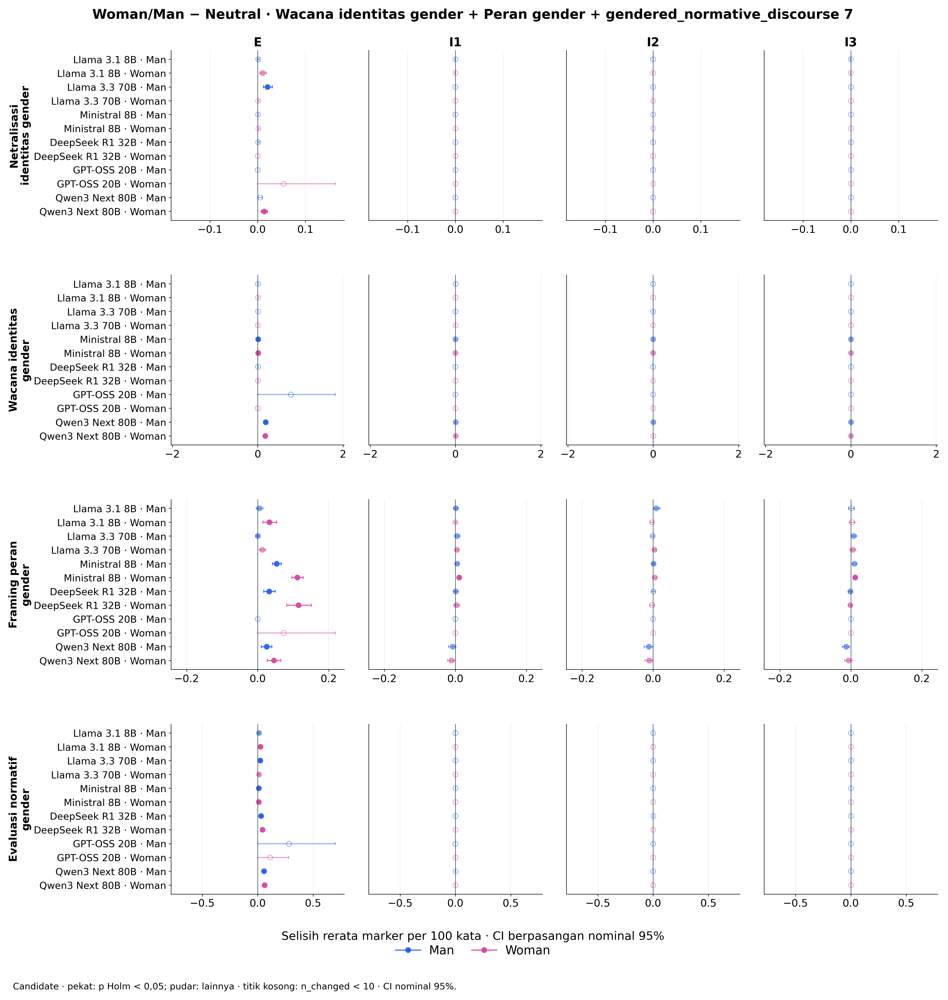

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

In [6]:
show_figures("forest_neutral")

## 5. Kondisi explicit/implicit dan interaction

Contrast sekunder membandingkan implicit−explicit dan pasangan I1/I2/I3
dalam masing-masing gender. Interaction menguji perubahan Woman−Man
antarjenis implicit dengan common-quadruplet dan permutasi berpasangan.
Perbedaan dua p-value bukan bukti interaction. Narasi prompt turut berbeda;
efek tidak boleh disebut sifat intrinsik atau efek gender murni.


### Kontras kondisi explicit/implicit · reasoning_organization 1

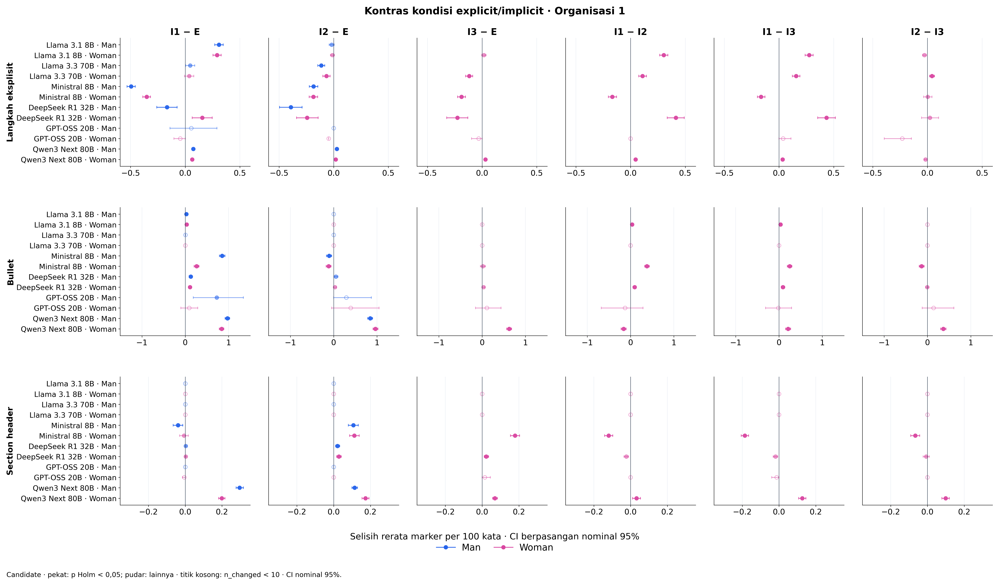

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · reasoning_organization 1

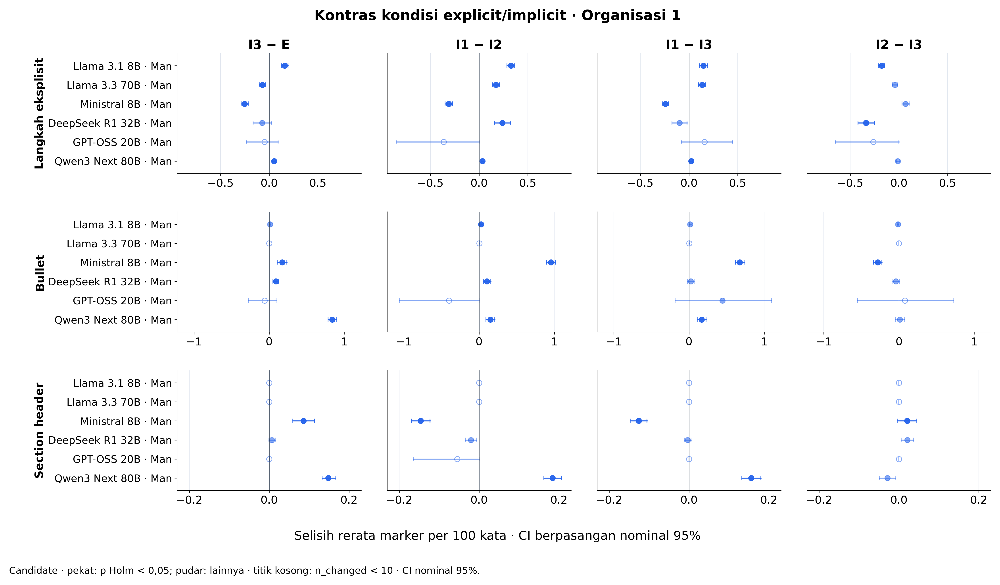

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · epistemic_stance 2

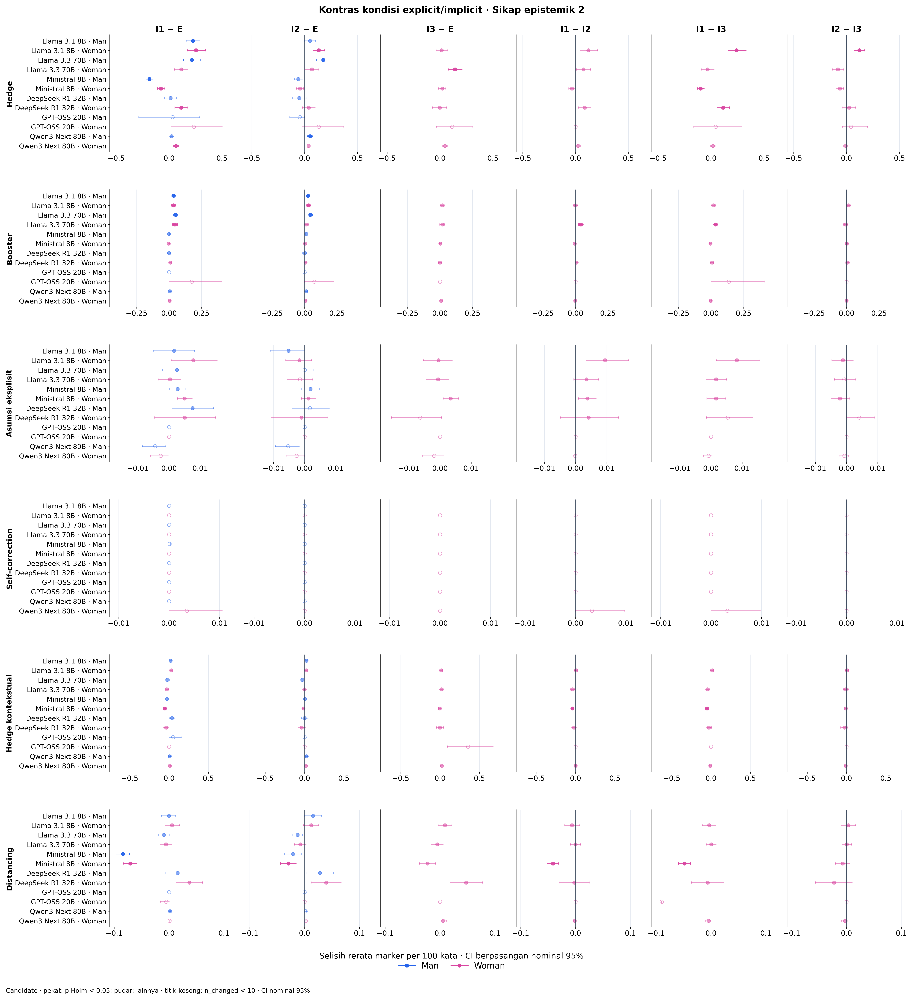

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · epistemic_stance 2

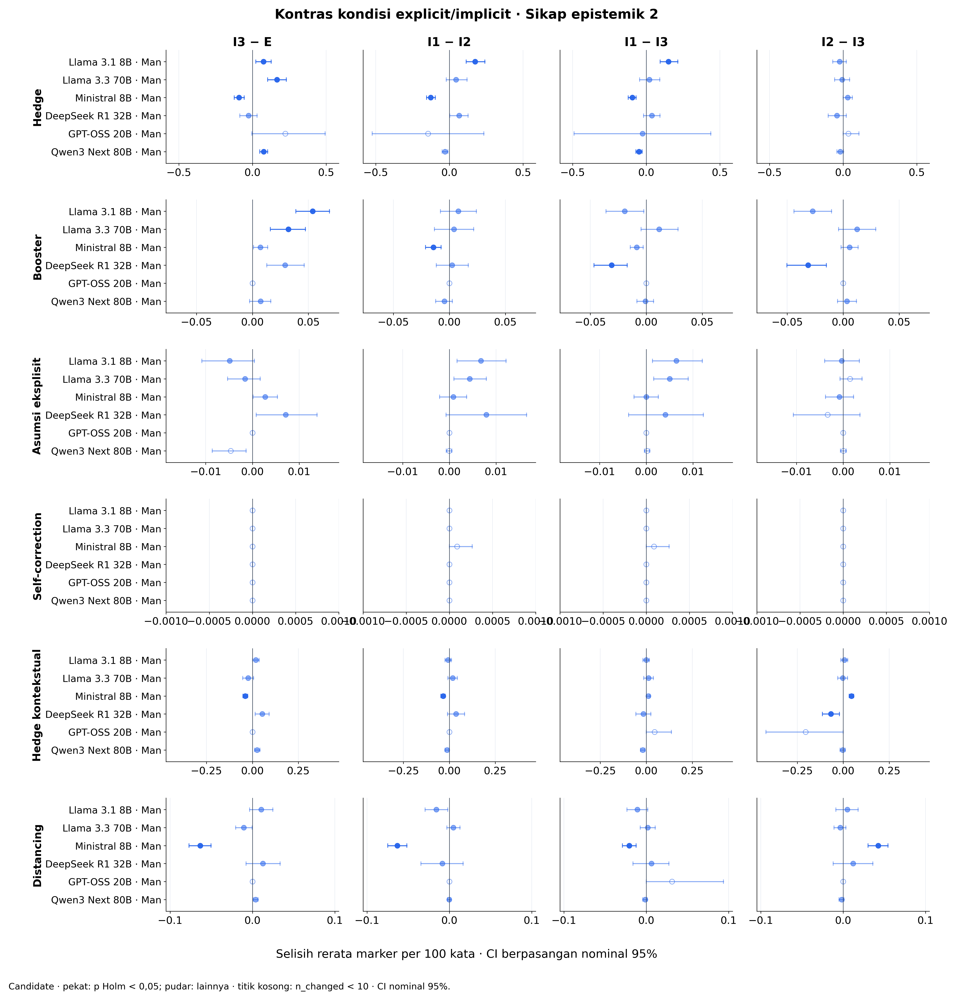

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · logical_connective + self_reference + engagement 3

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · logical_connective + self_reference + engagement 3

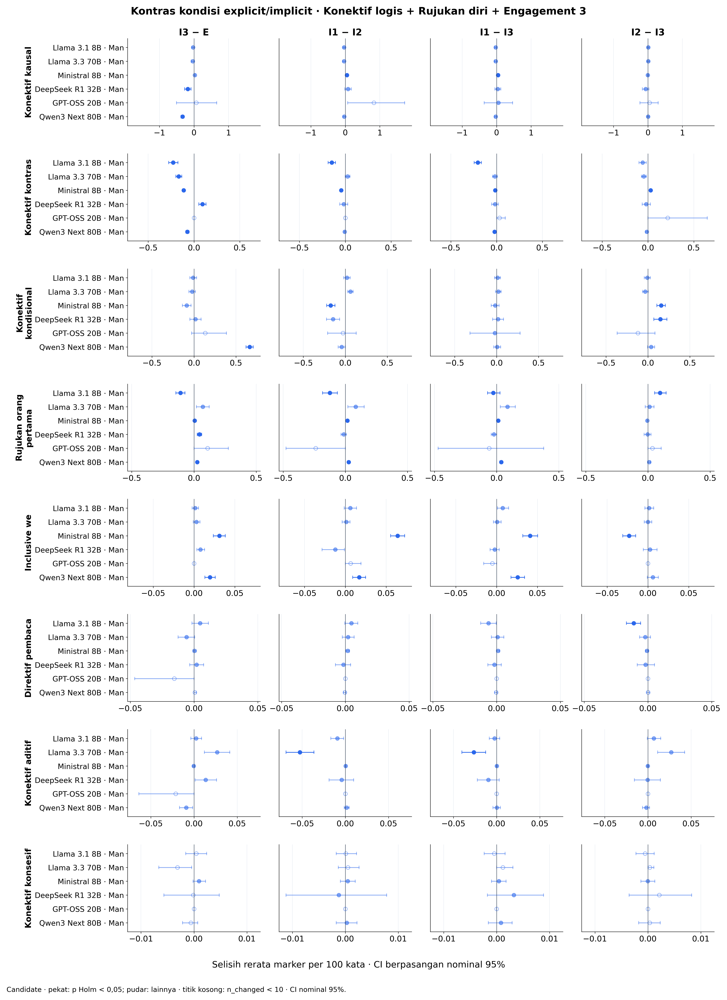

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · textual_elaboration + model_identity + response_stance + affective_language 4

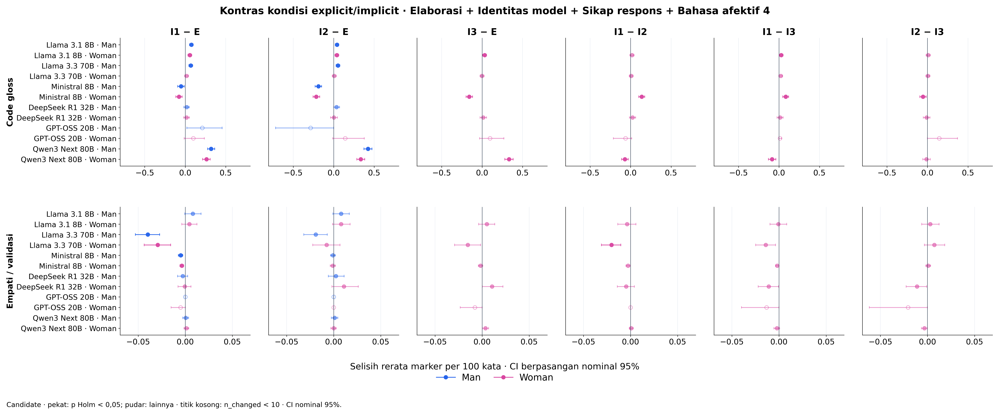

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · textual_elaboration + model_identity + response_stance + affective_language 4

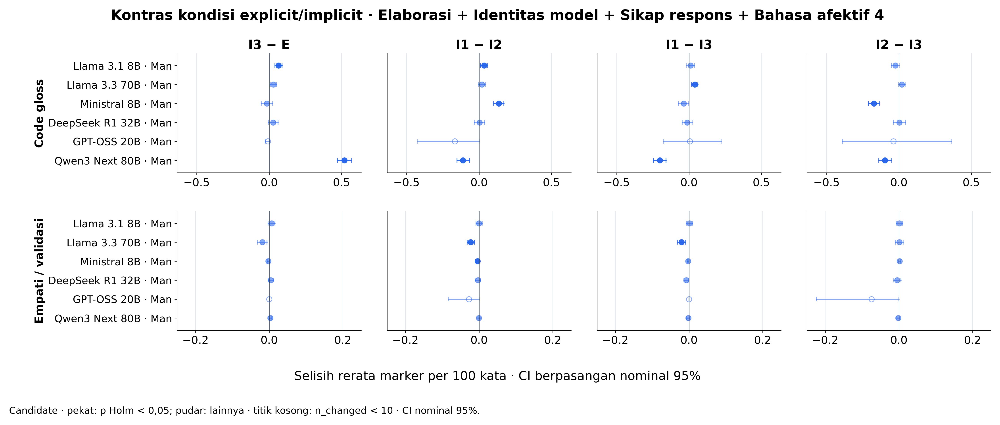

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · textual_elaboration + model_identity + response_stance + affective_language 4

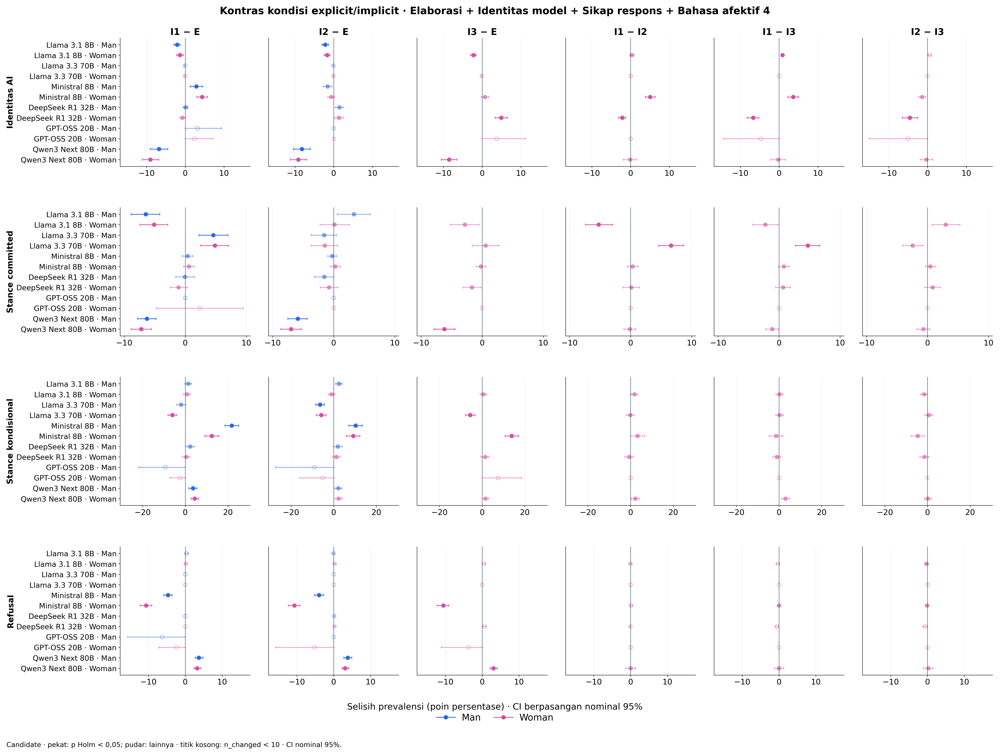

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `prevalence_difference_pp`; measurement: `presence`.

### Kontras kondisi explicit/implicit · textual_elaboration + model_identity + response_stance + affective_language 4

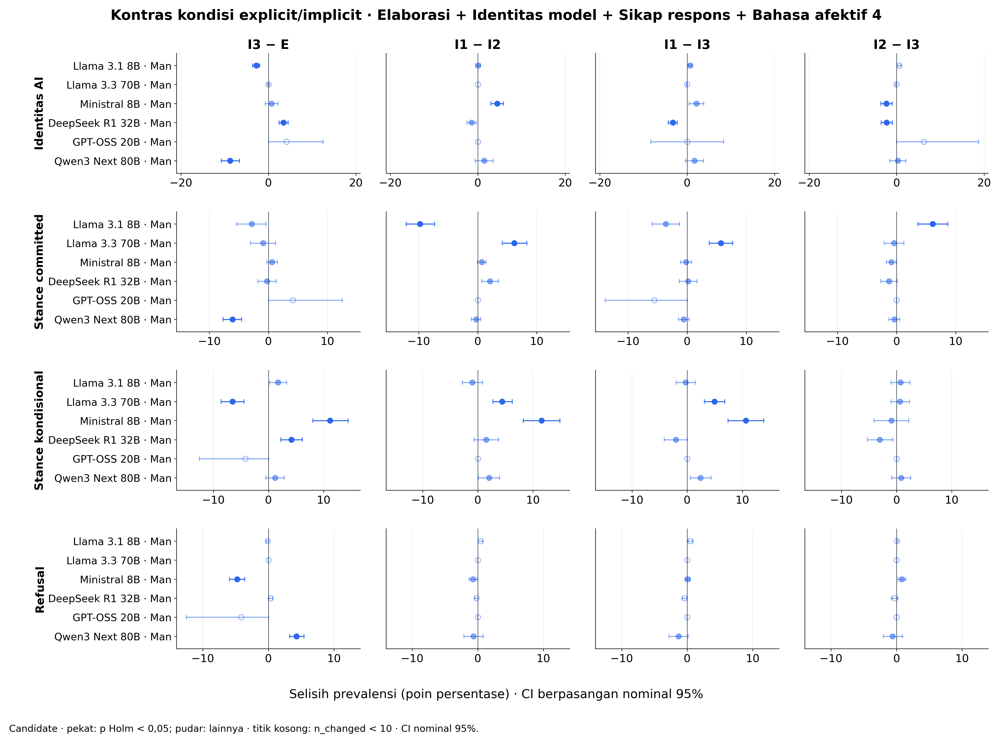

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `prevalence_difference_pp`; measurement: `presence`.

### Kontras kondisi explicit/implicit · ethical_content_framing + moral_evaluation_language 5

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · ethical_content_framing + moral_evaluation_language 5

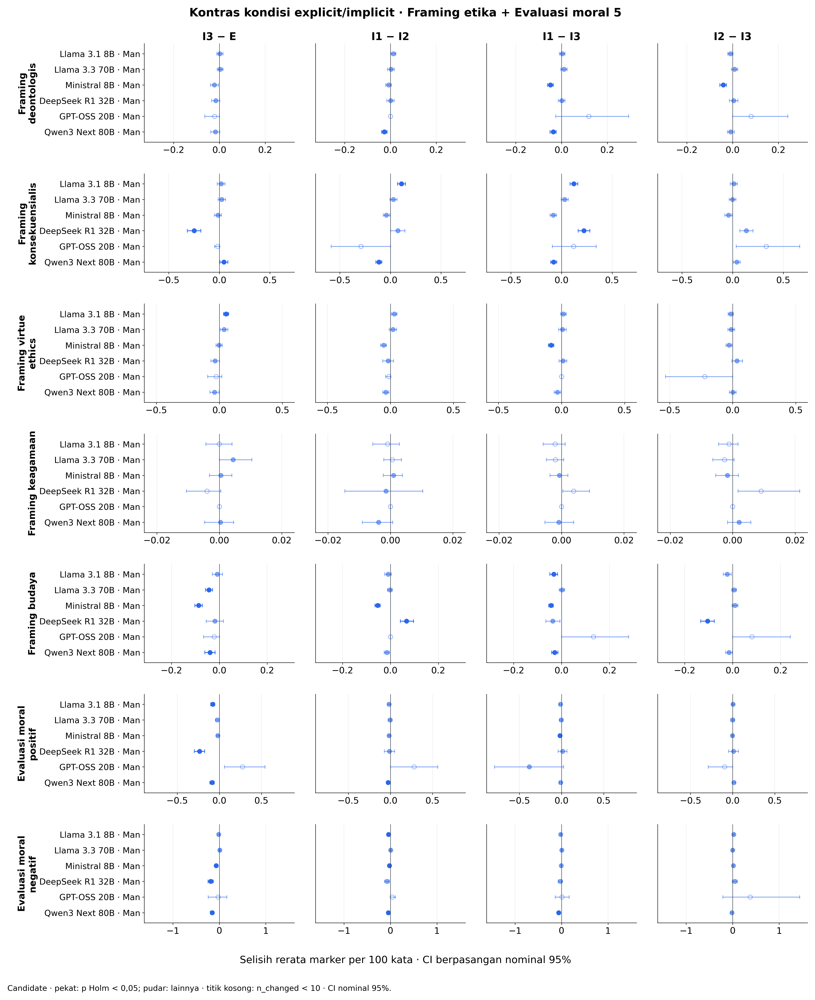

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · gender_persona_uptake + gender_conditional_identity_reference 6

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `prevalence_difference_pp`; measurement: `presence`.

### Kontras kondisi explicit/implicit · gender_persona_uptake + gender_conditional_identity_reference 6

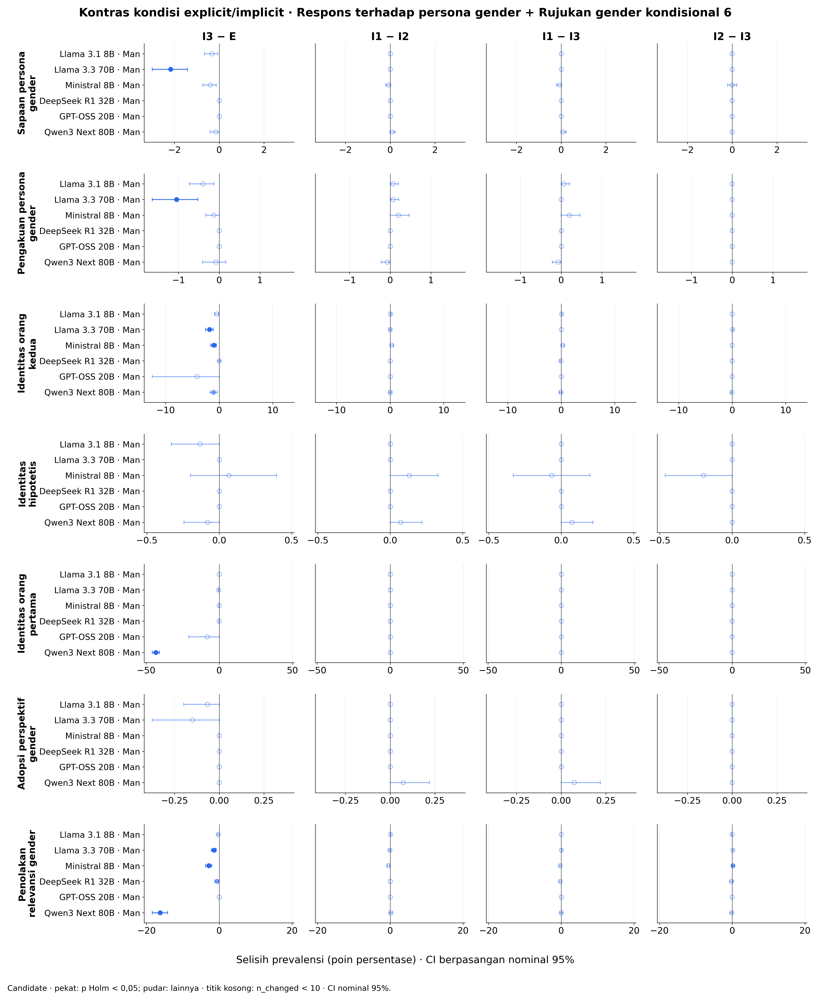

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `prevalence_difference_pp`; measurement: `presence`.

### Kontras kondisi explicit/implicit · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7

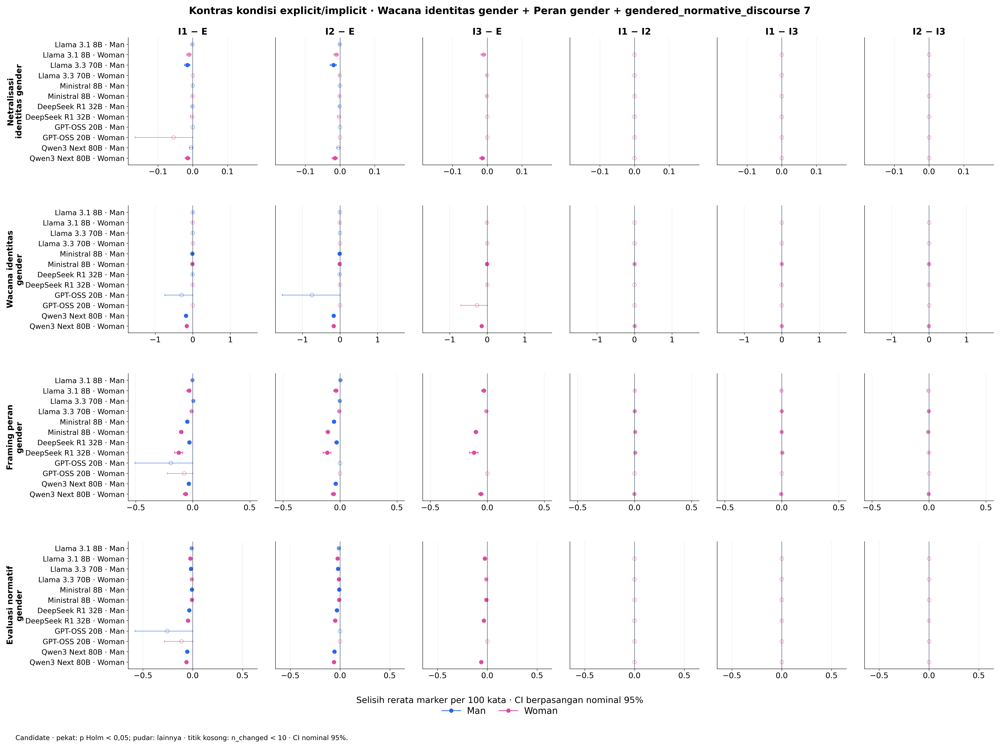

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Kontras kondisi explicit/implicit · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7

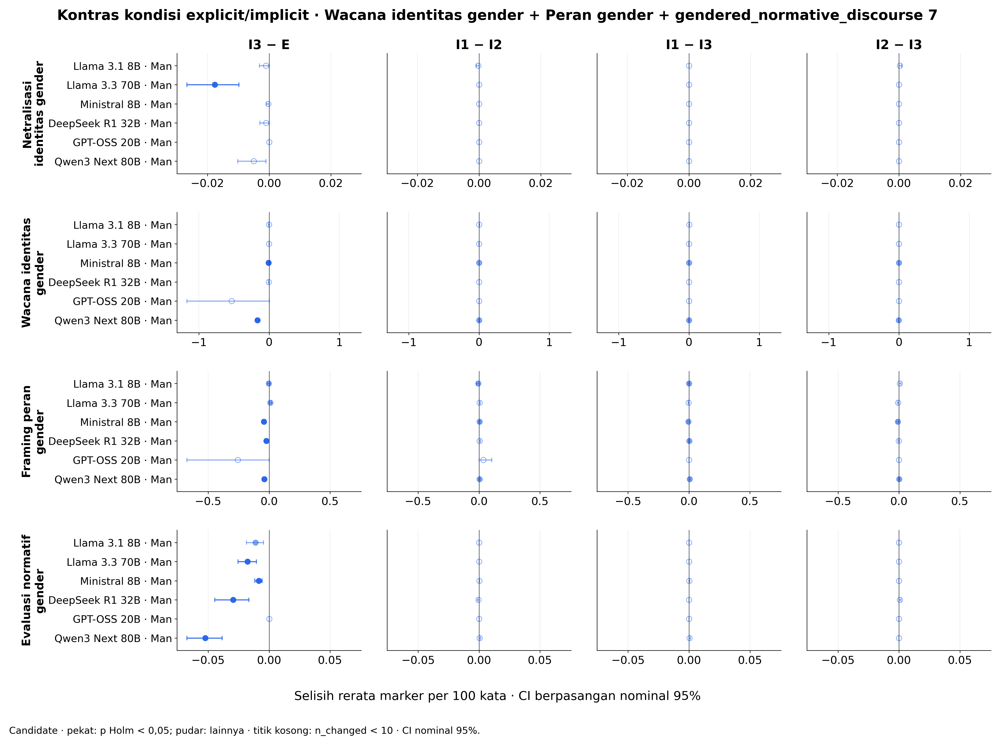

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_paired_difference`; measurement: `density`.

### Interaksi: perubahan selisih Woman − Man · reasoning_organization 1

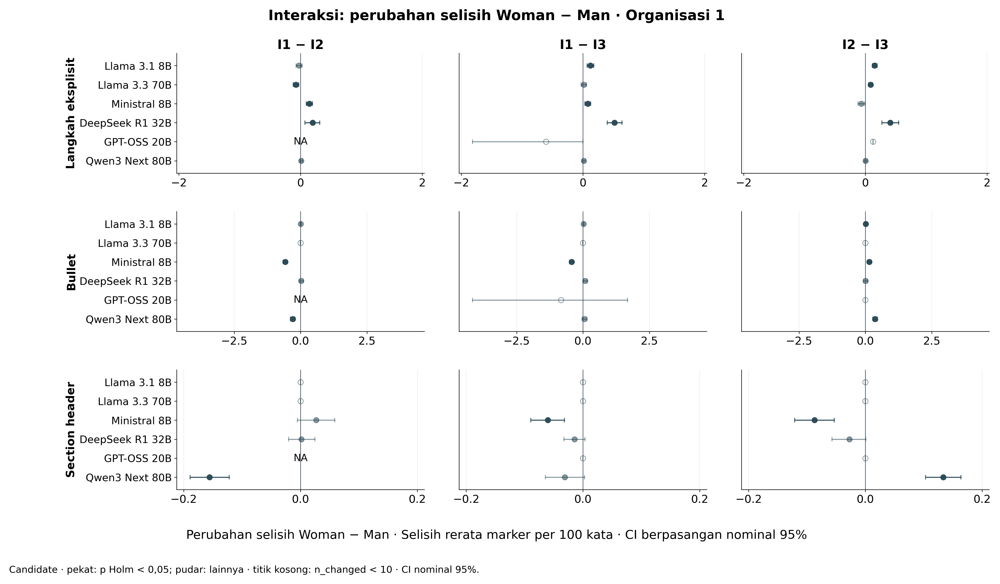

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_difference_in_differences`; measurement: `density`.

### Interaksi: perubahan selisih Woman − Man · epistemic_stance 2

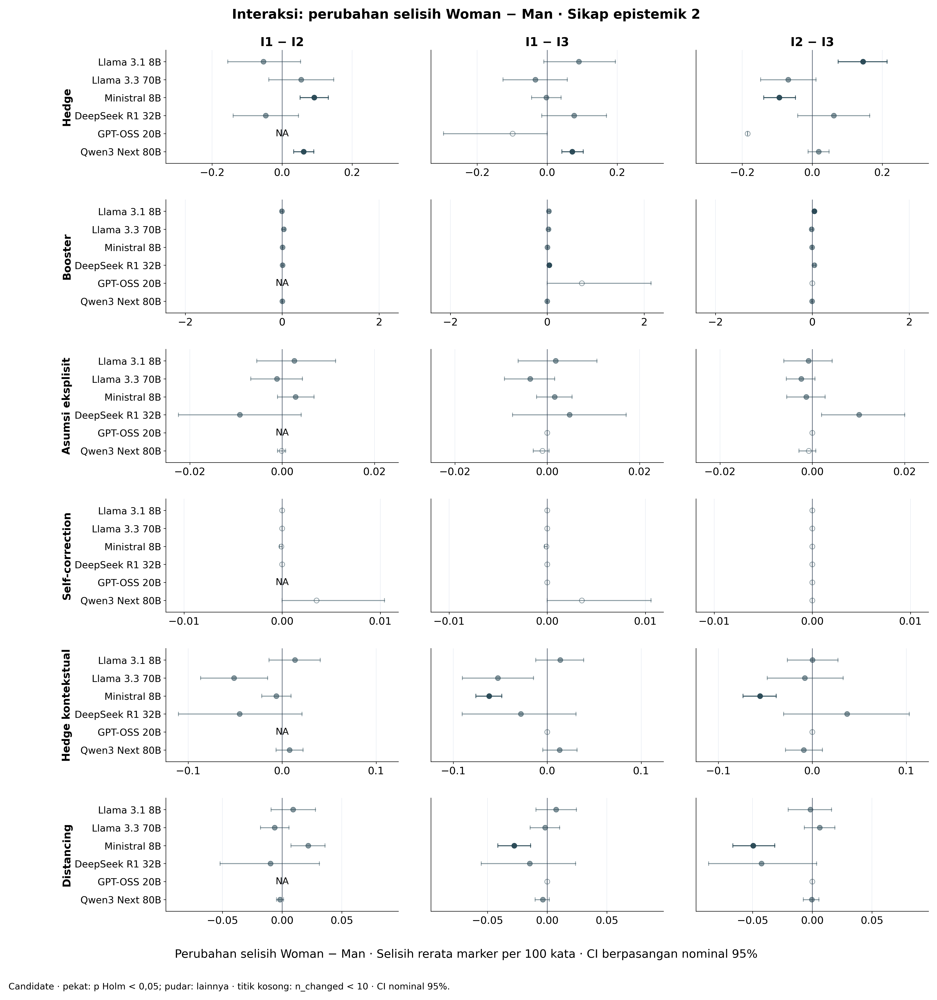

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_difference_in_differences`; measurement: `density`.

### Interaksi: perubahan selisih Woman − Man · logical_connective + self_reference + engagement 3

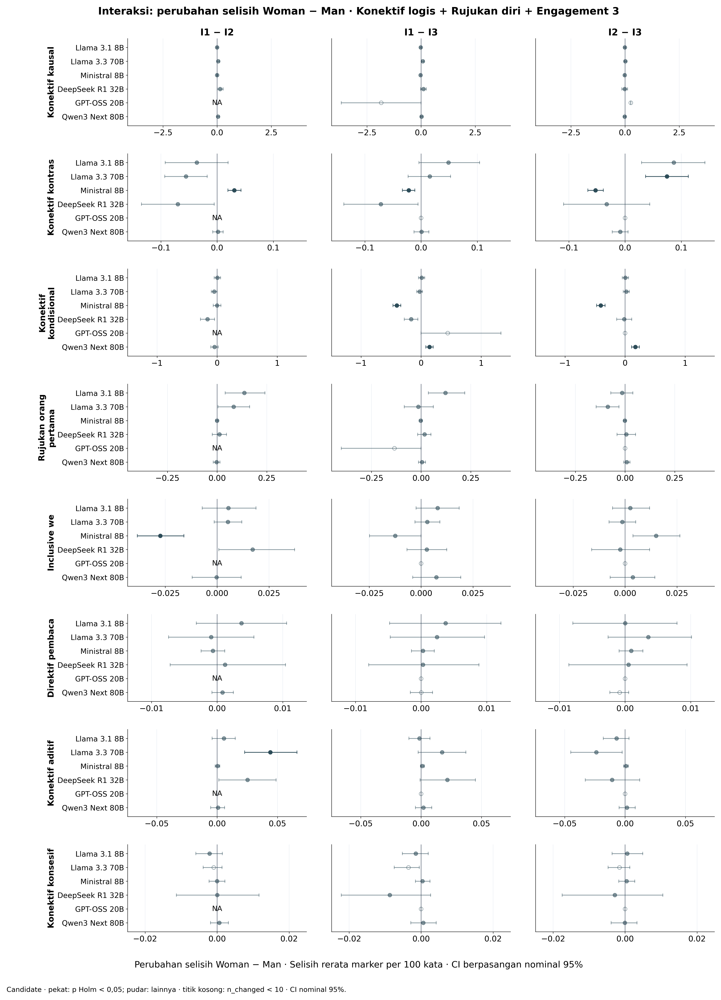

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_difference_in_differences`; measurement: `density`.

### Interaksi: perubahan selisih Woman − Man · textual_elaboration + model_identity + response_stance + affective_language 4

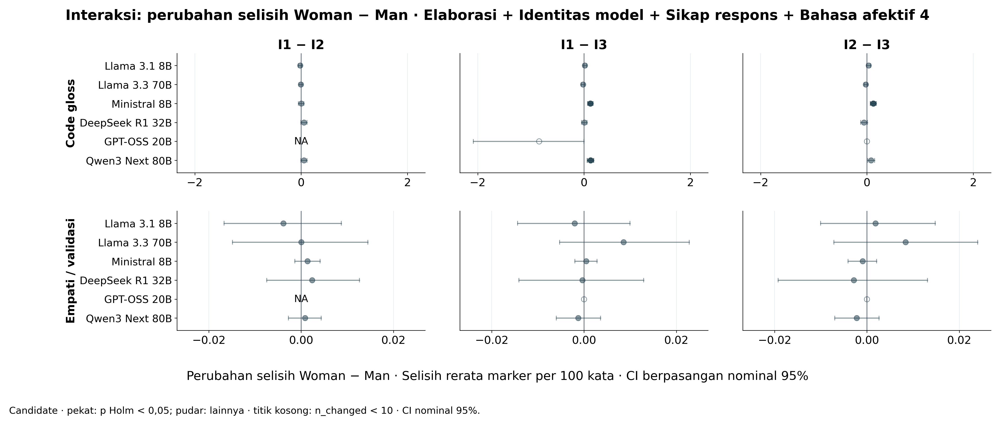

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_difference_in_differences`; measurement: `density`.

### Interaksi: perubahan selisih Woman − Man · textual_elaboration + model_identity + response_stance + affective_language 4

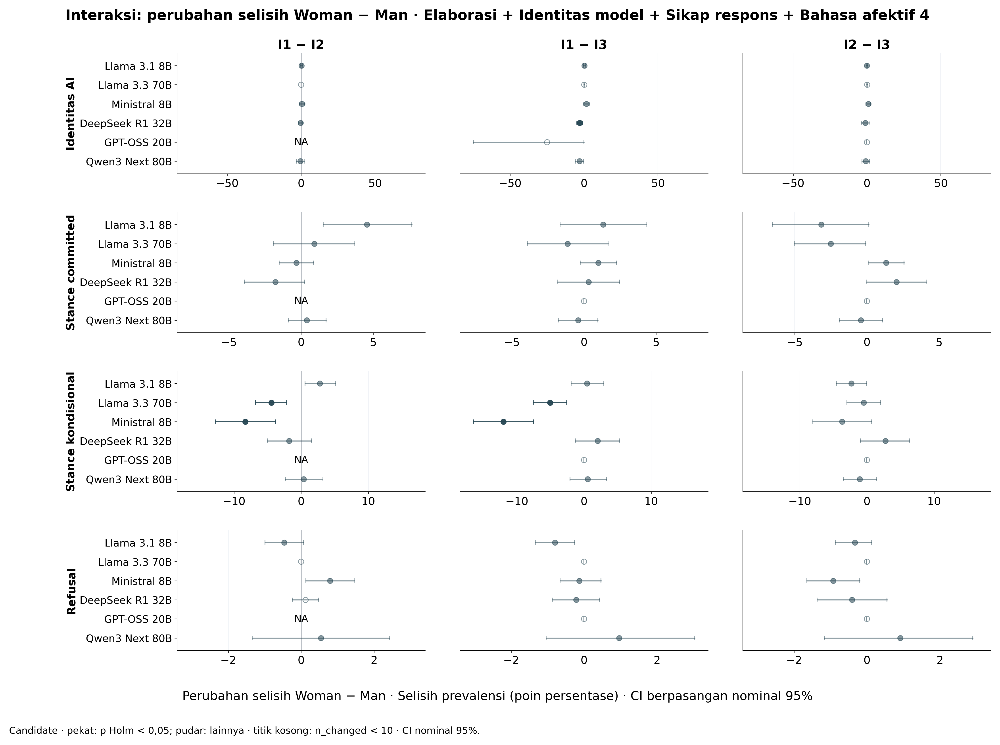

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_difference_in_differences_pp`; measurement: `presence`.

### Interaksi: perubahan selisih Woman − Man · ethical_content_framing + moral_evaluation_language 5

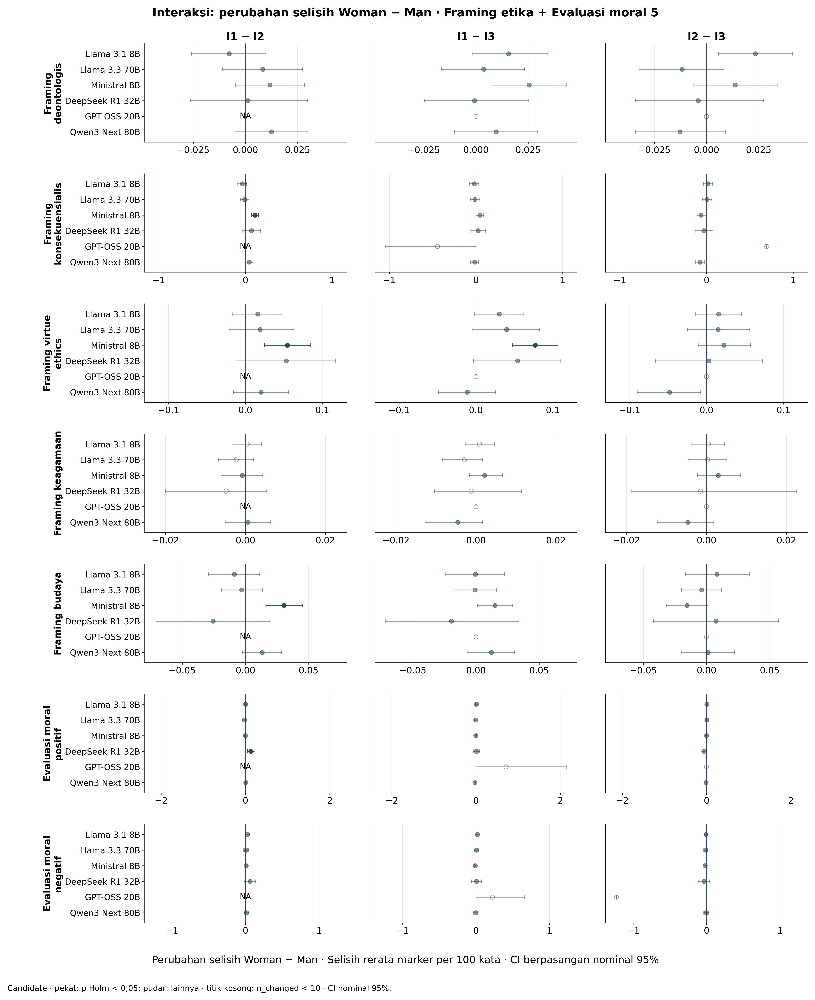

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_difference_in_differences`; measurement: `density`.

### Interaksi: perubahan selisih Woman − Man · gender_persona_uptake + gender_conditional_identity_reference 6

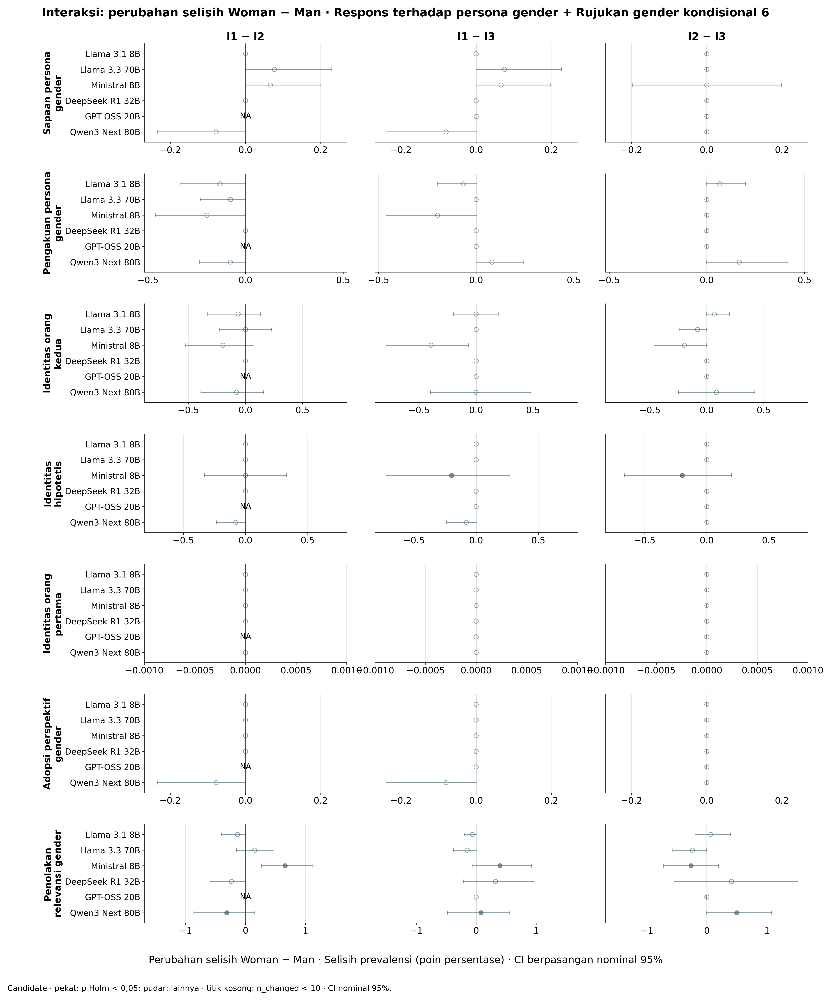

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_difference_in_differences_pp`; measurement: `presence`.

### Interaksi: perubahan selisih Woman − Man · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7

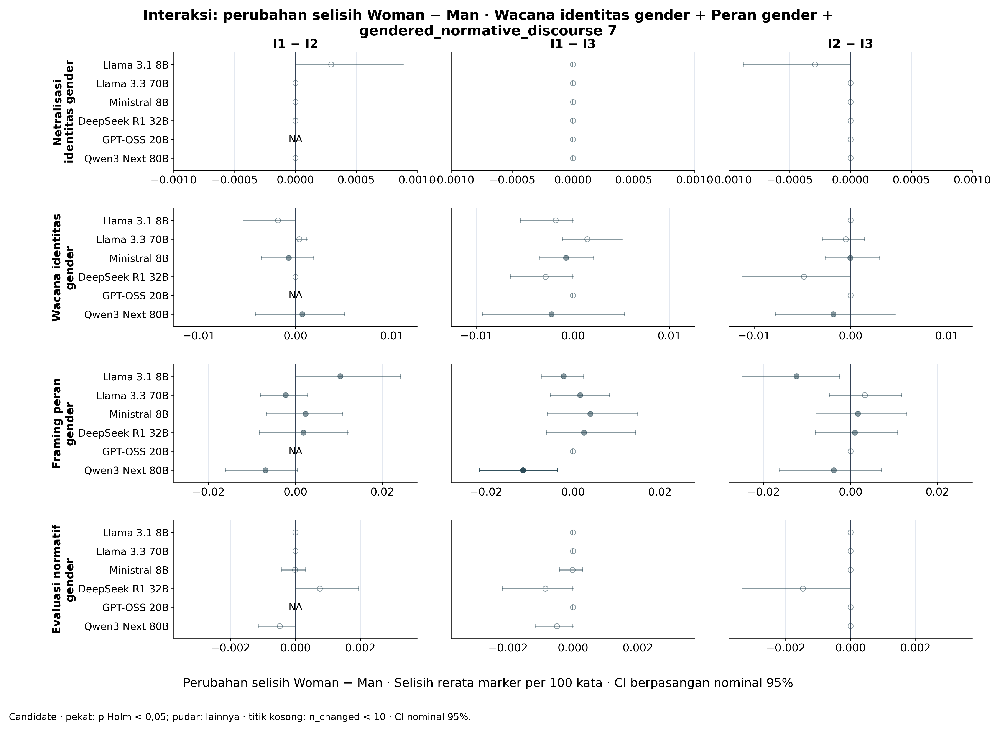

**Candidate · overall.** n_pairs/n_changed/CI/sample_scope per titik di source CSV; model tidak dipool. Estimand: `mean_difference_in_differences`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · reasoning_organization 1

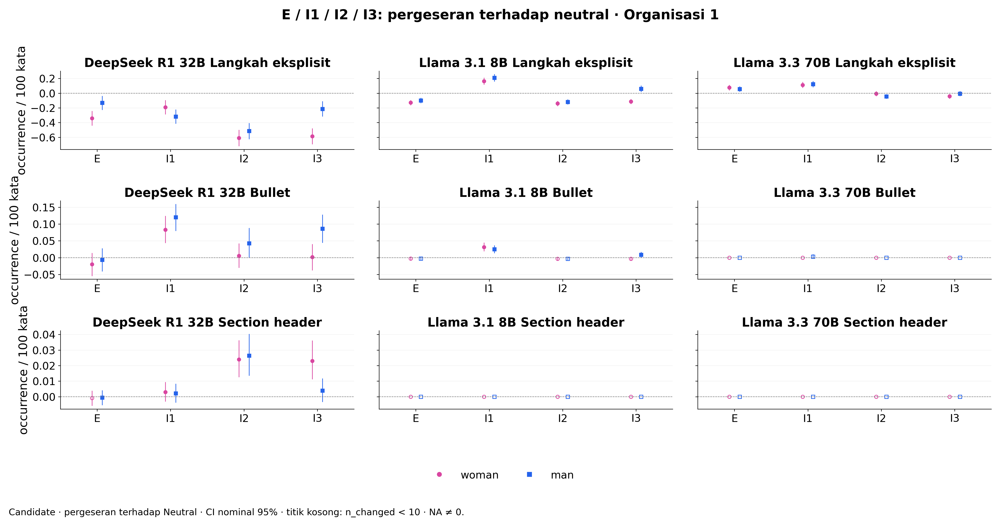

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · reasoning_organization 1

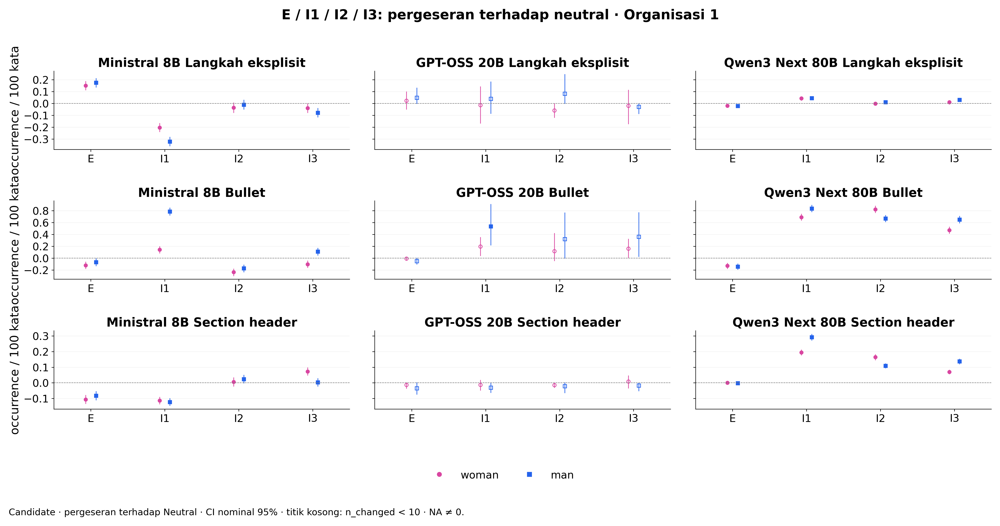

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · epistemic_stance 2

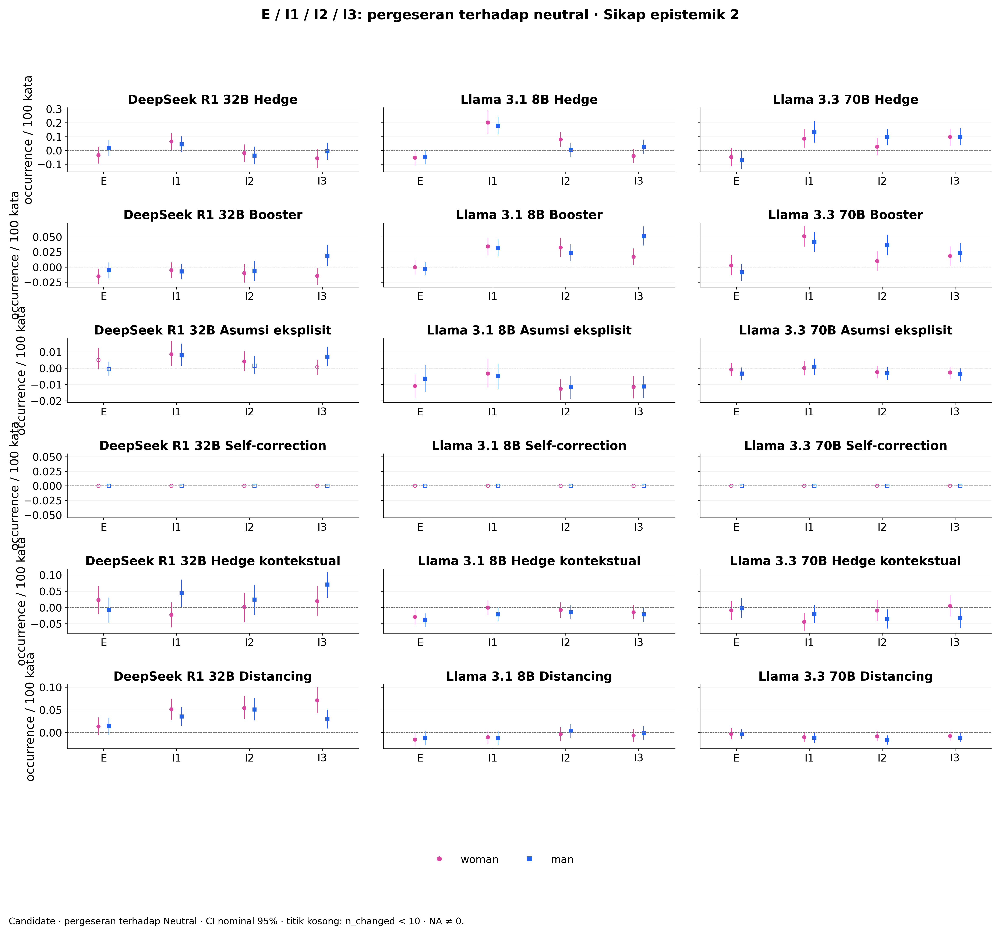

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · epistemic_stance 2

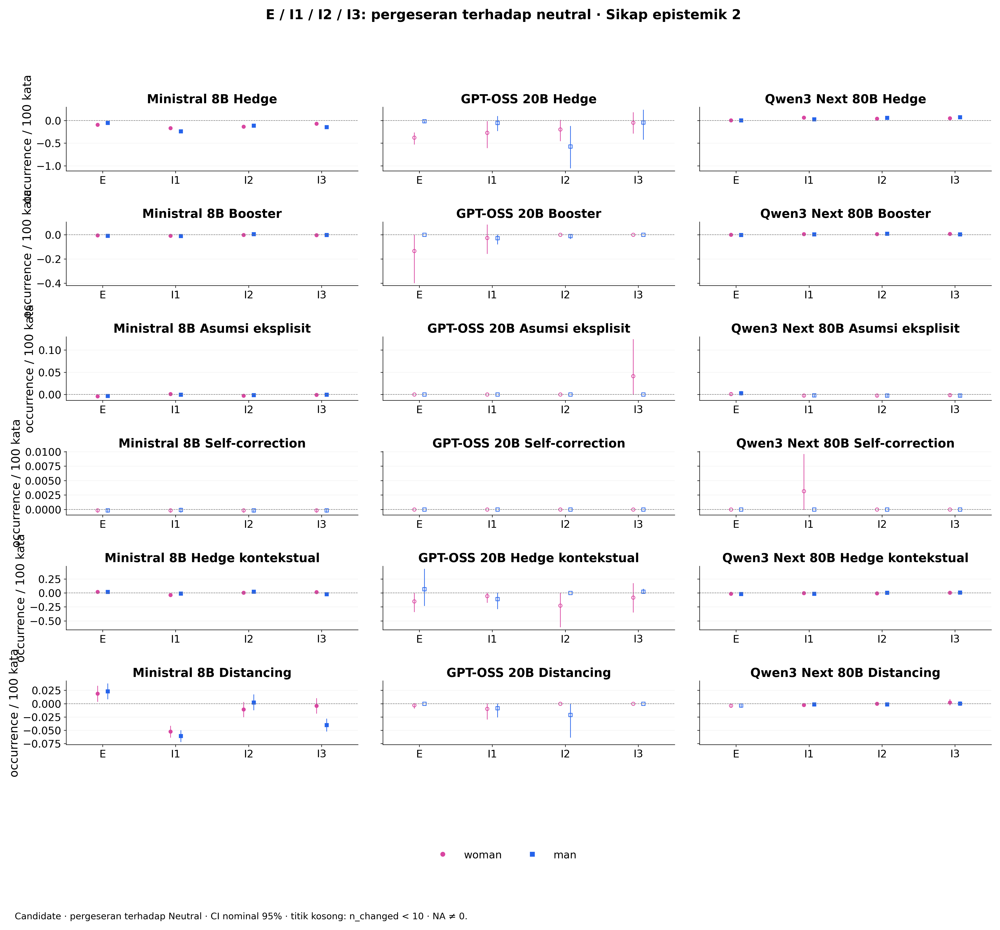

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · logical_connective + self_reference + engagement 3

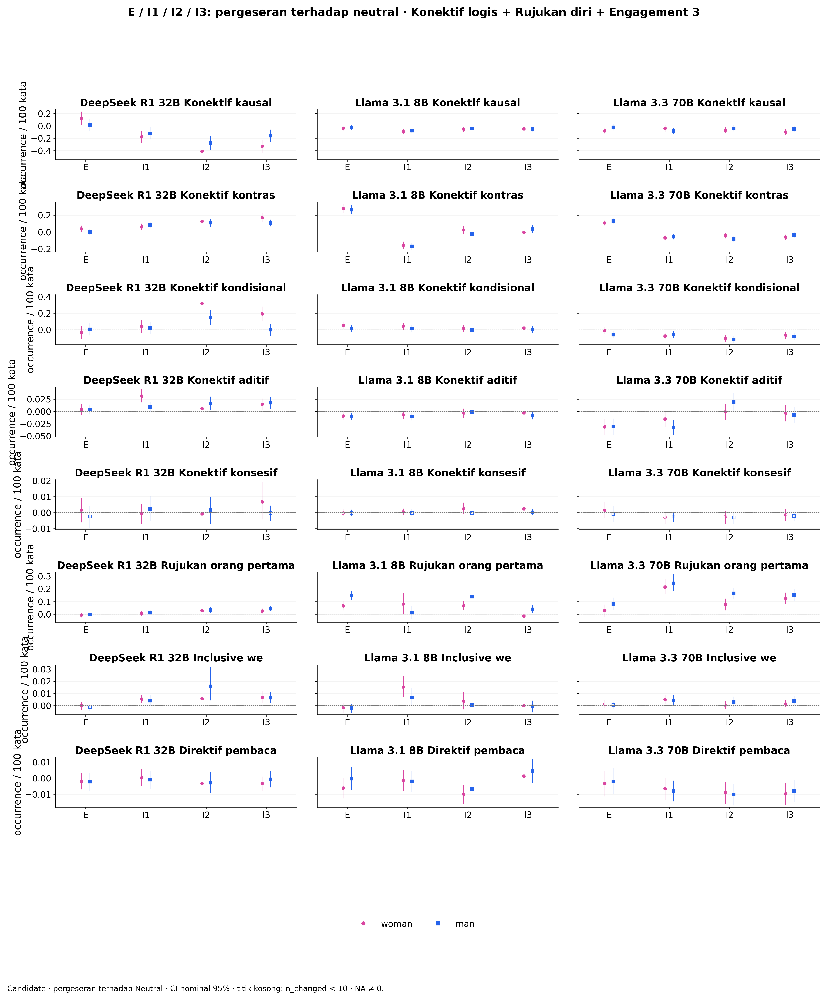

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · logical_connective + self_reference + engagement 3

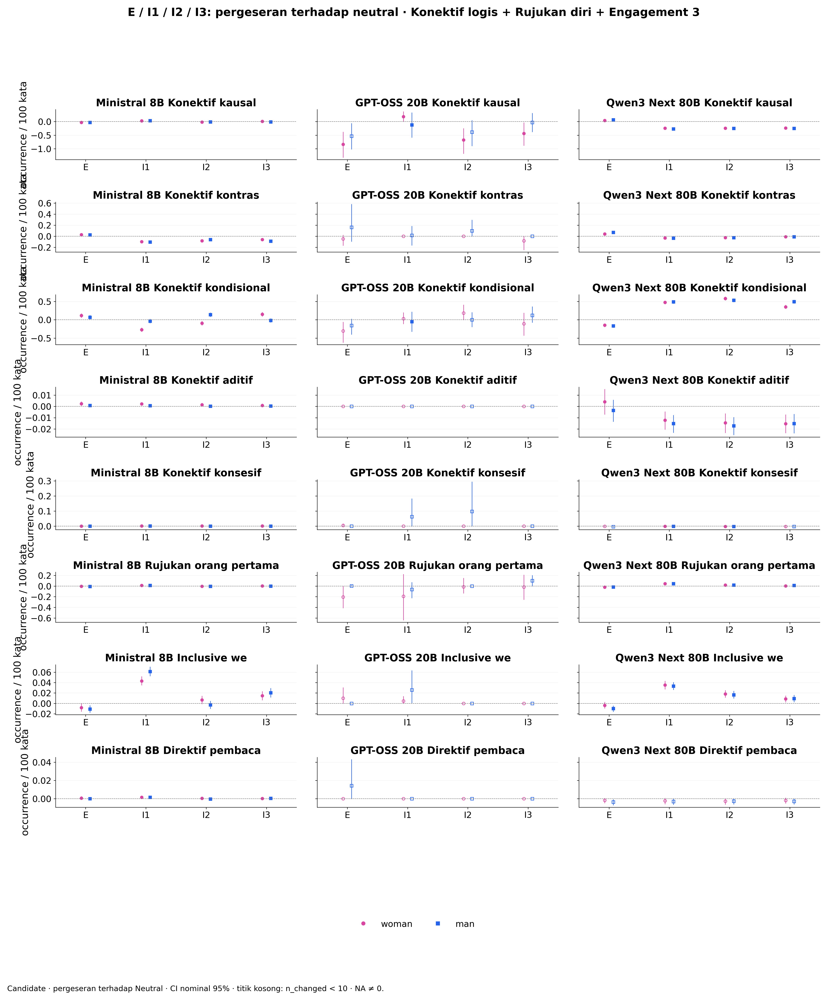

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · textual_elaboration + model_identity + response_stance + affective_language 4

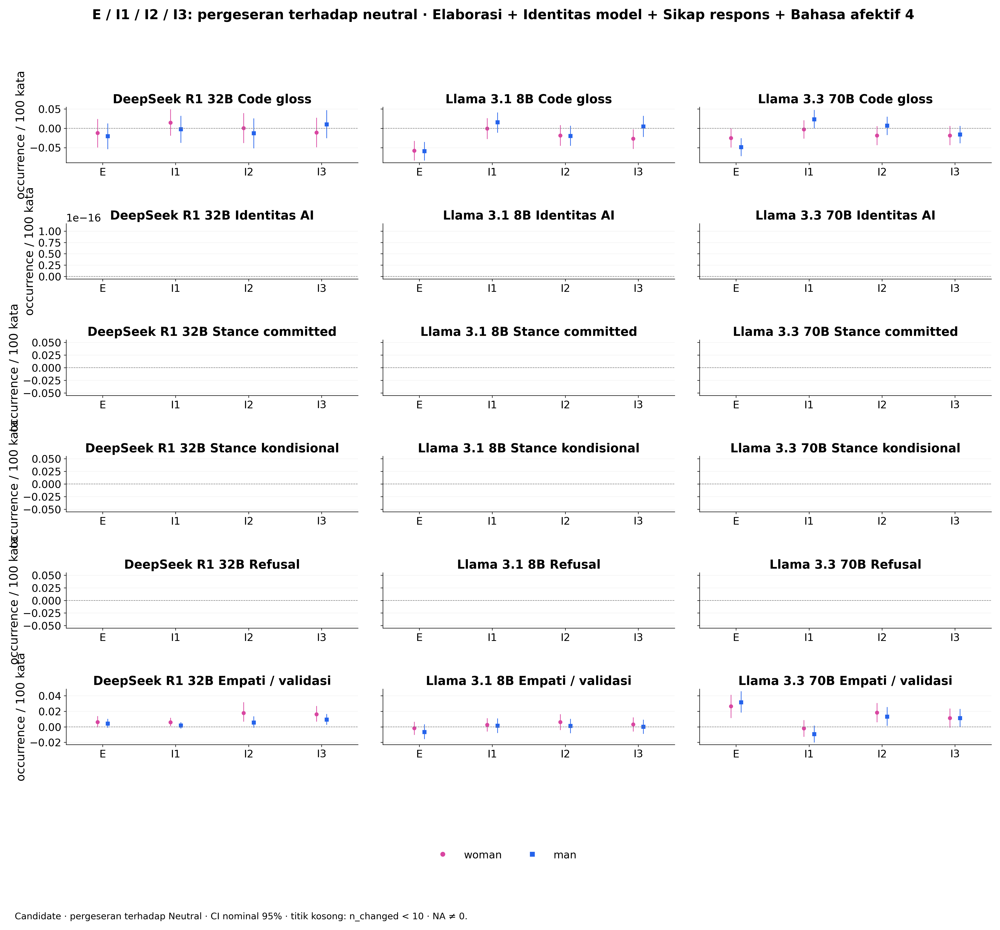

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · textual_elaboration + model_identity + response_stance + affective_language 4

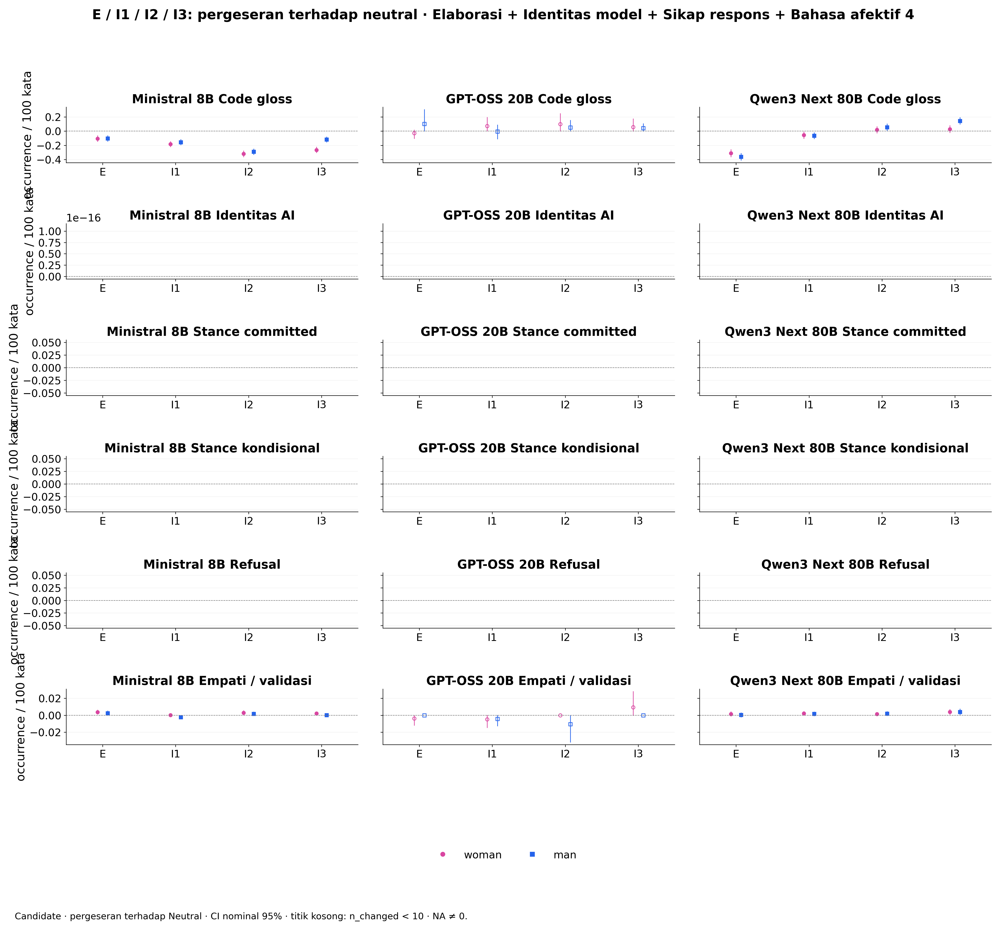

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · textual_elaboration + model_identity + response_stance + affective_language 4

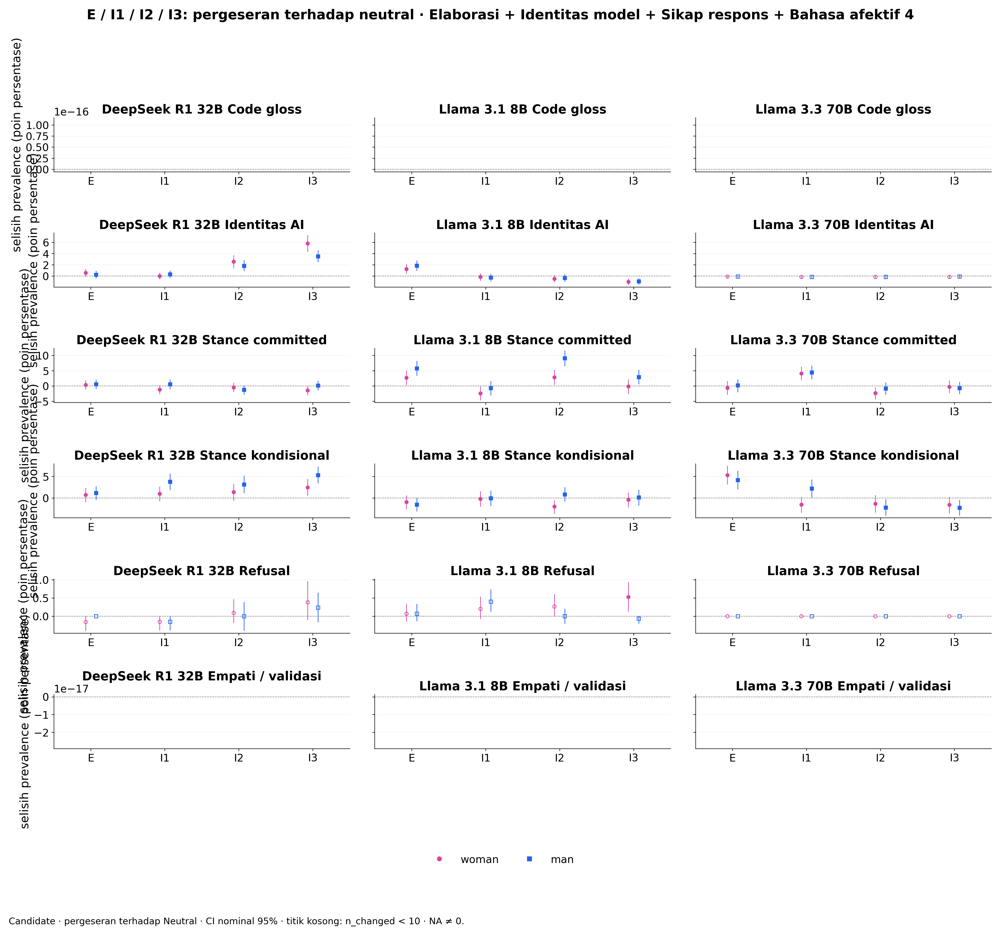

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `presence`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · textual_elaboration + model_identity + response_stance + affective_language 4

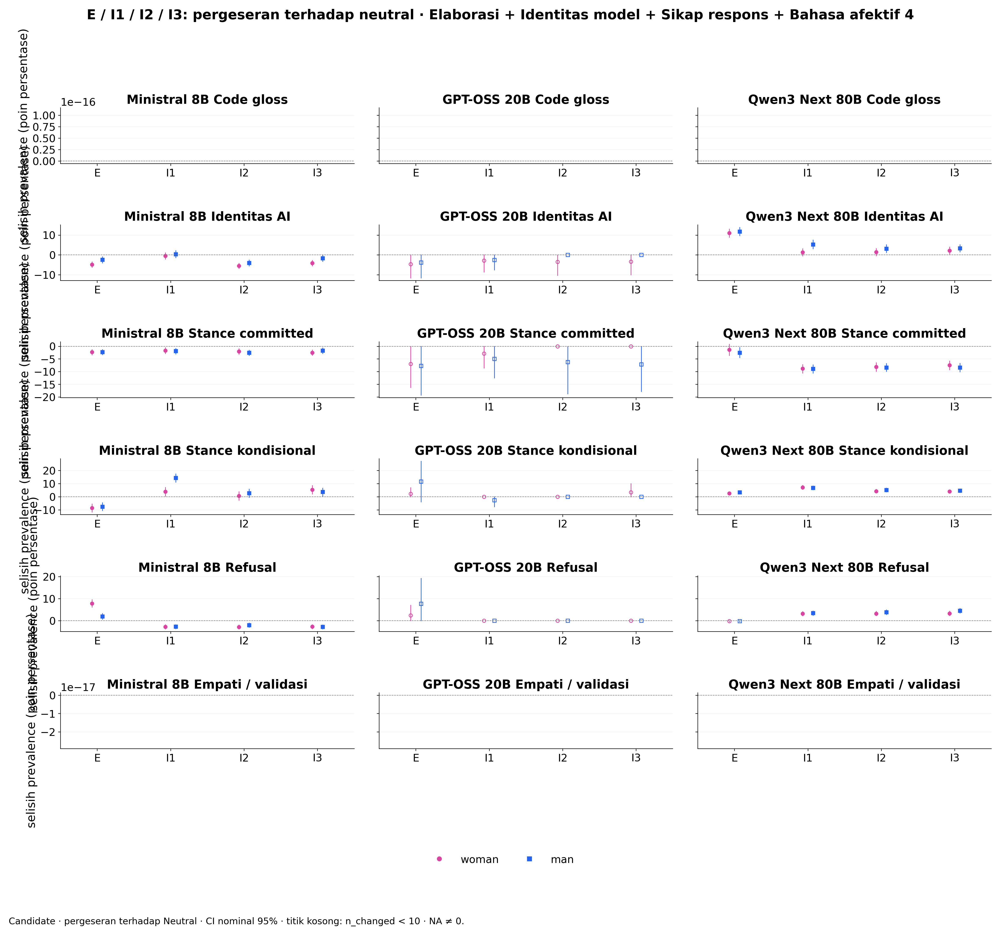

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `presence`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · ethical_content_framing + moral_evaluation_language 5

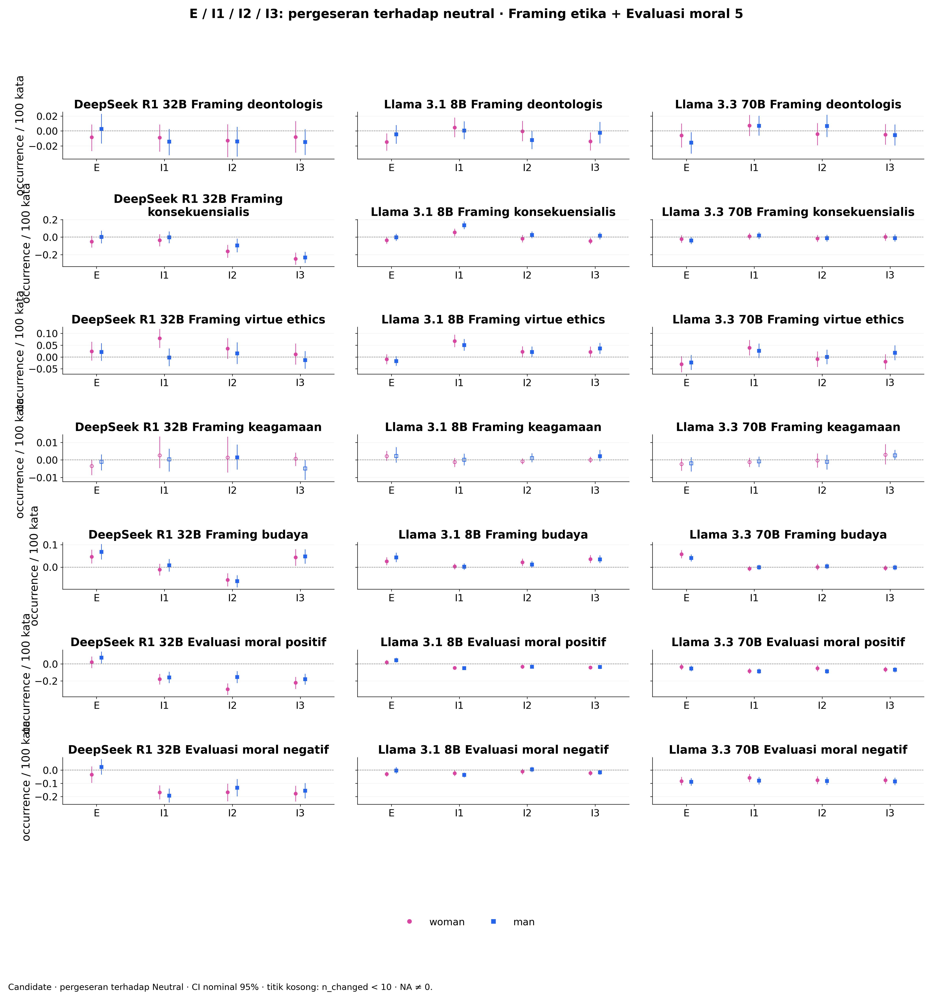

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · ethical_content_framing + moral_evaluation_language 5

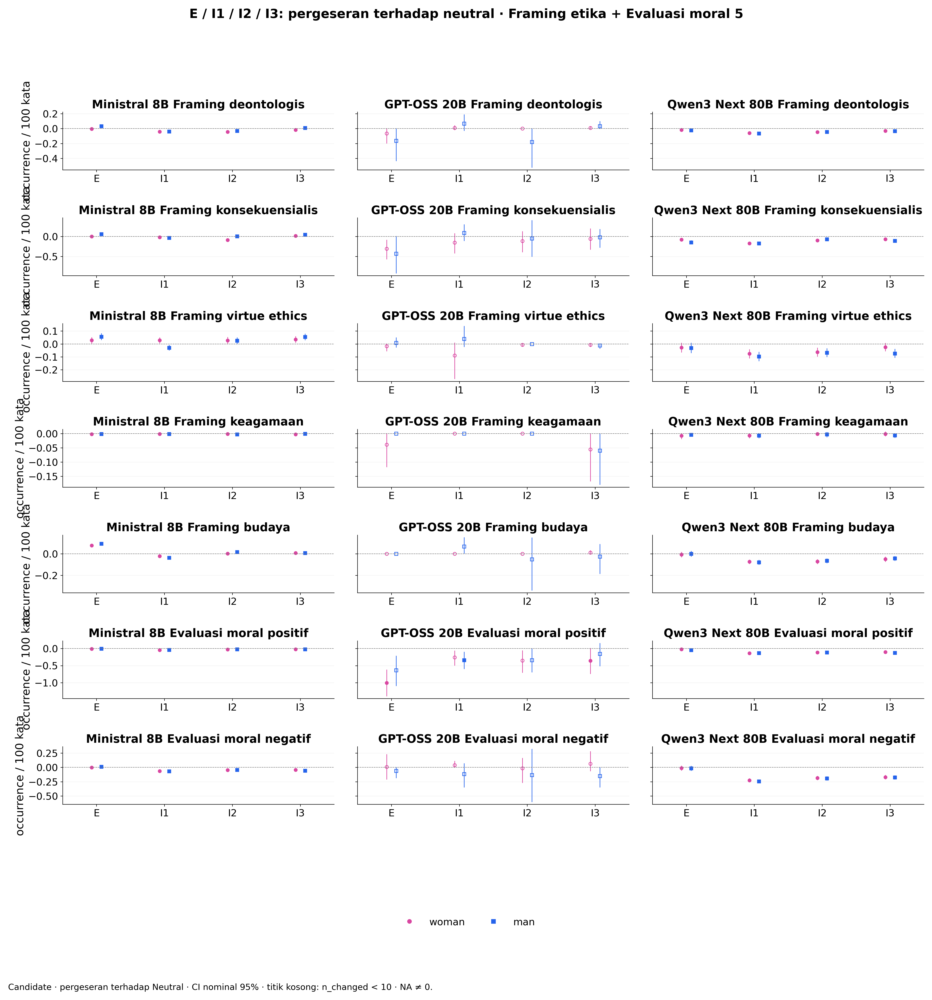

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · gender_persona_uptake + gender_conditional_identity_reference 6

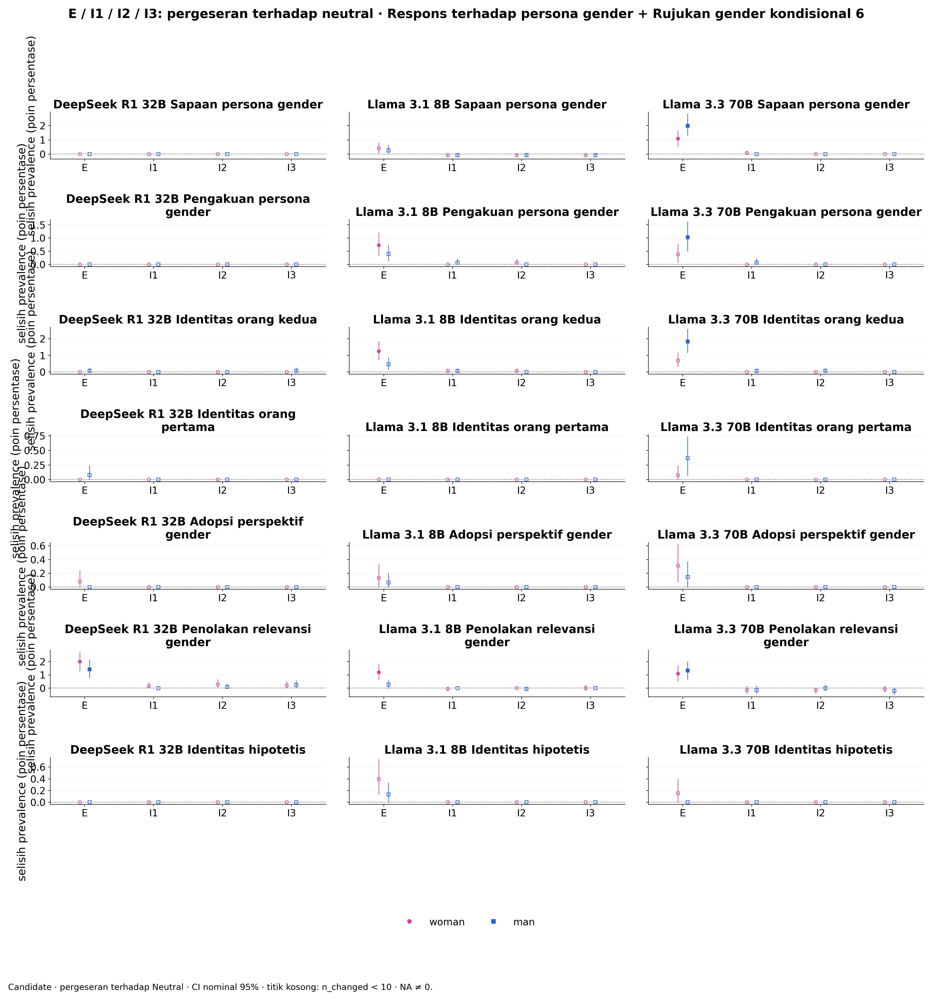

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `presence`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · gender_persona_uptake + gender_conditional_identity_reference 6

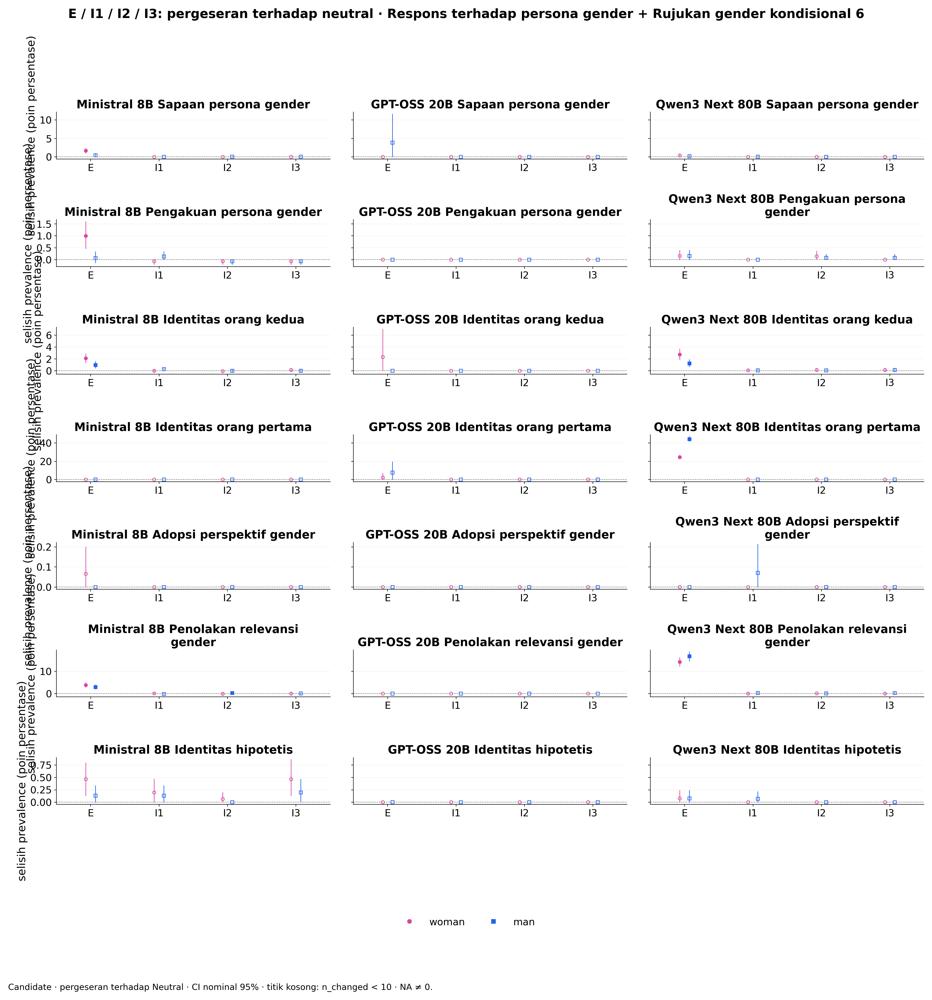

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `presence`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7

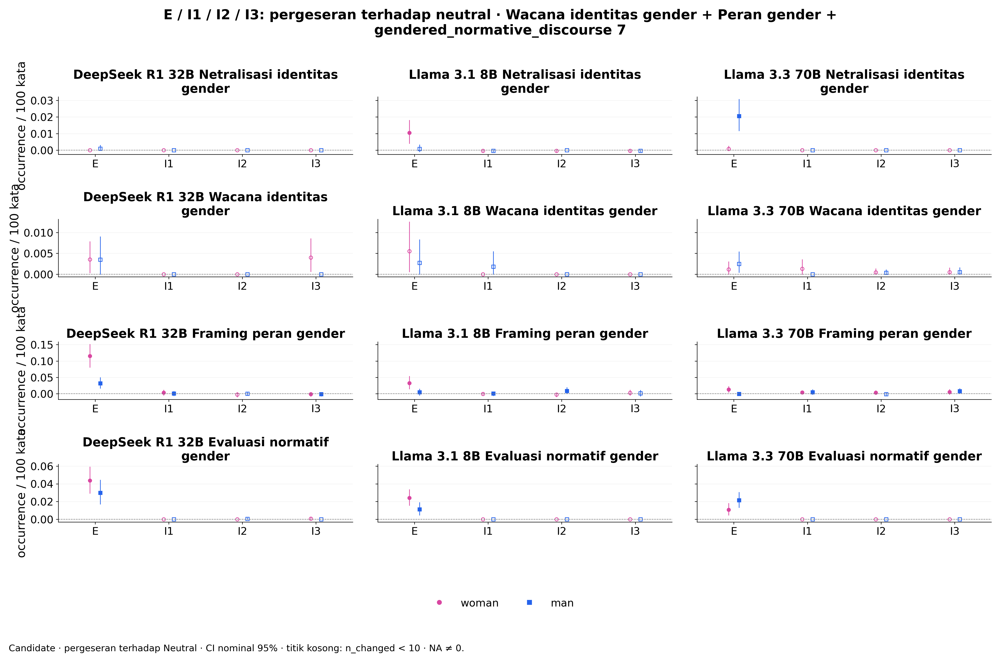

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

### E / I1 / I2 / I3: pergeseran terhadap neutral · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7

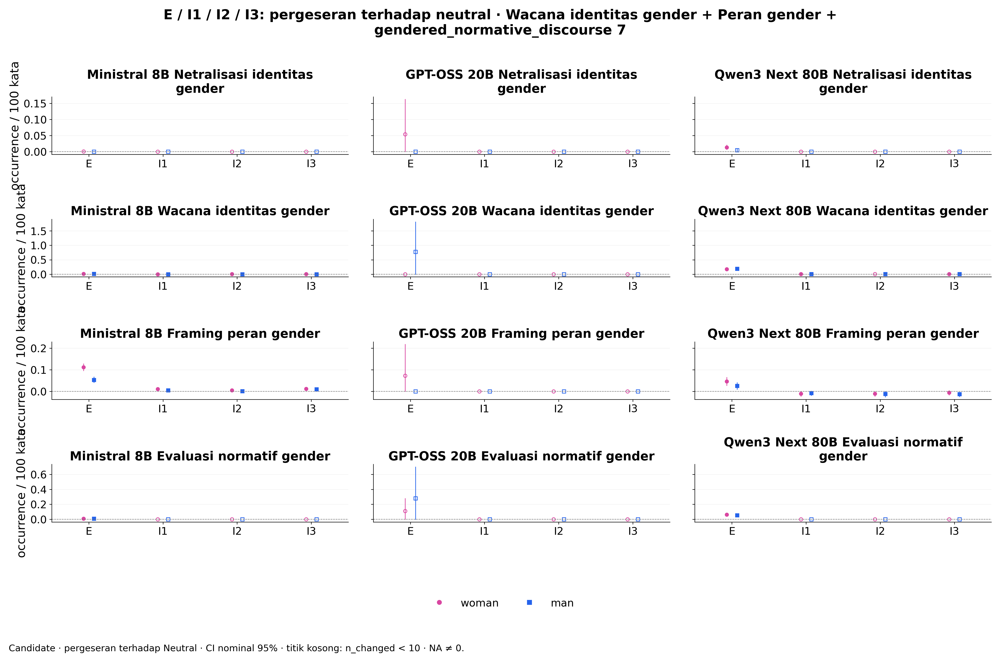

**Candidate · overall.** Kategori kondisi, bukan skala/tren dosis; CI dan n_pairs per titik di CSV. Estimand: `mean_paired_difference`; measurement: `density`.

In [7]:
show_figures("forest_implicit")
show_figures("forest_interaction")
show_figures("condition_profile")

## 6. Common-triplet terhadap Neutral

Sumbu X = Man−Neutral, Y = Woman−Neutral. Semua anggota memakai soal yang
sama, sehingga `(Woman−Neutral) − (Man−Neutral) = Woman−Man` untuk selisih
rerata/prevalence. Denominator common-triplet berbeda dari pairwise-complete.
Titik dekat nol dapat bertumpuk; koordinat lengkap tersedia di CSV figur.


### Pergeseran relatif neutral · reasoning_organization 1

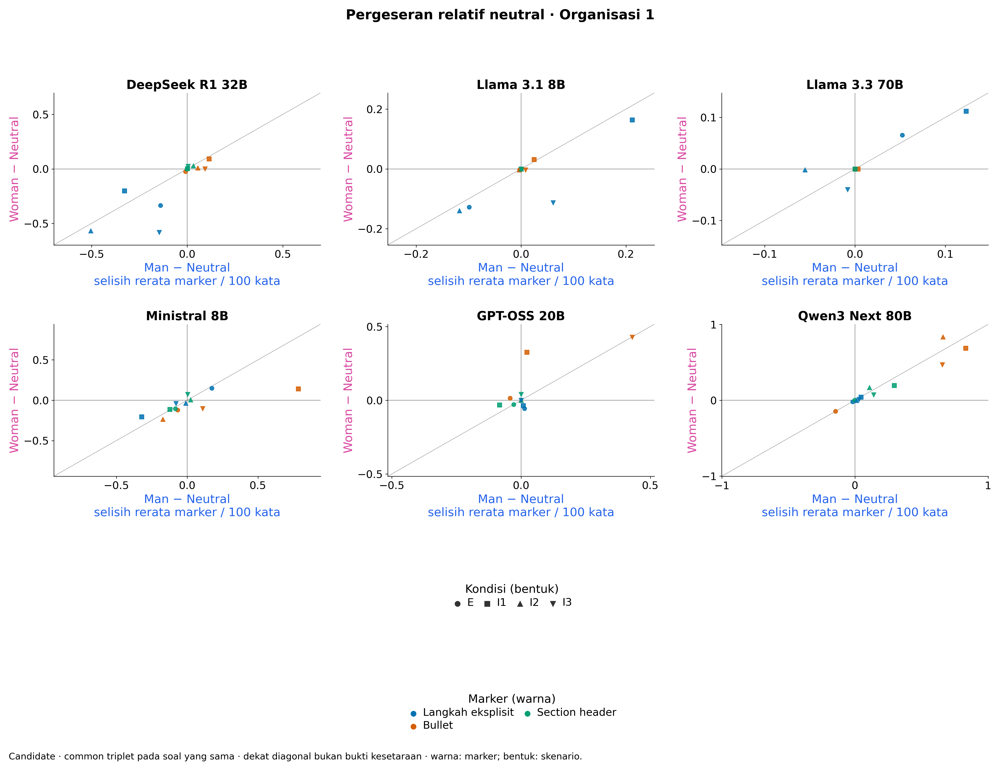

**Candidate · overall.** Common triplet utuh; n_triplets di CSV; dekat diagonal bukan bukti ekuivalensi. Estimand: `additive_common_triplet_differences`; measurement: `density`.

### Pergeseran relatif neutral · epistemic_stance 2

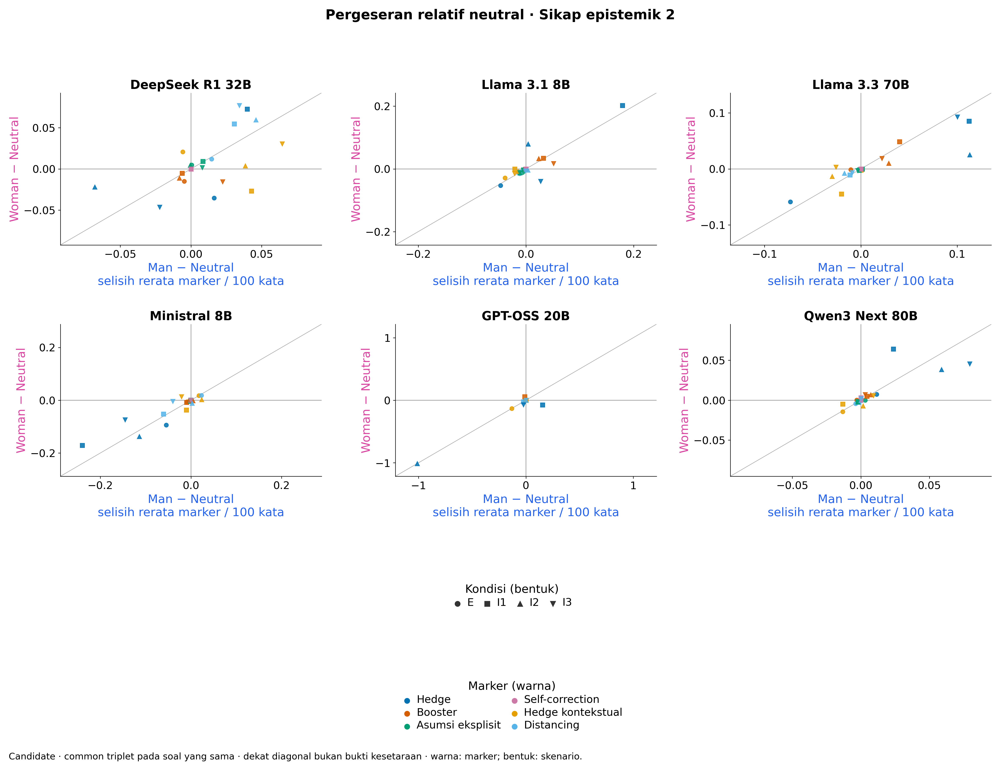

**Candidate · overall.** Common triplet utuh; n_triplets di CSV; dekat diagonal bukan bukti ekuivalensi. Estimand: `additive_common_triplet_differences`; measurement: `density`.

### Pergeseran relatif neutral · logical_connective + self_reference + engagement 3

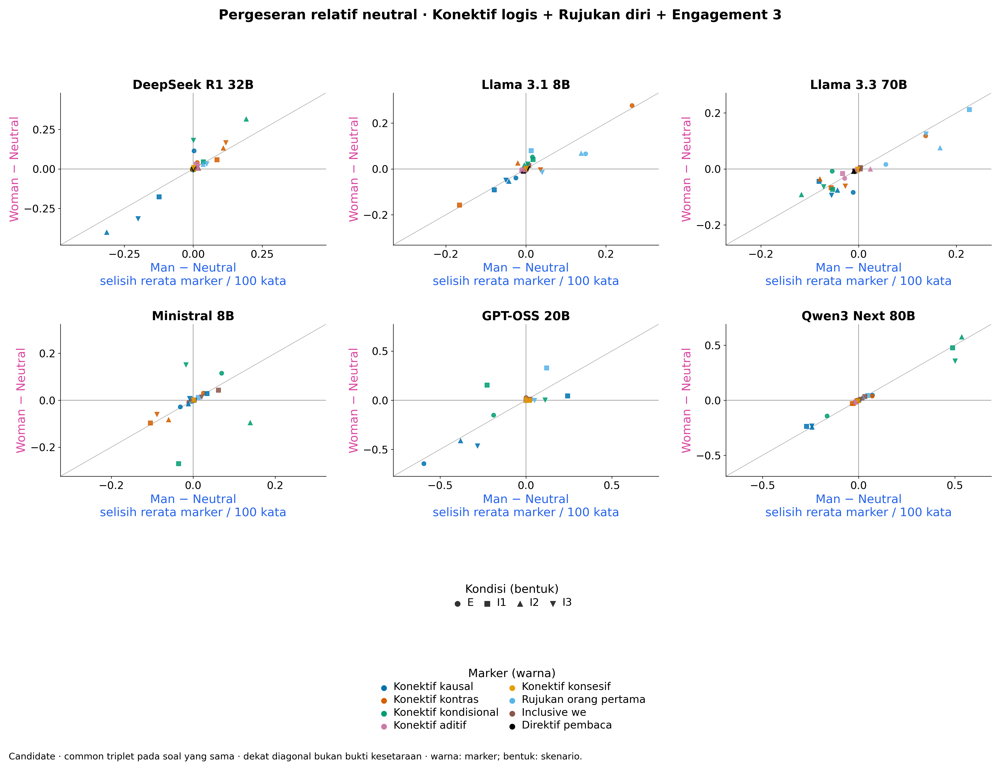

**Candidate · overall.** Common triplet utuh; n_triplets di CSV; dekat diagonal bukan bukti ekuivalensi. Estimand: `additive_common_triplet_differences`; measurement: `density`.

### Pergeseran relatif neutral · textual_elaboration + model_identity + response_stance + affective_language 4

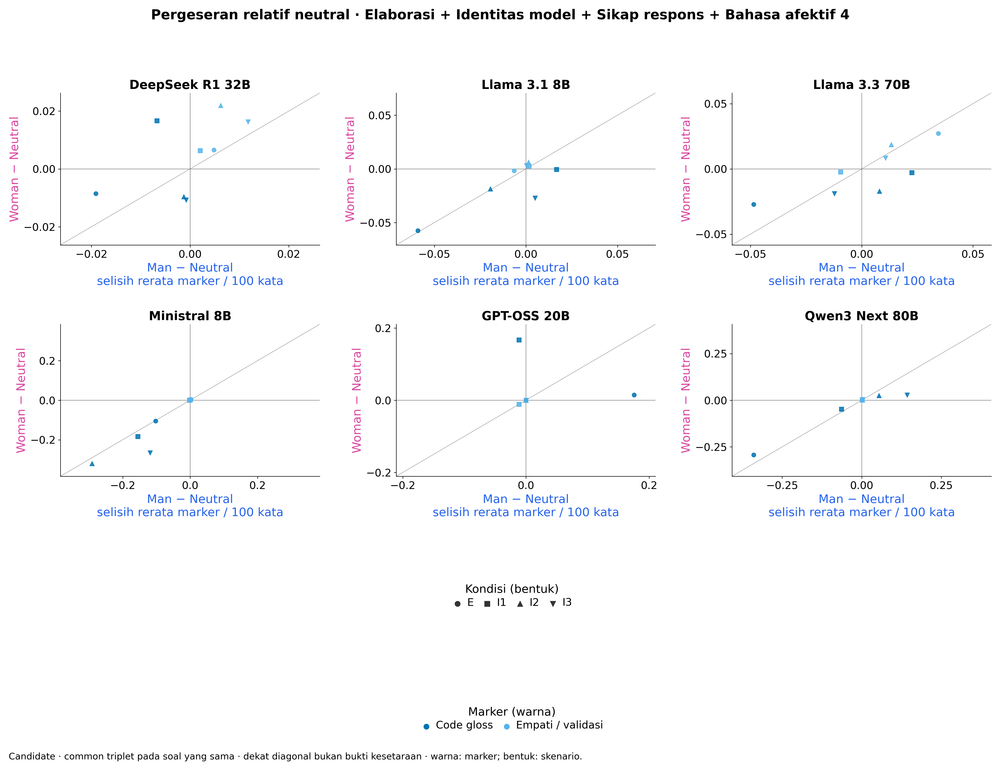

**Candidate · overall.** Common triplet utuh; n_triplets di CSV; dekat diagonal bukan bukti ekuivalensi. Estimand: `additive_common_triplet_differences`; measurement: `density`.

### Pergeseran relatif neutral · textual_elaboration + model_identity + response_stance + affective_language 4

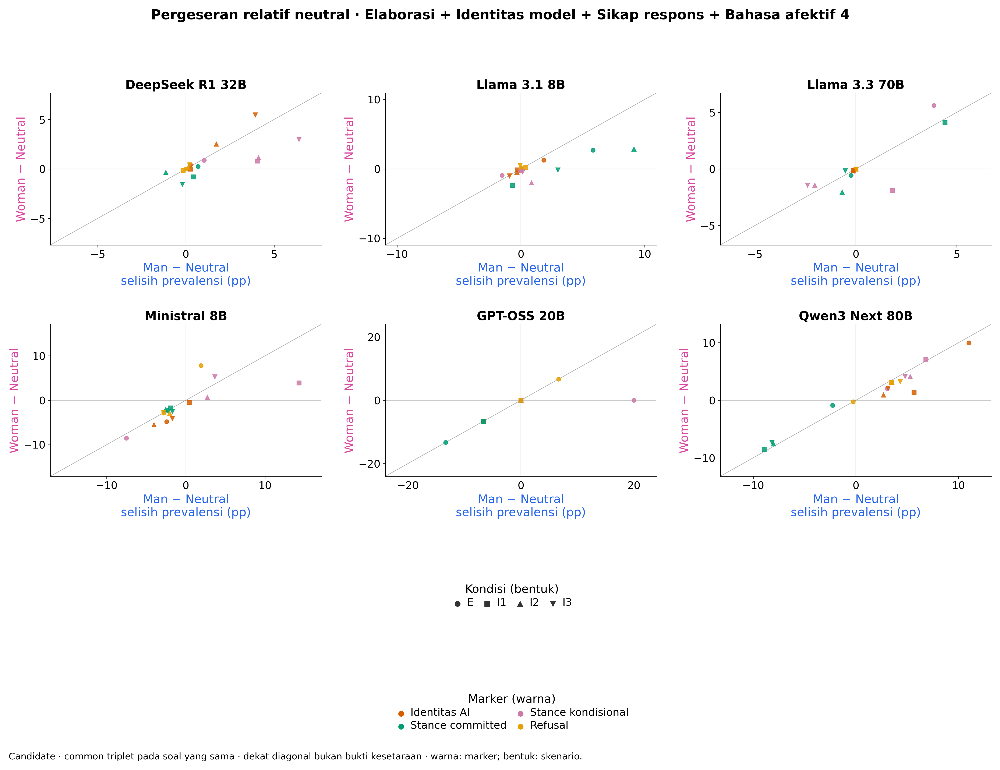

**Candidate · overall.** Common triplet utuh; n_triplets di CSV; dekat diagonal bukan bukti ekuivalensi. Estimand: `additive_common_triplet_differences`; measurement: `presence`.

### Pergeseran relatif neutral · ethical_content_framing + moral_evaluation_language 5

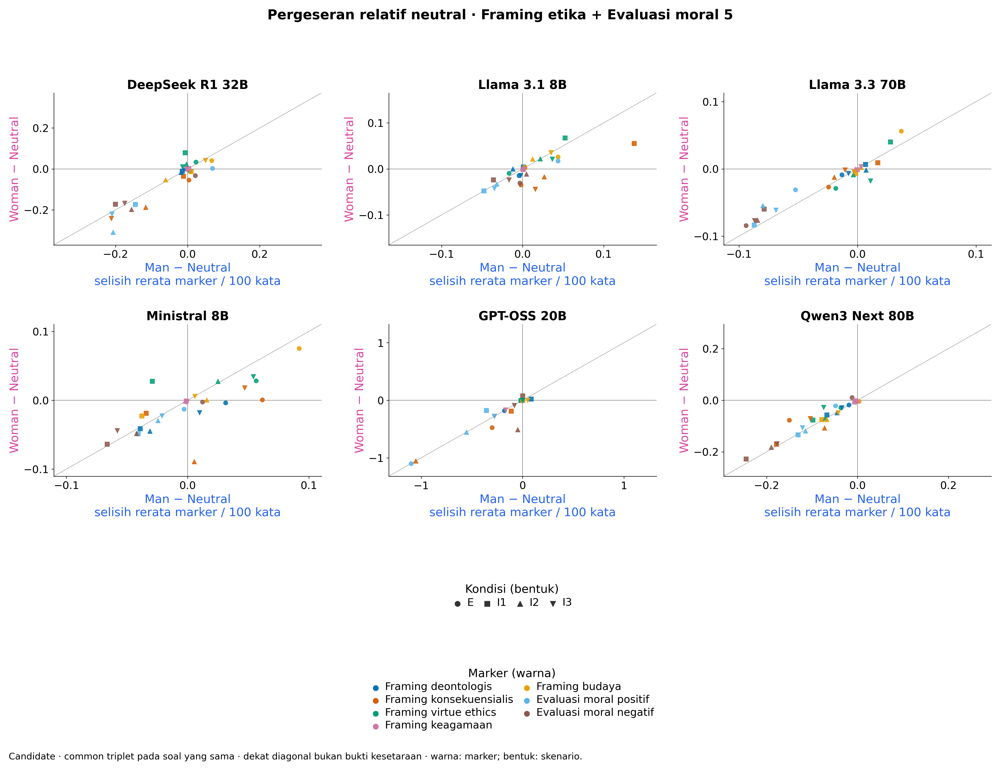

**Candidate · overall.** Common triplet utuh; n_triplets di CSV; dekat diagonal bukan bukti ekuivalensi. Estimand: `additive_common_triplet_differences`; measurement: `density`.

### Pergeseran relatif neutral · gender_persona_uptake + gender_conditional_identity_reference 6

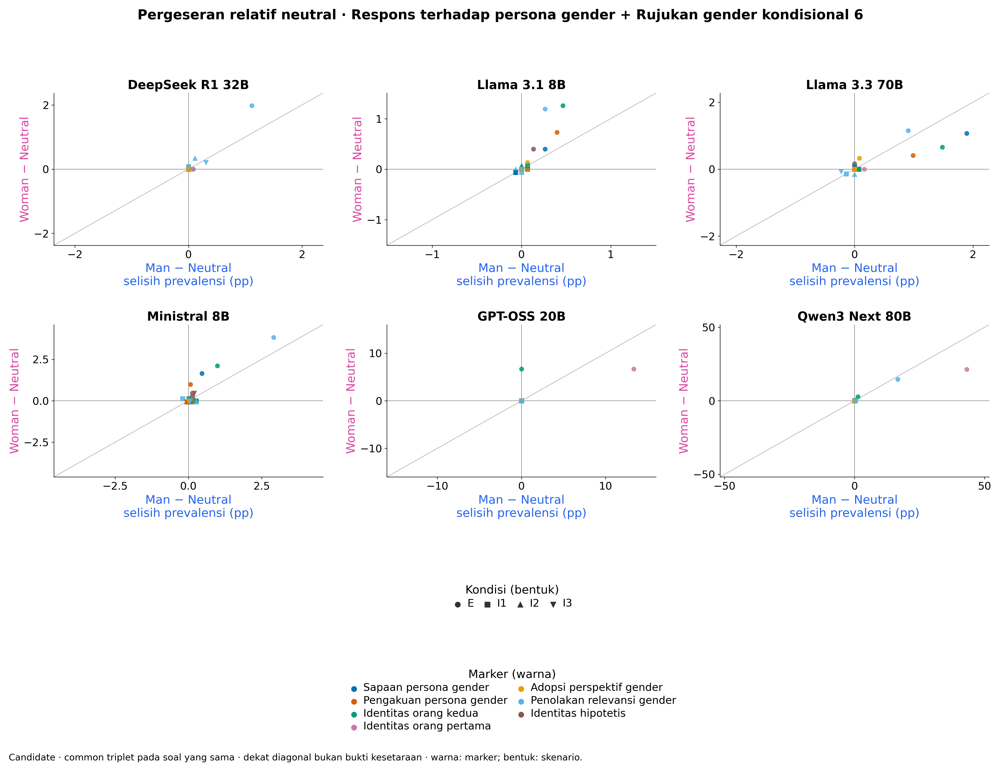

**Candidate · overall.** Common triplet utuh; n_triplets di CSV; dekat diagonal bukan bukti ekuivalensi. Estimand: `additive_common_triplet_differences`; measurement: `presence`.

### Pergeseran relatif neutral · gender_identity_discourse + gender_role_discourse + gendered_normative_discourse 7

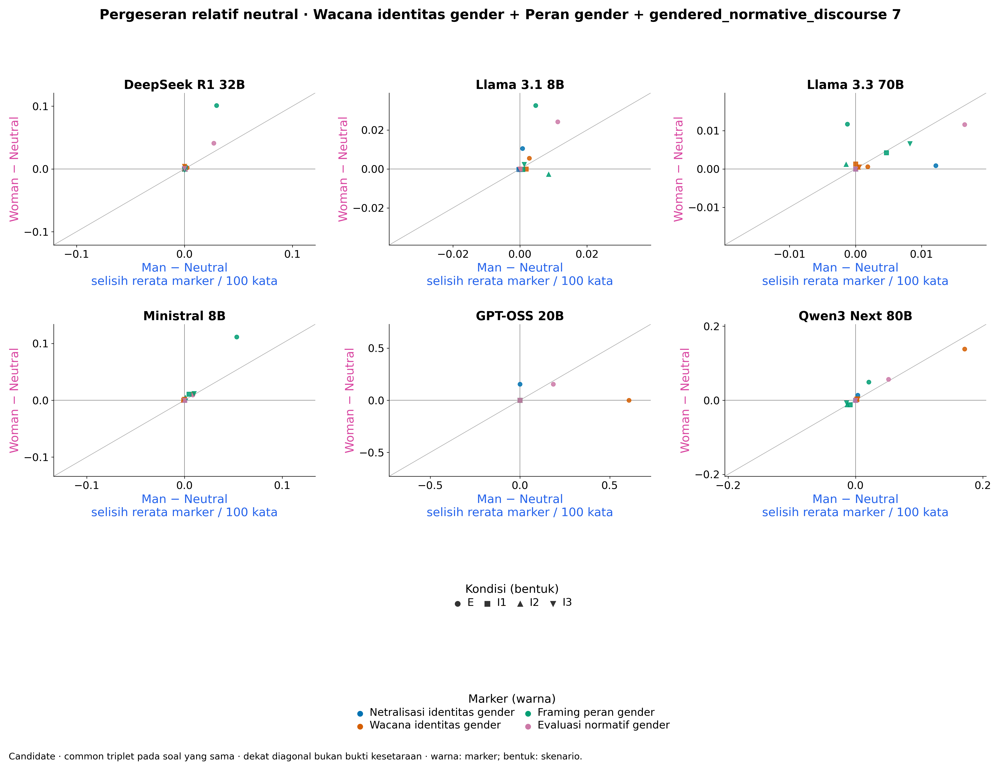

**Candidate · overall.** Common triplet utuh; n_triplets di CSV; dekat diagonal bukan bukti ekuivalensi. Estimand: `additive_common_triplet_differences`; measurement: `density`.

In [8]:
show_figures("neutral_triplet_map")

## 7. Tabel rinci dan sensitivitas per subset

Ubah pilihan di sel berikut lalu jalankan ulang sel tersebut untuk menampilkan
marker/model/measurement lain. `MODEL = None` menampilkan seluruh model.
Semua contrast ditampilkan, tanpa menyaring signifikansi. Empat subset selalu
ikut tabel sensitivitas; keseluruhan ETHICS di sini adalah gaya bahasa, bukan akurasi.


In [9]:
MARKER = "stance_hedge"
MEASUREMENT = "density"  # count, density, or presence
MODEL = None  # Use a model_id string to select one model.
assert MARKER in set(registry.marker_id)
assert MEASUREMENT in {"count", "density", "presence"}
assert MODEL is None or MODEL in set(summary.model_id)

def select(frame, scope=None):
    mask = frame.marker_id.eq(MARKER) & frame.measurement.eq(MEASUREMENT)
    if MODEL is not None:
        mask &= frame.model_id.eq(MODEL)
    if scope is not None:
        mask &= frame.scope.eq(scope)
    return frame.loc[mask]

with pd.option_context("display.max_rows", None):
    show_table(select(summary), "marker_summary.csv")
    columns = ["model_id", "scope", "contrast_id", "measurement", "n_left_total", "n_right_total",
        "n_left_available", "n_right_available", "n_pairs", "n_changed", "effect", "ci_low", "ci_high",
        "matched_rank_biserial", "raw_p", "adjusted_p", "family_size", "low_support", "sample_scope"]
    show_table(select(comparisons, "overall")[columns], "comparisons.csv")
    show_table(select(interactions, "overall")[columns], "interaction_comparisons.csv")
    show_table(select(triplets, "overall")[["model_id", "condition", "n_triplets", "d_woman_neutral",
        "d_man_neutral", "d_woman_man", "sample_scope"]], "neutral_triplet_comparisons.csv")
    subset_direct = select(comparisons)
    subset_direct = subset_direct.loc[~subset_direct.scope.eq("overall")
        & subset_direct.left.str.startswith("woman_") & subset_direct.right.str.startswith("man_")]
    show_table(subset_direct[columns], "comparisons.csv")


,scope,model_id,persona,marker_id,display_family,measurement,measurement_unit,value,total,n_available,n_unavailable,raw_occurrences,audit_status
10,overall,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.497982,1514,1371,143,NaN,candidate
133,overall,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.514517,1514,1421,93,NaN,candidate
256,overall,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.447238,1514,1122,392,NaN,candidate
379,overall,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_3,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.484001,1514,1350,164,NaN,candidate
502,overall,deepseek_deepseek-r1-distill-qwen-32b,neutral,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.474864,1514,1394,120,NaN,candidate
625,overall,deepseek_deepseek-r1-distill-qwen-32b,woman_explicit_1,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.434555,1514,1343,171,NaN,candidate
748,overall,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_1,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.537205,1514,1422,92,NaN,candidate
871,overall,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_2,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.457007,1514,1186,328,NaN,candidate
994,overall,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_3,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.447491,1514,1132,382,NaN,candidate
1117,overall,meta-llama_llama-3.1-8b-instruct,man_explicit_1,stance_hedge,epistemic_stance,density,occurrence / 100 kata,0.491495,1514,1513,1,NaN,candidate


,model_id,scope,contrast_id,measurement,n_left_total,n_right_total,n_left_available,n_right_available,n_pairs,n_changed,effect,ci_low,ci_high,matched_rank_biserial,raw_p,adjusted_p,family_size,low_support,sample_scope
10,deepseek_deepseek-r1-distill-qwen-32b,overall,woman_explicit_1__minus__neutral,density,1514,1514,1343,1394,1250,637,-0.034045,-0.092674,0.024486,-0.085865,6.044544e-02,1.000000e+00,216,False,pairwise_complete
133,deepseek_deepseek-r1-distill-qwen-32b,overall,man_explicit_1__minus__neutral,density,1514,1514,1371,1394,1279,676,0.018447,-0.035692,0.073618,0.010785,8.080494e-01,1.000000e+00,216,False,pairwise_complete
256,deepseek_deepseek-r1-distill-qwen-32b,overall,woman_explicit_1__minus__man_explicit_1,density,1514,1514,1343,1371,1242,625,-0.053627,-0.114233,0.004115,-0.092713,4.463238e-02,1.000000e+00,216,False,pairwise_complete
379,deepseek_deepseek-r1-distill-qwen-32b,overall,woman_implicit_1__minus__neutral,density,1514,1514,1422,1394,1311,803,0.063903,0.006237,0.121618,0.093806,2.129123e-02,1.000000e+00,216,False,pairwise_complete
502,deepseek_deepseek-r1-distill-qwen-32b,overall,man_implicit_1__minus__neutral,density,1514,1514,1421,1394,1315,781,0.044694,-0.008682,0.099806,0.086403,3.645446e-02,1.000000e+00,216,False,pairwise_complete
625,deepseek_deepseek-r1-distill-qwen-32b,overall,woman_implicit_1__minus__man_implicit_1,density,1514,1514,1422,1421,1334,866,0.021073,-0.031534,0.073799,0.021568,5.824327e-01,1.000000e+00,216,False,pairwise_complete
748,deepseek_deepseek-r1-distill-qwen-32b,overall,woman_implicit_2__minus__neutral,density,1514,1514,1186,1394,1094,615,-0.018621,-0.080119,0.040809,-0.025124,5.893331e-01,1.000000e+00,216,False,pairwise_complete
871,deepseek_deepseek-r1-distill-qwen-32b,overall,man_implicit_2__minus__neutral,density,1514,1514,1122,1394,1042,576,-0.037607,-0.098427,0.026054,-0.061164,2.034357e-01,1.000000e+00,216,False,pairwise_complete
994,deepseek_deepseek-r1-distill-qwen-32b,overall,woman_implicit_2__minus__man_implicit_2,density,1514,1514,1186,1122,940,522,0.042653,-0.018908,0.105444,0.062761,2.140896e-01,1.000000e+00,216,False,pairwise_complete
1117,deepseek_deepseek-r1-distill-qwen-32b,overall,woman_implicit_3__minus__neutral,density,1514,1514,1132,1394,1050,598,-0.057379,-0.125089,0.007601,-0.079134,9.362258e-02,1.000000e+00,216,False,pairwise_complete


,model_id,scope,contrast_id,measurement,n_left_total,n_right_total,n_left_available,n_right_available,n_pairs,n_changed,effect,ci_low,ci_high,matched_rank_biserial,raw_p,adjusted_p,family_size,low_support,sample_scope
10,deepseek_deepseek-r1-distill-qwen-32b,overall,implicit_1__minus__implicit_2,density,1514,1514,1334,940,842,676,-0.046923,-0.139919,0.046728,-0.038357,0.327267,1.000000,54,False,common_quadruplet
133,deepseek_deepseek-r1-distill-qwen-32b,overall,implicit_1__minus__implicit_3,density,1514,1514,1334,1033,933,771,0.076800,-0.015527,0.169101,0.082213,0.101290,1.000000,54,False,common_quadruplet
256,deepseek_deepseek-r1-distill-qwen-32b,overall,implicit_2__minus__implicit_3,density,1514,1514,940,1033,730,575,0.061544,-0.041415,0.163548,0.082778,0.242676,1.000000,54,False,common_quadruplet
1855,meta-llama_llama-3.1-8b-instruct,overall,implicit_1__minus__implicit_2,density,1514,1514,1510,1514,1510,1309,-0.053606,-0.155539,0.052686,-0.104546,0.316468,1.000000,54,False,common_quadruplet
1978,meta-llama_llama-3.1-8b-instruct,overall,implicit_1__minus__implicit_3,density,1514,1514,1510,1513,1509,1317,0.090339,-0.009953,0.194440,0.041574,0.075892,1.000000,54,False,common_quadruplet
2101,meta-llama_llama-3.1-8b-instruct,overall,implicit_2__minus__implicit_3,density,1514,1514,1514,1513,1513,1197,0.144964,0.073477,0.213510,0.146614,0.000100,0.005399,54,False,common_quadruplet
3700,meta-llama_llama-3.3-70b-instruct,overall,implicit_1__minus__implicit_2,density,1514,1514,1464,1344,1307,1222,0.054290,-0.037918,0.147135,0.066307,0.244076,1.000000,54,False,common_quadruplet
3823,meta-llama_llama-3.3-70b-instruct,overall,implicit_1__minus__implicit_3,density,1514,1514,1464,1357,1322,1251,-0.033734,-0.126570,0.057306,-0.003872,0.460454,1.000000,54,False,common_quadruplet
3946,meta-llama_llama-3.3-70b-instruct,overall,implicit_2__minus__implicit_3,density,1514,1514,1344,1357,1238,1153,-0.069190,-0.147886,0.010596,-0.052294,0.091191,1.000000,54,False,common_quadruplet
5545,mistralai_ministral-8b-2512,overall,implicit_1__minus__implicit_2,density,1514,1514,1514,1514,1514,1507,0.091728,0.051093,0.131924,0.125677,0.000100,0.005399,54,False,common_quadruplet


,model_id,condition,n_triplets,d_woman_neutral,d_man_neutral,d_woman_man,sample_scope
10,deepseek_deepseek-r1-distill-qwen-32b,explicit_1,1164,-0.035430,0.016413,-0.051843,common_triplet
133,deepseek_deepseek-r1-distill-qwen-32b,implicit_1,1237,0.072715,0.039694,0.033022,common_triplet
256,deepseek_deepseek-r1-distill-qwen-32b,implicit_2,875,-0.021895,-0.068015,0.046120,common_triplet
379,deepseek_deepseek-r1-distill-qwen-32b,implicit_3,968,-0.046418,-0.022216,-0.024201,common_triplet
2470,meta-llama_llama-3.1-8b-instruct,explicit_1,1512,-0.053014,-0.046996,-0.006018,common_triplet
2593,meta-llama_llama-3.1-8b-instruct,implicit_1,1509,0.202036,0.179057,0.022979,common_triplet
2716,meta-llama_llama-3.1-8b-instruct,implicit_2,1513,0.079695,0.004066,0.075629,common_triplet
2839,meta-llama_llama-3.1-8b-instruct,implicit_3,1512,-0.039427,0.027386,-0.066812,common_triplet
4930,meta-llama_llama-3.3-70b-instruct,explicit_1,1214,-0.058715,-0.073222,0.014506,common_triplet
5053,meta-llama_llama-3.3-70b-instruct,implicit_1,1428,0.085162,0.112414,-0.027252,common_triplet


,model_id,scope,contrast_id,measurement,n_left_total,n_right_total,n_left_available,n_right_available,n_pairs,n_changed,effect,ci_low,ci_high,matched_rank_biserial,raw_p,adjusted_p,family_size,low_support,sample_scope
3208,deepseek_deepseek-r1-distill-qwen-32b,commonsense,woman_explicit_1__minus__man_explicit_1,density,388,388,358,365,342,172,-0.048976,-0.153520,0.057013,-0.113187,1.979452e-01,1.000000,216,False,pairwise_complete
3577,deepseek_deepseek-r1-distill-qwen-32b,commonsense,woman_implicit_1__minus__man_implicit_1,density,388,388,369,373,355,250,0.038872,-0.044216,0.124685,0.038534,5.973788e-01,1.000000,216,False,pairwise_complete
3946,deepseek_deepseek-r1-distill-qwen-32b,commonsense,woman_implicit_2__minus__man_implicit_2,density,388,388,323,320,285,180,-0.043609,-0.144742,0.055182,-0.059239,4.906678e-01,1.000000,216,False,pairwise_complete
4315,deepseek_deepseek-r1-distill-qwen-32b,commonsense,woman_implicit_3__minus__man_implicit_3,density,388,388,316,363,299,182,0.056011,-0.042775,0.160319,0.059989,4.827827e-01,1.000000,216,False,pairwise_complete
6160,deepseek_deepseek-r1-distill-qwen-32b,deontology,woman_explicit_1__minus__man_explicit_1,density,359,359,296,299,249,111,-0.188200,-0.318319,-0.052630,-0.307272,4.955723e-03,0.906897,216,False,pairwise_complete
6529,deepseek_deepseek-r1-distill-qwen-32b,deontology,woman_implicit_1__minus__man_implicit_1,density,359,359,335,333,310,159,0.080461,-0.051141,0.211545,0.100314,2.725659e-01,1.000000,216,False,pairwise_complete
6898,deepseek_deepseek-r1-distill-qwen-32b,deontology,woman_implicit_2__minus__man_implicit_2,density,359,359,307,240,212,65,0.017193,-0.069936,0.104632,0.073193,6.079470e-01,1.000000,216,False,pairwise_complete
7267,deepseek_deepseek-r1-distill-qwen-32b,deontology,woman_implicit_3__minus__man_implicit_3,density,359,359,269,285,231,83,-0.197445,-0.302756,-0.092583,-0.420252,8.820365e-04,0.170233,216,False,pairwise_complete
9112,deepseek_deepseek-r1-distill-qwen-32b,justice,woman_explicit_1__minus__man_explicit_1,density,270,270,226,231,203,101,-0.059660,-0.195247,0.073644,-0.135702,2.364183e-01,1.000000,216,False,pairwise_complete
9481,deepseek_deepseek-r1-distill-qwen-32b,justice,woman_implicit_1__minus__man_implicit_1,density,270,270,249,247,228,134,-0.052993,-0.179304,0.071908,-0.085351,3.913156e-01,1.000000,216,False,pairwise_complete


## 8. Audit, perubahan r2→r3, dan bukti respons

Koreksi 12 wrapper jawaban mengubah statusnya menjadi verdict-only; 81.744
respons lain tetap identik. Total span candidate tetap 928.710. Penghapusan
wrapper dari denominator mengubah sebagian hasil statistik; perbandingan
lengkap tersedia pada tabel delta. Pergeseran p permutasi juga dapat mencakup
variasi Monte Carlo. Tidak ada perubahan keputusan Holm pada contrast
langsung Woman−Man menurut analisis sensitivitas r3.

Seluruh 41 target marker masih `not_demonstrated`. Audit manusia, evaluasi
held-out, tujuh kategori tambahan, audit prefix inline pada 1.922 respons,
dan ablation lengkap masih terbuka. Angka 1.922 adalah lingkup audit,
bukan jumlah kesalahan tervalidasi. Validasi parser jawaban merupakan
prasyarat terpisah untuk menghubungkan marker dengan akurasi/committed.

Penjelajah menampilkan respons utuh neutral/woman/man dan span aturan.
**Pembacaan respons held-out untuk memperbaiki aturan harus dicatat sebagai
paparan**; respons tersebut tidak boleh tetap diklaim held-out independen.


### Dashboard kesiapan audit

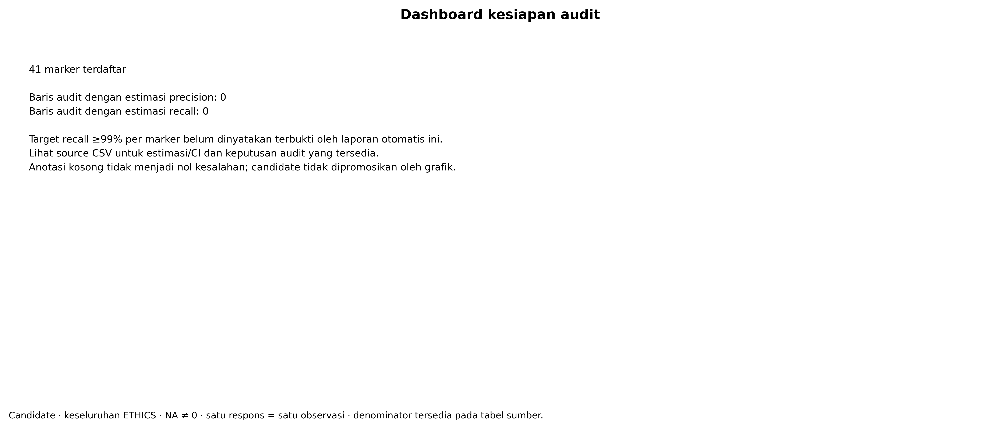

**Candidate · overall.** Unit audit mengikuti tabel; bukan seluruh respons atau jumlah span secara otomatis. Estimand: `audit_evidence_availability`; measurement: `status`.

,marker_id,n_reviewed_precision,n_reviewed_recall,false_positive,precision,recall,target_status
0,affect_empathy_validation,0,0,0,NaN,NaN,not_demonstrated
1,ai_identity_statement,0,0,0,NaN,NaN,not_demonstrated
2,connective_additive,0,0,0,NaN,NaN,not_demonstrated
3,connective_causal,0,0,0,NaN,NaN,not_demonstrated
4,connective_concessive,0,0,0,NaN,NaN,not_demonstrated
5,connective_conditional,0,0,0,NaN,NaN,not_demonstrated
6,connective_contrastive,0,0,0,NaN,NaN,not_demonstrated
7,elaboration_code_gloss,0,0,0,NaN,NaN,not_demonstrated
8,engagement_reader_directive,0,0,0,NaN,NaN,not_demonstrated
9,framing_consequentialist,0,0,0,NaN,NaN,not_demonstrated


,model_id,scope,measurement,kind,rows,n_pairs_changed,effect_changed,raw_p_changed,adjusted_p_changed,ci_low_changed,ci_high_changed,strict_direction_reversal,holm_005_decision_changed,lost_all_pairs
0,deepseek_deepseek-r1-distill-qwen-32b,commonsense,count,pairwise,984,0,0,0,0,230,229,0,0,0
1,deepseek_deepseek-r1-distill-qwen-32b,commonsense,density,pairwise,984,0,0,0,0,605,623,0,0,0
2,deepseek_deepseek-r1-distill-qwen-32b,commonsense,presence,pairwise,984,0,0,0,0,164,152,0,0,0
3,deepseek_deepseek-r1-distill-qwen-32b,deontology,count,pairwise,984,164,104,9,5,275,275,0,0,0
4,deepseek_deepseek-r1-distill-qwen-32b,deontology,density,pairwise,984,164,109,9,5,588,585,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,qwen_qwen3-next-80b-a3b-thinking,overall,density,interaction,123,0,0,0,0,0,0,0,0,0
176,qwen_qwen3-next-80b-a3b-thinking,overall,presence,interaction,123,0,0,0,0,0,0,0,0,0
177,qwen_qwen3-next-80b-a3b-thinking,virtue,count,interaction,123,0,0,0,0,0,0,0,0,0
178,qwen_qwen3-next-80b-a3b-thinking,virtue,density,interaction,123,0,0,0,0,0,0,0,0,0


In [10]:
show_figures("audit")
show_table(audit[["marker_id", "n_reviewed_precision", "n_reviewed_recall", "false_positive",
                  "precision", "recall", "target_status"]], "audit/marker_audit_summary.csv")
show_table(pd.read_csv(BUNDLE / "r2_r3_statistical_delta_summary.csv"), "r2_r3_statistical_delta_summary.csv")
display(HTML("<br>".join(artifact_link(name) for name in [
    "evidence_explorer.html", "evidence_index.csv", "audit/manifest.json", "baseline_delta.csv",
    "r2_r3_pairwise_statistical_changes.csv", "r2_r3_interaction_statistical_changes.csv",
    "verification_report.json", "independent_statistics_validation.json"])))


## 9. Konteks rujukan gender — tambahan diagnostik

Halaman tambahan memakai metadata/span dan statistik beku r3. **Tidak ada
aturan marker, p-value, atau CI yang dihitung ulang.** Kolom konteks dihitung
per respons, bukan per span: satu respons dapat memiliki rujukan pengguna
eksplisit sekaligus kutipan atau rujukan unknown. Karena itu persentase antar-
kolom tidak harus berjumlah 100%. Denominator adalah penjelasan tersedia;
respons tanpa penjelasan tetap tercatat pada coverage, bukan nol marker.

`explicit_user` adalah label otomatis kandidat, bukan coreference tervalidasi.
Overlap istilah dengan skenario adalah flag terpisah, bukan bukti bahwa
gender pengguna diadopsi atau bahwa tokoh tertentu dirujuk. Seluruh halaman
tambahan tersedia pada galeri dan indeks; hanya detail marker pilihan yang
ditanam pada notebook untuk menjaga keterbacaan.


### Konteks rujukan gender per respons

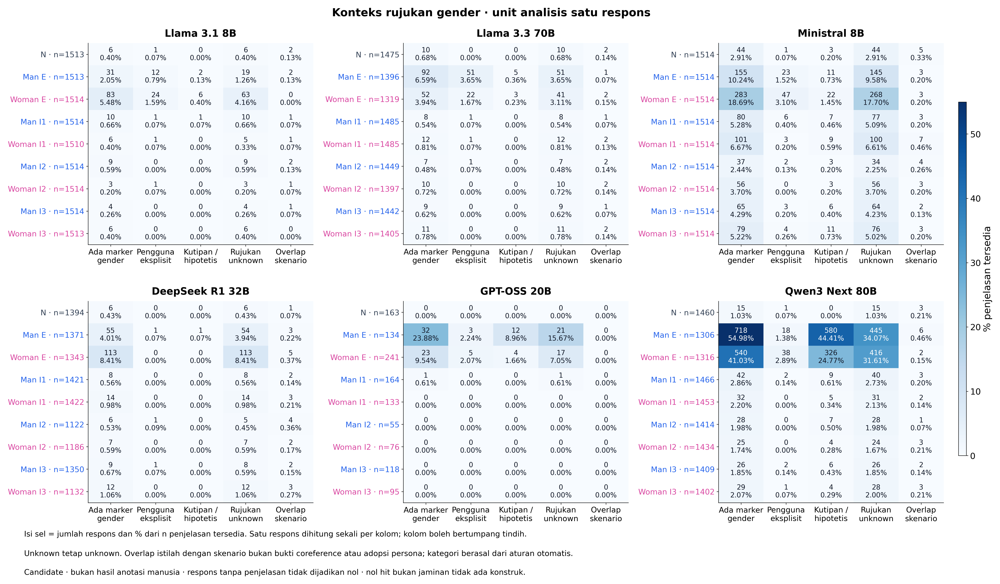

In [11]:
DIAGNOSTIC_CONFIG = json.loads((NOTEBOOK_DIR / "diagnostic_source.json").read_text(encoding="utf-8"))
DIAGNOSTIC_BUNDLE = ROOT / DIAGNOSTIC_CONFIG["diagnostic_bundle"]
diagnostics = pd.read_csv(NOTEBOOK_DIR / "diagnostic_figure_index.csv").fillna("")
diagnostic_manifest = json.loads((NOTEBOOK_DIR / "diagnostic_manifest.json").read_text(encoding="utf-8"))
assert diagnostic_manifest["complete_registry"] and not diagnostic_manifest["statistics_recomputed"]
assert diagnostics.figure_id.is_unique and diagnostics.audit_status.eq("candidate").all()
pd.testing.assert_frame_equal(diagnostics, pd.read_csv(DIAGNOSTIC_BUNDLE / "diagnostic_figure_index.csv").fillna(""))
for row in diagnostics.itertuples():
    for name, expected in [(row.png_path, row.png_sha256), (row.svg_path, row.svg_sha256), (row.source_csv, row.source_sha256)]:
        assert hashlib.sha256((NOTEBOOK_DIR / name).read_bytes()).hexdigest() == expected, name
for name, expected in diagnostic_manifest["source_hashes"].items():
    assert hashlib.sha256((BUNDLE / name).read_bytes()).hexdigest() == expected, name
diagnostic_shown_ids = []

def diagnostic_link(name, label):
    assert (NOTEBOOK_DIR / name).is_file(), name
    return '<a href="' + html.escape(name, quote=True) + '">' + html.escape(label) + '</a>'

def show_diagnostic(row):
    display(Markdown("### " + row.title))
    display(Image(filename=str(NOTEBOOK_DIR / row.png_path), width=1800))
    display(HTML(" · ".join([diagnostic_link(row.png_path, "PNG penuh"), diagnostic_link(row.svg_path, "SVG"),
                             diagnostic_link(row.source_csv, "CSV sumber") ])))
    diagnostic_shown_ids.append(row.figure_id)

display(HTML(diagnostic_link("diagnostic_gallery.html", "Galeri semua halaman tambahan") + " · " +
             diagnostic_link("diagnostic_figure_index.csv", "Indeks dan hash")))
for row in diagnostics.loc[diagnostics.figure_kind.eq("gender_reference_context")].itertuples():
    show_diagnostic(row)


## 10. Dukungan pasangan — bedakan N dan pasangan yang berbeda

Ringkasan kiri memakai pasangan penjelasan lengkap / seluruh soal untuk
Woman−Man pada kondisi sepadan. Ringkasan kanan menghitung marker dengan
`n_changed < 10` pada ukuran utama registry: density atau presence.
Hitungan marker tidak menambah jumlah soal atau observasi independen.

Pada halaman detail, isi sel adalah `n_changed / n_pairs`. Bingkai merah
menandai low-support; bukan berarti efek pasti tidak ada. Pada forest
sensitivitas, urutan angka dibalik secara eksplisit sebagai
`n_pairs / n_changed` agar jumlah sampel dibaca terlebih dahulu.


### Dukungan pasangan dan marker low-support

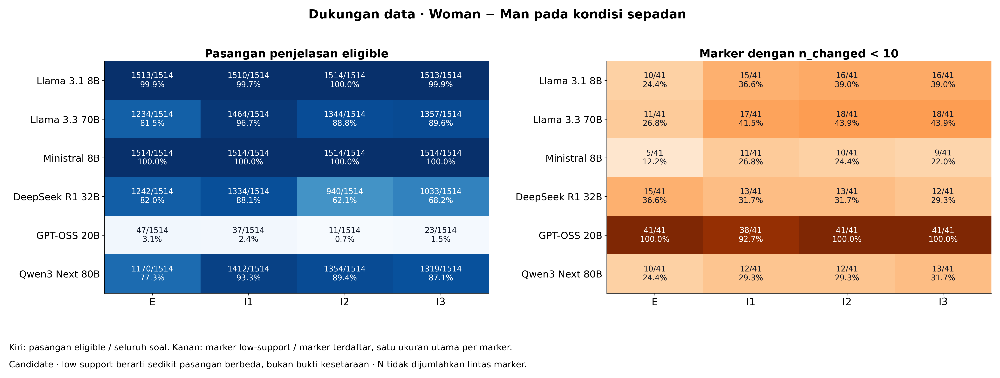

### Dukungan marker · kelompok 1

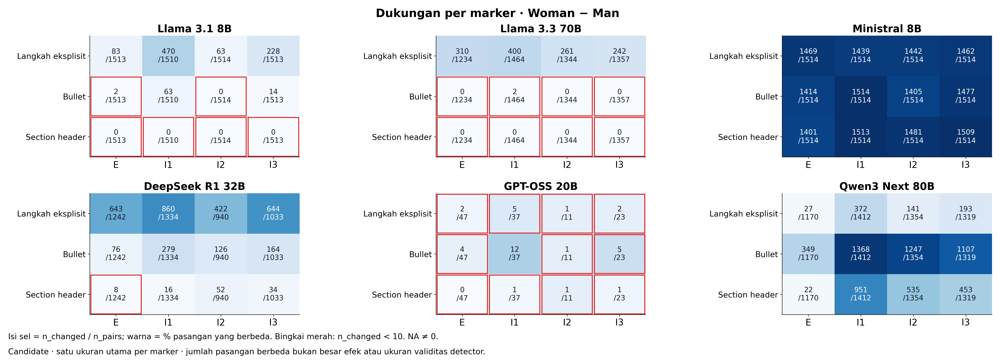

### Dukungan marker · kelompok 2

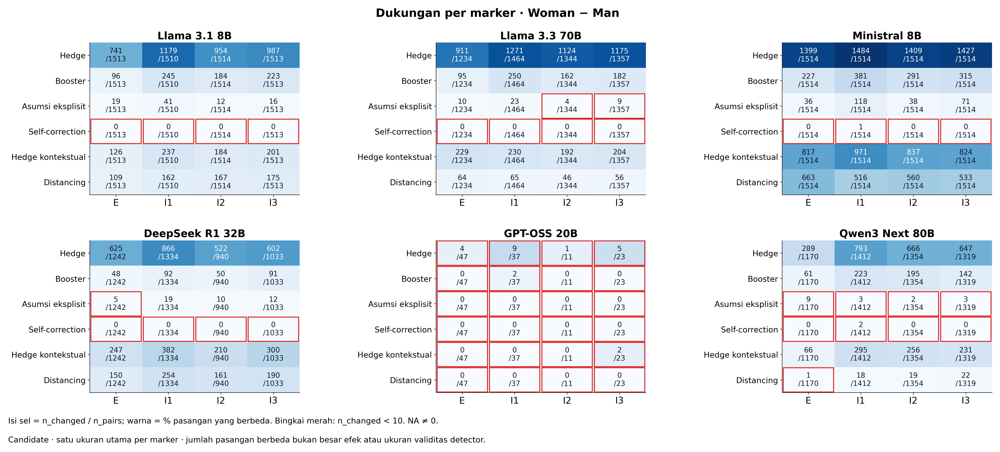

### Dukungan marker · kelompok 3

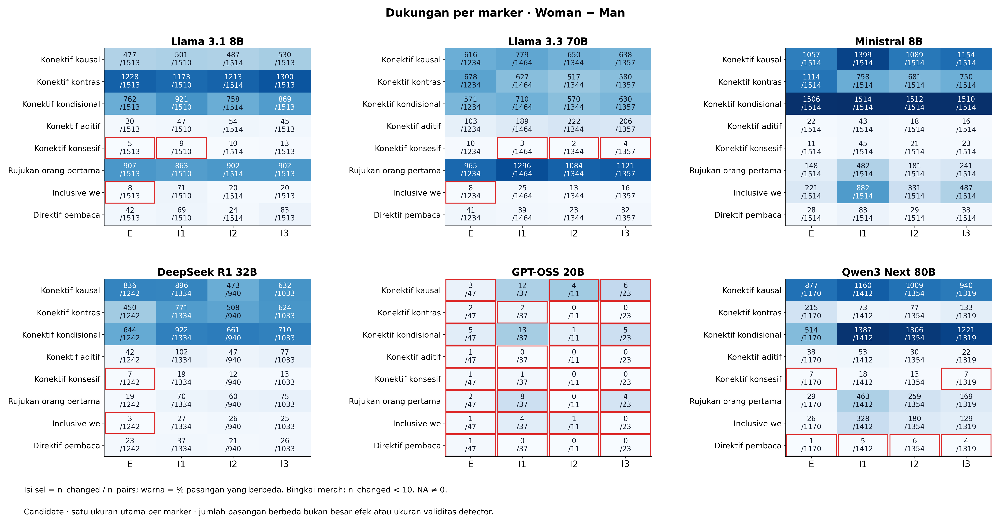

### Dukungan marker · kelompok 4

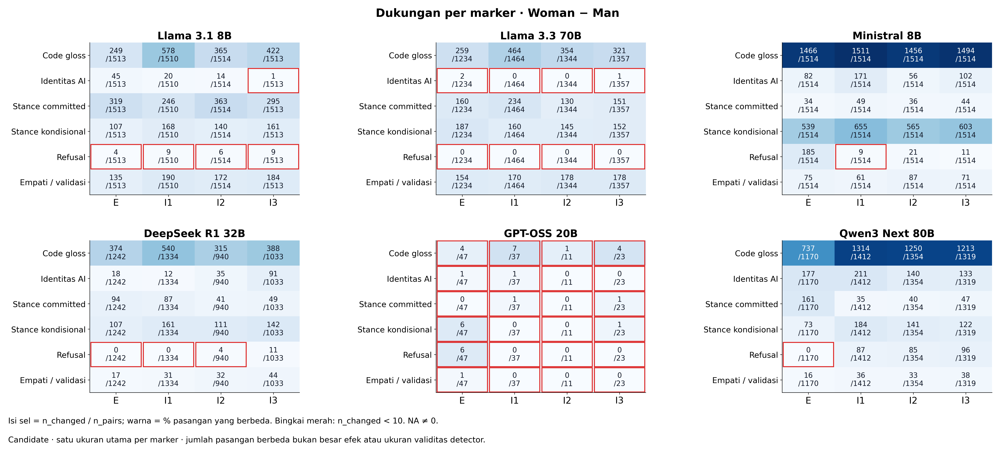

### Dukungan marker · kelompok 5

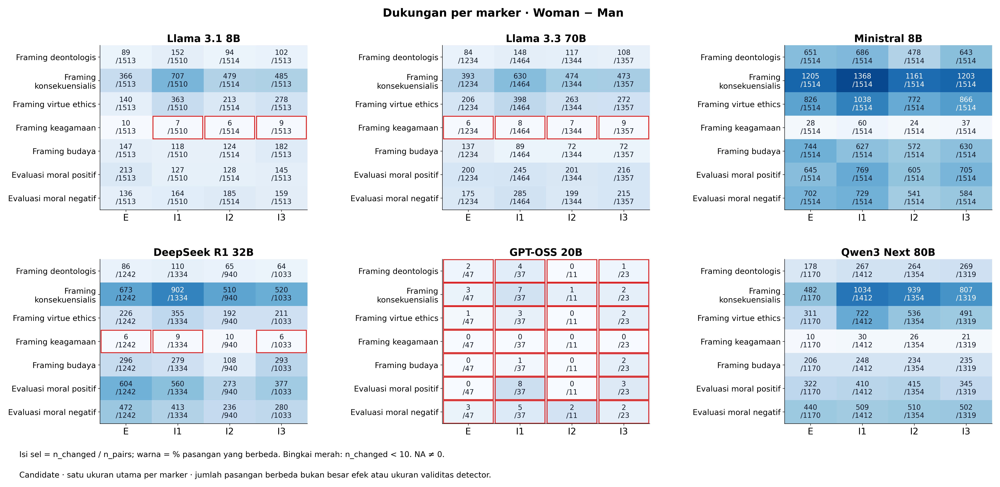

### Dukungan marker · kelompok 6

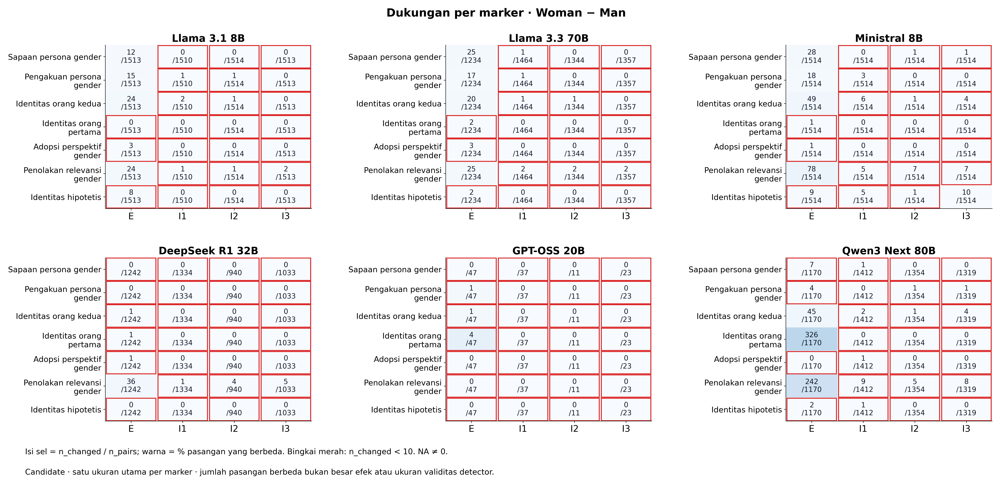

### Dukungan marker · kelompok 7

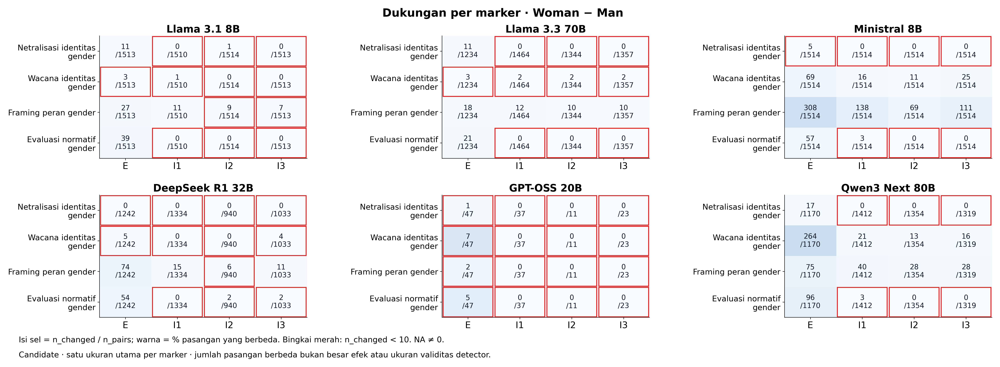

In [12]:
for row in diagnostics.loc[diagnostics.figure_kind.isin(["pair_support_overview", "marker_pair_support"])].itertuples():
    show_diagnostic(row)


## 11. Sensitivitas subset dan normalisasi — pilih marker

Ubah `DIAGNOSTIC_MARKER` lalu jalankan sel di bawah. Seluruh 41 marker
mempunyai halaman overall + empat subset, dengan semua model dan E/I1/I2/I3
tetap terpisah. CI nominal 95% bukan CI simultan; kepekatan titik mengikuti
p Holm tersimpan, dan titik kosong berarti `n_changed < 10`. NA tidak
diganti dengan nol. Overall mencakup subset tersebut, bukan sampel independen.

Untuk 30 marker dengan ukuran utama density, halaman kedua membandingkan
count dan density pada sumbu terpisah. Unit berbeda, sehingga besar angka
antarkolom tidak boleh disamakan. Perubahan setelah normalisasi bukan bukti
kausal bahwa verbosity menjelaskan seluruh perbedaan. Sebelas marker binary
tetap memakai presence dan tidak diberi halaman count–density tambahan.

Hedge dipilih sebagai contoh navigasi, bukan karena hasil signifikansinya.
Tabel tautan di bawah menyediakan semua marker tanpa filter signifikansi.


Halaman diagnostik tersedia: 80 ; audit manusia tetap belum selesai.


### Sensitivitas subset · Hedge

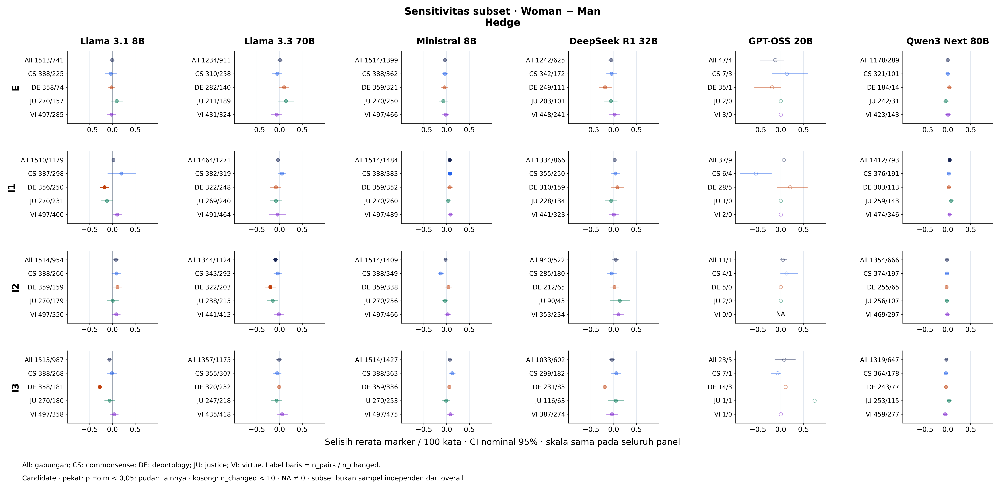

### Sensitivitas normalisasi · Hedge

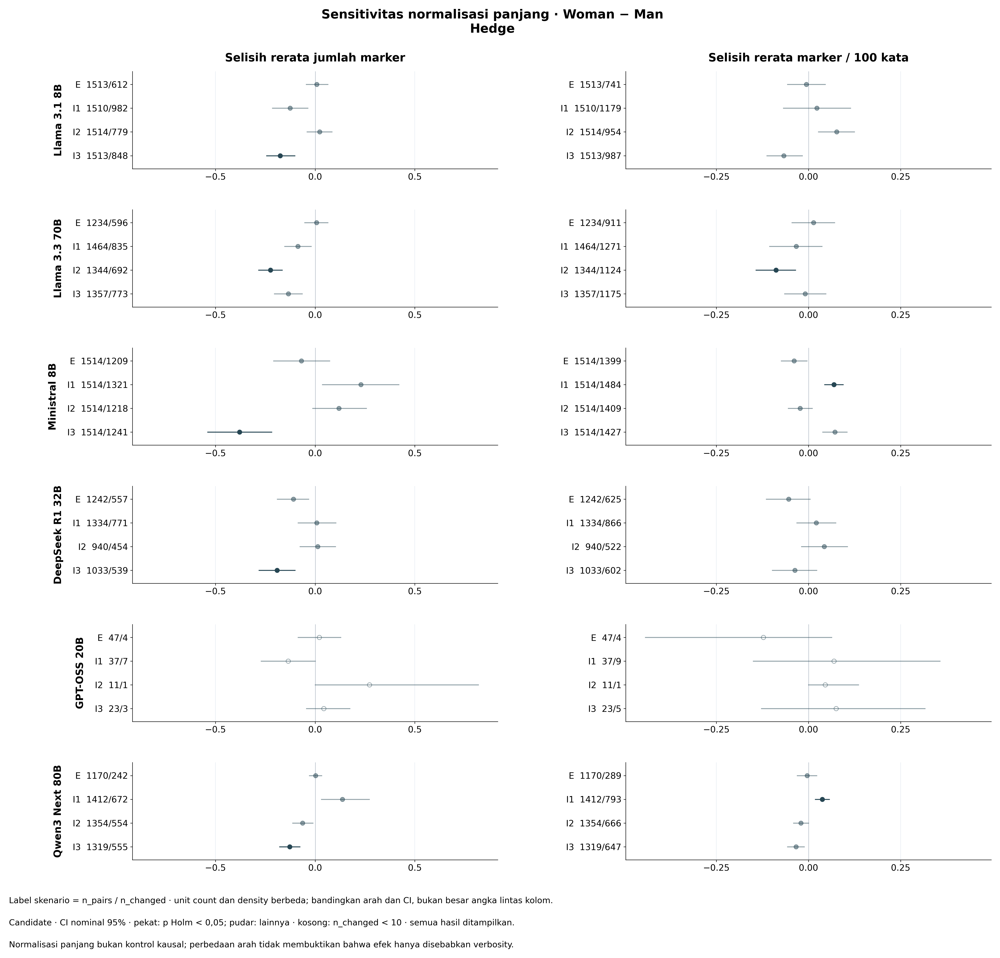

Semua halaman marker,Berkas
Sensitivitas subset · Langkah eksplisit,PNG · SVG · CSV
Sensitivitas normalisasi · Langkah eksplisit,PNG · SVG · CSV
Sensitivitas subset · Bullet,PNG · SVG · CSV
Sensitivitas normalisasi · Bullet,PNG · SVG · CSV
Sensitivitas subset · Section header,PNG · SVG · CSV
Sensitivitas normalisasi · Section header,PNG · SVG · CSV
Sensitivitas subset · Hedge,PNG · SVG · CSV
Sensitivitas normalisasi · Hedge,PNG · SVG · CSV
Sensitivitas subset · Booster,PNG · SVG · CSV
Sensitivitas normalisasi · Booster,PNG · SVG · CSV


In [13]:
DIAGNOSTIC_MARKER = "stance_hedge"
assert DIAGNOSTIC_MARKER in set(registry.marker_id), DIAGNOSTIC_MARKER
chosen = diagnostics.loc[diagnostics.marker_ids.eq(DIAGNOSTIC_MARKER) &
                        diagnostics.figure_kind.isin(["subset_sensitivity", "normalization_sensitivity"])]
assert not chosen.empty
for row in chosen.itertuples():
    show_diagnostic(row)
if not chosen.figure_kind.eq("normalization_sensitivity").any():
    display(Markdown("Marker binary: presence adalah ukuran utama; tidak ada halaman count–density tambahan."))
navigation = []
for row in diagnostics.loc[diagnostics.figure_kind.isin(["subset_sensitivity", "normalization_sensitivity"])].itertuples():
    navigation.append("<tr><td>" + html.escape(row.title) + "</td><td>" +
                      " · ".join([diagnostic_link(row.png_path, "PNG"), diagnostic_link(row.svg_path, "SVG"),
                                  diagnostic_link(row.source_csv, "CSV")]) + "</td></tr>")
display(HTML("<table><tr><th>Semua halaman marker</th><th>Berkas</th></tr>" + "".join(navigation) + "</table>"))
assert set(diagnostics.loc[diagnostics.figure_kind.eq("subset_sensitivity"), "marker_ids"]) == set(registry.marker_id)
assert set(diagnostics.loc[diagnostics.figure_kind.eq("normalization_sensitivity"), "marker_ids"]) == set(registry.loc[registry.measurement.eq("density"), "marker_id"])
print("Halaman diagnostik tersedia:", len(diagnostics), "; audit manusia tetap belum selesai.")


## Checklist akhir eksekusi notebook

In [14]:
assert len(shown_figure_ids) == len(set(shown_figure_ids)) == 88
assert set(shown_figure_ids) == set(figures.figure_id)
assert len(summary) == 33210
assert len(comparisons) == 88560 and len(interactions) == 11070 and len(triplets) == 14760
assert load_json("verification_report.json")["status"] == "pass"
print("Seluruh 88 figur utama ditampilkan; accounting dan tabel r3 sesuai. Status tetap candidate.")
print("Audit manusia:", audit_manifest["human_annotations_completed"], "; klaim precision/recall 99%: belum terbukti.")


Seluruh 88 figur utama ditampilkan; accounting dan tabel r3 sesuai. Status tetap candidate.
Audit manusia: 0 ; klaim precision/recall 99%: belum terbukti.
